# Advanced Portfolio Intelligence Through Semantic Analysis at Low Risk Capital Management

# Part 1 (Talha)

## 1. Environment Setup

Install required libraries for:
- Data processing (pandas)
- Web scraping (BeautifulSoup, Selenium)
- Financial data (yfinance)
- Database (MongoDB)

In [ ]:
!pip install "pymongo[srv]" pandas wikipedia beautifulsoup4 selenium yfinance

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 510.3/510.3 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 56.5 MB/s eta 0:00:00
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11678 sha256=8b29e5a118e9ef0420d3cd462a57f55ae7947b845eda9aa05936c10d20257f5d
  Stored in directory: /root/.cache/pip/wheels/63/47/7c/a9688349aa74d228ce0a9023229c6c0ac52ca2a40fe87679b8
Successfully built wikipedia
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0


## 2. Configuration

Define global variables used across the pipeline.

In [ ]:
# get today date
from datetime import datetime

# today_date = datetime.today().strftime('%Y%m%d')
# today_date
today_date = '20260508'

'20260508'

## 3. MongoDB Connection

We connect to MongoDB to store and update company records.

This enables a **self-healing pipeline**, where:
- resolved records are marked with `wiki_resolver`
- unresolved records are automatically retried in future passes

* Write:
MONGODB_URI_MKHAN=`mongodb+srv://<user>:<password>@<cluster>/

* Read:
MONGODB_URI_MKHAN=`mongodb+srv://<user>:<password>@<cluster>/

In [ ]:
!pip install mongomock -q

from pymongo import MongoClient
from pymongo.server_api import ServerApi
import mongomock
import traceback

from google.colab import userdata
uri = userdata.get('MONGODB_URI_MKHAN')

try:
    # Initialize the client
    client = MongoClient(uri, server_api=ServerApi('1'), serverSelectionTimeoutMS=2000)
    # Verify the connection
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(f"Could not connect to real MongoDB (invalid URI). Falling back to mongomock.\nError: {e}")
    # Fallback to mongomock so downstream code (like database insertion) works without a real DB
    client = mongomock.MongoClient()
    print("Successfully connected to mock MongoDB!")

Pinged your deployment. You successfully connected to MongoDB!


## 4. Data Ingestion: IWB Holdings

We load the iShares Russell 1000 ETF (IWB) holdings as our initial universe of companies.

This dataset provides:
- Ticker symbols
- Company names
- Sector classifications
- Market values and weights

This forms the **base dataset** for enrichment in later steps.

In [ ]:
import urllib.request
import pandas as pd

# Download the iShares Russell 1000 ETF (IWB) holdings CSV
url = 'https://www.ishares.com/us/products/239707/ishares-russell-1000-etf/1467271812596.ajax?fileType=csv&fileName=IWB_holdings&dataType=fund'

try:
    df = pd.read_csv(url, skiprows=9, thousands=',')

    print(f"DataFrame shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"Error reading the CSV: {e}")

DataFrame shape: (1011, 15)


,Ticker,Name,Sector,Asset Class,Market Value,Weight (%),Notional Value,Quantity,Price,Location,Exchange,Currency,FX Rate,Market Currency,Accrual Date
0,NVDA,NVIDIA CORP,Information Technology,Equity,3.477632e+09,7.39,3.477632e+09,16442703.0,211.50,United States,NASDAQ,USD,1.0,USD,-
1,AAPL,APPLE INC,Information Technology,Equity,2.909274e+09,6.18,2.909274e+09,10121327.0,287.44,United States,NASDAQ,USD,1.0,USD,-
2,MSFT,MICROSOFT CORP,Information Technology,Equity,2.192396e+09,4.66,2.192396e+09,5210439.0,420.77,United States,NASDAQ,USD,1.0,USD,-
3,AMZN,AMAZON.COM INC,Consumer Discretionary,Equity,1.827503e+09,3.89,1.827503e+09,6739325.0,271.17,United States,NASDAQ,USD,1.0,USD,-
4,GOOGL,ALPHABET INC CLASS A,Communication,Equity,1.625318e+09,3.46,1.625318e+09,4083816.0,397.99,United States,NASDAQ,USD,1.0,USD,-


In [ ]:
df = df.loc[df['Asset Class'] == 'Equity']
df = df.loc[df['Ticker'].str.len() <= 4]
df = df.loc[~df['Ticker'].str.contains('-| ')]
df = df.drop(columns=[
    'Currency', 'FX Rate', 'Market Currency',
    'Accrual Date', 'Notional Value',
    'Quantity', 'Asset Class'
])

df.columns = df.columns.str.lower().str.replace(' (%)', '').str.replace(' ', '_')
df['holding_date'] = today_date

df.ticker = df.ticker.map(lambda k: {
    'BRKB': 'BRK.B',
    'LENB': 'LEN.B',
    'BFA': 'BF.A',
    'BFB': 'BF.B',
    'HEIA': 'HEI.A',
}.get(k, k))

print(f"Cleaned DataFrame shape: {df.shape}")
display(df.head())

Cleaned DataFrame shape: (988, 9)


,ticker,name,sector,market_value,weight,price,location,exchange,holding_date
0,NVDA,NVIDIA CORP,Information Technology,3.477632e+09,7.39,211.50,United States,NASDAQ,20260508
1,AAPL,APPLE INC,Information Technology,2.909274e+09,6.18,287.44,United States,NASDAQ,20260508
2,MSFT,MICROSOFT CORP,Information Technology,2.192396e+09,4.66,420.77,United States,NASDAQ,20260508
3,AMZN,AMAZON.COM INC,Consumer Discretionary,1.827503e+09,3.89,271.17,United States,NASDAQ,20260508
5,AVGO,BROADCOM INC,Information Technology,1.338597e+09,2.85,412.56,United States,NASDAQ,20260508


In [ ]:
df.shape

(988, 9)

## 5. Database Initialization

Insert cleaned holdings into MongoDB.

A unique composite index is created to prevent duplicate records:
- ticker
- etf_holding_date

In [ ]:
import pymongo
from pymongo.errors import DuplicateKeyError

# Connect to DB and get collection
db = client['etf_data']
collection = db['iwb_holdings']

# Convert DataFrame to list of dictionaries for MongoDB insertion
records = df.to_dict('records')

collection.insert_many(records, ordered=False)

collection.create_index([('ticker', 1), ('etf_holding_date', 1)], unique=True)

print(f"Total documents in collection: {collection.count_documents({})}")


Total documents in collection: 988


## 6. Pass 1: Wikipedia Resolver

Primary resolution using the `wikipedia` Python library.

### Steps:
1. Search Wikipedia
2. Extract page content
3. Parse infobox (vCard)
4. Validate ticker match
5. Store results in MongoDB

In [ ]:
import re
import time
import random
import pandas as pd
import wikipedia
import yfinance as yf

from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.chrome.options import Options
from pymongo import MongoClient

def clean_wiki_content(content):
    """
    Cleans Wikipedia content by removing citations,
    structural noise, and extra whitespace.
    """

    if not content:
        return ""

    # Remove citation markers [1], [23], etc.
    content = re.sub(r'\[\d+\]', '', content)

    # Remove editorial notes
    content = re.sub(r'\[[a-zA-Z\s]+\]', '', content)

    # Remove end sections
    end_sections = [
        'See also',
        'References',
        'External links',
        'Further reading',
        'Notes',
        'Citations'
    ]

    for section in end_sections:
        content = re.split(
            rf'\n==\s*{section}\s*==\n',
            content,
            flags=re.IGNORECASE
        )[0]

    # Normalize whitespace
    content = re.sub(r'\n{3,}', '\n\n', content)

    return content.strip()


def parse_vcard(html_content):
    """
    Parses the Wikipedia infobox/vcard.
    """

    soup = BeautifulSoup(html_content, 'html.parser')

    infobox = soup.find('table', class_=['infobox', 'vcard'])

    if not infobox:
        return {}

    vcard_data = {}

    for row in infobox.find_all('tr'):

        header = row.find('th')
        data = row.find('td')

        if header and data:

            key = header.get_text(strip=True).replace('\xa0', ' ')
            value = data.get_text(
                separator=' ',
                strip=True
            ).replace('\xa0', ' ')

            value = re.sub(r'\[\d+\]', '', value)

            if key and value:
                vcard_data[key] = value

    return vcard_data

def safe_wikipedia_search(query, retries=3, delay=1.5):
    for attempt in range(retries):
        try:
            results = wikipedia.search(query, results=1)
            if results:
                return results[0]
            return None
        except Exception as e:
            print(f"[WARN] search failed for '{query}' on attempt {attempt+1}: {e}")
            time.sleep(delay)
    return None


# =========================================================
# Wikipedia Fetcher
# =========================================================

def fetch_wikipedia_data(company_name, ticker, url=""):
    """
    Fetches Wikipedia page data.
    """

    # -----------------------------------------------------
    # Step 1: Determine page title
    # -----------------------------------------------------

    if url:

        try:
            page_title = url.split("/wiki/")[-1]

            if not page_title:
                raise ValueError("Invalid URL format")

            print(f"[INFO] Using URL title: {page_title}")

        except Exception as e:
            print(f"[FAIL] URL parse failed: {e}")
            return None, None, None

    else:

        print(f"[INFO] Searching Wikipedia for: {company_name}")

        try:
            search_results = wikipedia.search(
                company_name,
                results=1
            )

            if not search_results:
                print(f"[FAIL] No search result")
                return None, None, None

            page_title = search_results[0]

        except Exception as e:
            print(f"[FAIL] Search failed: {e}")
            return None, None, None

    # -----------------------------------------------------
    # Step 2: Load page
    # -----------------------------------------------------

    try:

        page = wikipedia.page(
            page_title,
            auto_suggest=False,
            redirect=True
        )

    except wikipedia.exceptions.PageError:
        print(f"[FAIL] PageError for {page_title}")
        return None, None, None

    except wikipedia.exceptions.DisambiguationError as e:
        print(f"[FAIL] Ambiguous page: {e}")
        return None, None, None

    except Exception as e:
        print(f"[FAIL] Unknown error: {e}")
        return None, None, None

    # -----------------------------------------------------
    # Step 3: Parse data
    # -----------------------------------------------------

    url = page.url

    vcard_dict = parse_vcard(page.html())

    cleaned_content = clean_wiki_content(page.content)

    # -----------------------------------------------------
    # Step 4: Validate ticker
    # -----------------------------------------------------

    traded_as = vcard_dict.get("Traded as", "")

    ticker_dot = ticker.upper()
    ticker_dash = ticker.replace(".", "-").upper()

    if (
        ticker_dot not in traded_as
        and ticker_dash not in traded_as
    ):
        print(f"[FAIL] Ticker validation failed")
        return None, None, None

    return url, vcard_dict, cleaned_content


### 6.1 Execute Pass 1

Resolve the majority of companies using Wikipedia search.

In [ ]:
wikipedia.set_user_agent('LRCM_Project (<email>)')

# Query MongoDB for unresolved documents and load into a Pandas DataFrame
print("Querying database for unresolved documents...")
todo_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": False}}))

if todo_df.empty:
    print("No unresolved documents found. Pass 1 complete!")
else:
    print(f"Found {len(todo_df)} unresolved documents to process.\n")

    # Iterate over the DataFrame (using itertuples for efficiency)
    for row in todo_df.itertuples():
        ticker = row.ticker
        company_name = row.name

        print(f"Processing: {ticker} ({company_name})")

        try:
            # Call your fetcher function
            url, vcard, content = fetch_wikipedia_data(company_name, ticker)

            if url:
                # Build the document payload
                doc = {
                    'wiki_url': url,
                    'wiki_content': content,
                    'wiki_vcard': vcard,
                    'wiki_resolver': 'wikipedia'
                }

                # Update the database using the composite key from step 1.2
                collection.update_one(
                    {'ticker': ticker, 'holding_date': row.holding_date},
                    {'$set': doc}
                )
                print(f"  [SUCCESS] Stored Wikipedia data for {ticker}")
            else:
                print(f"  [SKIP] No valid Wikipedia data found for {ticker}")

        except Exception as e:
            print(f"  [ERROR] Unhandled exception for {ticker}: {e}")

        # Be polite to Wikipedia's servers
        time.sleep(0.3)

print("\nFinished processing Pass 1.")

Querying database for unresolved documents...
Found 120 unresolved documents to process.

Processing: LLY (ELI LILLY)
[INFO] Searching Wikipedia for: ELI LILLY
[FAIL] Ticker validation failed
  [SKIP] No valid Wikipedia data found for LLY
Processing: KO (COCA-COLA)
[INFO] Searching Wikipedia for: COCA-COLA
[FAIL] Ticker validation failed
  [SKIP] No valid Wikipedia data found for KO
Processing: MCD (MCDONALDS CORP)
[INFO] Searching Wikipedia for: MCDONALDS CORP
  [SUCCESS] Stored Wikipedia data for MCD
Processing: DIS (WALT DISNEY)
[INFO] Searching Wikipedia for: WALT DISNEY
[FAIL] Ticker validation failed
  [SKIP] No valid Wikipedia data found for DIS
Processing: CB (CHUBB)
[INFO] Searching Wikipedia for: CHUBB


/usr/local/lib/python3.12/dist-packages/wikipedia/wikipedia.py:389: GuessedAtParserWarning: No parser was explicitly specified, so I'm using the best available HTML parser for this system ("lxml"). This usually isn't a problem, but if you run this code on another system, or in a different virtual environment, it may use a different parser and behave differently.

The code that caused this warning is on line 389 of the file /usr/local/lib/python3.12/dist-packages/wikipedia/wikipedia.py. To get rid of this warning, pass the additional argument 'features="lxml"' to the BeautifulSoup constructor.

  lis = BeautifulSoup(html).find_all('li')


[FAIL] Ambiguous page: "Chubb" may refer to: 
Chubb (surname)
Timothy O'Connor (Irish politician)
Chubb Rock
Chubb Limited
Chubb Locks
Chubb Fire & Security
Pingualuit crater
Chubb detector lock
Squalius cephalus
HMS Chub
Chubb illusion
Chub (disambiguation)
Chubbtown, Georgia
  [SKIP] No valid Wikipedia data found for CB
Processing: SO (SOUTHERN)
[INFO] Searching Wikipedia for: SOUTHERN
[FAIL] Ambiguous page: "Southern" may refer to: 
China Southern Airlines
Southern Airways
Southern Air
Southern Airways Express
Southern Company
Southern Music
Southern Railway (disambiguation)
Southern Records
Southern Studios
Southern Television
Southern (Govia Thameslink Railway)
88.3 Southern FM
Heart Sussex
Southern Media Corporation
Nanfang Daily
Southern Broadcasting Network
Southern Weekly
The Southern Illinoisan
Southern Command Network
Southern (band)
The Pacific Age
Southern (surname)
Southern University
Southern University at New Orleans
Southern University at Shreveport
Southern University

In [ ]:
todo_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": False}}))

todo_df.shape

(116, 10)

In [ ]:
done_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": True}}))
s = done_df.wiki_url.value_counts()
s[s > 1]


,count
wiki_url,
https://en.wikipedia.org/wiki/Brown-Forman,2
https://en.wikipedia.org/wiki/Zillow,2
https://en.wikipedia.org/wiki/Fox_Corporation,2
https://en.wikipedia.org/wiki/News_Corp,2
https://en.wikipedia.org/wiki/CrowdStrike,2
https://en.wikipedia.org/wiki/Under_Armour,2
https://en.wikipedia.org/wiki/Lennar,2


## 7. Data Quality Check (DQ)

The Wikipedia resolver can return incorrect pages due to:
- ambiguous company names
- ticker mismatches

### Strategy:
- Normalize company name and content
- Detect mismatches
- "Heal" by unsetting `wiki_resolver`

In [ ]:
import re

STOPWORDS = {
    "inc", "incorporated", "corp", "corporation", "co", "company",
    "class", "a", "b", "the", "ltd", "limited", "holdings", "holding", "group"
}

def normalize(text):
    if not text:
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z0-9]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def ticker_ok(doc):
    ticker = str(doc.get("ticker", "")).upper()
    traded_as = str(doc.get("wiki_vcard", {}).get("Traded as", ""))

    if not ticker or not traded_as:
        return False

    # Special case: single-letter tickers like S
    # Avoid false matches inside strings like S&P
    if len(ticker) == 1:
        return re.search(
            rf'(?i)(?<![A-Z0-9]){re.escape(ticker)}(?![A-Z0-9&])',
            traded_as
        ) is not None

    # Normal case: compare cleaned ticker against cleaned traded_as
    ticker_clean = ticker.replace(".", "").replace("-", "").lower()
    traded_clean = normalize(traded_as).replace(" ", "")
    return ticker_clean in traded_clean

def name_ok(doc):
    name = normalize(doc.get("name", ""))
    content = normalize(doc.get("wiki_content", ""))

    if not name or not content:
        return False

    tokens = [t for t in name.split() if t not in STOPWORDS]
    if not tokens:
        return False

    # Check first 1–2 meaningful tokens only
    return any(tok in content for tok in tokens[:2])

mismatched_docs = []

for doc in collection.find({"wiki_resolver": {"$exists": True}}):
    if ticker_ok(doc) or name_ok(doc):
        continue

    print(f"[DQ FAIL] {doc.get('ticker')} | {doc.get('name')}")
    mismatched_docs.append(doc)



[DQ FAIL] S | SENTINELONE INC CLASS A


In [ ]:
for doc in mismatched_docs:
    collection.update_one(
        {"_id": doc["_id"]},
        {
            "$unset": {
                "wiki_resolver": "",
                "wiki_url": "",
                "wiki_content": "",
                "wiki_vcard": ""
            }
        }
    )

In [ ]:
todo_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": False}}))

todo_df.shape

(117, 10)

## 8. Pass 2: Bing + Selenium Resolver

Fallback for unresolved companies.

### Strategy:
- Use Selenium to search Bing
- Extract Wikipedia URLs
- Decode Bing redirect links
- Validate using existing pipeline

In [ ]:
!pip install -q selenium google-colab-selenium

In [ ]:
import re
import time
import base64
from urllib.parse import quote, urlparse, parse_qs, unquote
import google_colab_selenium as gs
from selenium.webdriver.common.by import By

def unwrap_bing_url(href):
    if not href:
        return None

    href = href.strip()

    # direct Wikipedia link
    if "wikipedia.org/wiki/" in href:
        return href

    # Bing redirect link
    if "bing.com/ck/a" in href:
        try:
            qs = parse_qs(urlparse(href).query)
            u = qs.get("u", [None])[0]
            if not u:
                return None

            u = unquote(u)

            # Bing often prefixes the encoded payload with "a1"
            if u.startswith("a1"):
                u = u[2:]

            pad = "=" * (-len(u) % 4)
            decoded = base64.urlsafe_b64decode(u + pad).decode("utf-8", errors="ignore")

            if "wikipedia.org/wiki/" in decoded:
                return decoded

        except Exception:
            return None

    return None


def search_bing(query, debug=False):
    driver = gs.Chrome()
    try:
        url = f"https://www.bing.com/search?q={quote(query)}"
        driver.get(url)
        time.sleep(3)

        if debug:
            print("TITLE:", driver.title)
            print("URL:", driver.current_url)

        for a in driver.find_elements(By.CSS_SELECTOR, "li.b_algo h2 a, li.b_algo a, a[href]"):
            href = a.get_attribute("href") or ""
            final_url = unwrap_bing_url(href)
            if final_url and "wikipedia.org/wiki/" in final_url:
                return final_url

        return None
    finally:
        driver.quit()

In [ ]:
print(search_bing("SENTINELONE INC CLASS A Wikipedia"))

<IPython.core.display.Javascript object>

https://en.wikipedia.org/wiki/SentinelOne


In [ ]:
print(search_bing(f'ELI LILLY Company'))

<IPython.core.display.Javascript object>

https://en.wikipedia.org/wiki/Eli_Lilly_and_Company


### 8.1 Execute Pass 2

Attempt resolution for remaining companies using Bing search.

In [ ]:
import re
import time
import random
import pandas as pd
import wikipedia
import yfinance as yf

from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.chrome.options import Options
from pymongo import MongoClient

def clean_wiki_content(content):
    """
    Cleans Wikipedia content by removing citations,
    structural noise, and extra whitespace.
    """

    if not content:
        return ""

    # Remove citation markers [1], [23], etc.
    content = re.sub(r'\[\d+\]', '', content)

    # Remove editorial notes
    content = re.sub(r'\[[a-zA-Z\s]+\]', '', content)

    # Remove end sections
    end_sections = [
        'See also',
        'References',
        'External links',
        'Further reading',
        'Notes',
        'Citations'
    ]

    for section in end_sections:
        content = re.split(
            rf'\n==\s*{section}\s*==\n',
            content,
            flags=re.IGNORECASE
        )[0]

    # Normalize whitespace
    content = re.sub(r'\n{3,}', '\n\n', content)

    return content.strip()


def parse_vcard(html_content):
    """
    Parses the Wikipedia infobox/vcard.
    """

    soup = BeautifulSoup(html_content, 'html.parser')

    infobox = soup.find('table', class_=['infobox', 'vcard'])

    if not infobox:
        return {}

    vcard_data = {}

    for row in infobox.find_all('tr'):

        header = row.find('th')
        data = row.find('td')

        if header and data:

            key = header.get_text(strip=True).replace('\xa0', ' ')
            value = data.get_text(
                separator=' ',
                strip=True
            ).replace('\xa0', ' ')

            value = re.sub(r'\[\d+\]', '', value)

            if key and value:
                vcard_data[key] = value

    return vcard_data

def safe_wikipedia_search(query, retries=3, delay=1.5):
    for attempt in range(retries):
        try:
            results = wikipedia.search(query, results=1)
            if results:
                return results[0]
            return None
        except Exception as e:
            print(f"[WARN] search failed for '{query}' on attempt {attempt+1}: {e}")
            time.sleep(delay)
    return None


# =========================================================
# Wikipedia Fetcher
# =========================================================

def fetch_wikipedia_data(company_name, ticker, url=""):
    """
    Fetches Wikipedia page data.
    """

    # -----------------------------------------------------
    # Step 1: Determine page title
    # -----------------------------------------------------

    if url:

        try:
            page_title = url.split("/wiki/")[-1]

            if not page_title:
                raise ValueError("Invalid URL format")

            print(f"[INFO] Using URL title: {page_title}")

        except Exception as e:
            print(f"[FAIL] URL parse failed: {e}")
            return None, None, None

    else:

        print(f"[INFO] Searching Wikipedia for: {company_name}")

        try:
            search_results = wikipedia.search(
                company_name,
                results=1
            )

            if not search_results:
                print(f"[FAIL] No search result")
                return None, None, None

            page_title = search_results[0]

        except Exception as e:
            print(f"[FAIL] Search failed: {e}")
            return None, None, None

    # -----------------------------------------------------
    # Step 2: Load page
    # -----------------------------------------------------

    try:

        page = wikipedia.page(
            page_title,
            auto_suggest=False,
            redirect=True
        )

    except wikipedia.exceptions.PageError:
        print(f"[FAIL] PageError for {page_title}")
        return None, None, None

    except wikipedia.exceptions.DisambiguationError as e:
        print(f"[FAIL] Ambiguous page: {e}")
        return None, None, None

    except Exception as e:
        print(f"[FAIL] Unknown error: {e}")
        return None, None, None

    # -----------------------------------------------------
    # Step 3: Parse data
    # -----------------------------------------------------

    url = page.url

    vcard_dict = parse_vcard(page.html())

    cleaned_content = clean_wiki_content(page.content)

    # -----------------------------------------------------
    # Step 4: Validate ticker
    # -----------------------------------------------------
    print("\n[DEBUG] PAGE TITLE:", page.title)
    print("[DEBUG] URL:", page.url)

    print("\n[DEBUG] VCARDS KEYS:", list(vcard_dict.keys()))
    print("[DEBUG] TRADED AS RAW:", vcard_dict.get("Traded as", ""))

    traded_as = vcard_dict.get("Traded as", "")

    ticker_dot = ticker.upper()
    ticker_dash = ticker.replace(".", "-").upper()

    print("[DEBUG] ticker_dot:", ticker_dot)
    print("[DEBUG] ticker_dash:", ticker_dash)

    print("[DEBUG] ticker_dot in traded_as:", ticker_dot in traded_as)
    print("[DEBUG] ticker_dash in traded_as:", ticker_dash in traded_as)
    traded_as = vcard_dict.get("Traded as", "")

    ticker_dot = ticker.upper()
    ticker_dash = ticker.replace(".", "-").upper()

    if (
        ticker_dot not in traded_as
        and ticker_dash not in traded_as
    ):
        print(f"[FAIL] Ticker validation failed")
        return None, None, None

    return url, vcard_dict, cleaned_content


In [ ]:
todo_docs = list(collection.find({"wiki_resolver": {"$exists": False}}))

for doc in todo_docs:
    try:
        query = f"{doc['name']} Wikipedia"
        wiki_url = search_bing(query)

        if not wiki_url:
            print(f"[BING FAIL] {doc['ticker']} | {doc['name']}")
            continue

        url, vcard, content = fetch_wikipedia_data(doc["name"], doc["ticker"], url=wiki_url)

        if url:
            collection.update_one(
                {"_id": doc["_id"]},
                {"$set": {
                    "wiki_url": url,
                    "wiki_content": content,
                    "wiki_vcard": vcard,
                    "wiki_resolver": "bing"
                }}
            )
            print(f"[SUCCESS] {doc['ticker']}")
        else:
            print(f"[VALIDATION FAIL] {doc['ticker']}")

    except Exception as e:
        print(f"[ERROR] {doc['ticker']}: {e}")

    time.sleep(0.5)

In [ ]:
todo_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": False}}))

todo_df.shape

(109, 10)

In [ ]:
todo_df.sort_values('market_value')

,_id,ticker,name,sector,market_value,weight,price,location,exchange,holding_date
108,69fe64ac817f1677550e7bf9,FRMI,FERMI INC,Real Estate,1.219584e+05,0.00,5.12,United States,NASDAQ,20260508
107,69fe64ac817f1677550e7bf7,INGM,INGRAM MICRO HOLDING CORP,Information Technology,3.348539e+05,0.00,26.87,United States,NYSE,20260508
106,69fe64ac817f1677550e7bf6,NIQ,NIQ GLOBAL INTELLIGENCE PLC,Communication,3.733296e+05,0.00,11.20,United States,NYSE,20260508
105,69fe64ac817f1677550e7bf5,CBC,CENTRAL BANCOMPANY INC CLASS A,Financials,3.910626e+05,0.00,27.37,United States,NASDAQ,20260508
104,69fe64ac817f1677550e7bf4,UWMC,UWM HOLDINGS CORP CLASS A,Financials,4.143103e+05,0.00,3.38,United States,NYSE,20260508
...,...,...,...,...,...,...,...,...,...,...
4,69fe64ac817f1677550e788a,SO,SOUTHERN,Utilities,7.163260e+07,0.15,92.43,United States,NYSE,20260508
3,69fe64ac817f1677550e7879,CB,CHUBB,Financials,8.247097e+07,0.18,321.28,United States,NYSE,20260508
2,69fe64ac817f1677550e7853,DIS,WALT DISNEY,Communication,1.356483e+08,0.29,108.66,United States,NYSE,20260508
1,69fe64ac817f1677550e783f,KO,COCA-COLA,Consumer Staples,2.141632e+08,0.46,78.43,United States,NYSE,20260508


### Extra credits
We will get disney here

In [ ]:
def get_bing_queries(doc):
    name = doc["name"].strip()
    exch = doc["exchange"].strip()
    ticker = doc["ticker"].strip()

    return [
        f'{name} Company',
        f'{name} Company {ticker} {exch}',
    ]

In [ ]:
def search_bing_with_retry(query, retries=3, delay=1):
    for attempt in range(retries):
        wiki_url = search_bing(query)

        if wiki_url:
            return wiki_url

        print(f"[RETRY {attempt+1}] No result, retrying...")
        time.sleep(delay)

    return None

todo_docs = list(collection.find({"wiki_resolver": {"$exists": False}}))

for doc in todo_docs:
    try:
        print(f"\n[PROCESS] {doc['ticker']} | {doc['name']}")

        wiki_url = None
        for query in get_bing_queries(doc):
            print(f"[QUERY] {query}")
            wiki_url = search_bing_with_retry(query)
            print(f"[BING URL] {wiki_url}")
            if wiki_url:
                break

        if not wiki_url:
            print(f"[BING FAIL] {doc['ticker']} | {doc['name']}")
            continue

        url, vcard, content = fetch_wikipedia_data(doc["name"], doc["ticker"], url=wiki_url)

        if url:
            collection.update_one(
                {"_id": doc["_id"]},
                {"$set": {
                    "wiki_url": url,
                    "wiki_content": content,
                    "wiki_vcard": vcard,
                    "wiki_resolver": "bing"
                }}
            )
            print(f"[SUCCESS] {doc['ticker']}")
        else:
            print(f"[VALIDATION FAIL] {doc['ticker']}")

    except Exception as e:
        print(f"[ERROR] {doc['ticker']}: {e}")

    time.sleep(0.5)


[PROCESS] LLY | ELI LILLY
[QUERY] ELI LILLY Company


<IPython.core.display.Javascript object>

[BING URL] https://en.wikipedia.org/wiki/Eli_Lilly_and_Company
[INFO] Using URL title: Eli_Lilly_and_Company

[DEBUG] PAGE TITLE: Eli Lilly and Company
[DEBUG] URL: https://en.wikipedia.org/wiki/Eli_Lilly_and_Company

[DEBUG] VCARDS KEYS: ['Company type', 'Traded as', 'ISIN', 'Industry', 'Founded', 'Founder', 'Headquarters', 'Key people', 'Products', 'Revenue', 'Operating income', 'Net income', 'Total assets', 'Total equity', 'Owner', 'Number of employees', 'Website']
[DEBUG] TRADED AS RAW: NYSE : LLY S&P 100 component S&P 500 component
[DEBUG] ticker_dot: LLY
[DEBUG] ticker_dash: LLY
[DEBUG] ticker_dot in traded_as: True
[DEBUG] ticker_dash in traded_as: True
[SUCCESS] LLY

[PROCESS] KO | COCA-COLA
[QUERY] COCA-COLA Company


<IPython.core.display.Javascript object>

[RETRY 1] No result, retrying...


<IPython.core.display.Javascript object>

... (89 outputs left out)

<IPython.core.display.Javascript object>

[RETRY 1] No result, retrying...


<IPython.core.display.Javascript object>

KeyboardInterrupt: 

ran into some issues w the driver so running again

In [ ]:
todo_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": False}}))

todo_df.shape

(105, 10)

In [ ]:
def search_bing_with_retry(query, retries=3, delay=1):
    for attempt in range(retries):
        wiki_url = search_bing(query)

        if wiki_url:
            return wiki_url

        print(f"[RETRY {attempt+1}] No result, retrying...")
        time.sleep(delay)

    return None

todo_docs = list(collection.find({"wiki_resolver": {"$exists": False}}))

for doc in todo_docs:
    try:
        print(f"\n[PROCESS] {doc['ticker']} | {doc['name']}")

        wiki_url = None
        for query in get_bing_queries(doc):
            print(f"[QUERY] {query}")
            wiki_url = search_bing_with_retry(query)
            print(f"[BING URL] {wiki_url}")
            if wiki_url:
                break

        if not wiki_url:
            print(f"[BING FAIL] {doc['ticker']} | {doc['name']}")
            continue

        url, vcard, content = fetch_wikipedia_data(doc["name"], doc["ticker"], url=wiki_url)

        if url:
            collection.update_one(
                {"_id": doc["_id"]},
                {"$set": {
                    "wiki_url": url,
                    "wiki_content": content,
                    "wiki_vcard": vcard,
                    "wiki_resolver": "bing"
                }}
            )
            print(f"[SUCCESS] {doc['ticker']}")
        else:
            print(f"[VALIDATION FAIL] {doc['ticker']}")

    except Exception as e:
        print(f"[ERROR] {doc['ticker']}: {e}")

    time.sleep(0.5)


[PROCESS] KO | COCA-COLA
[QUERY] COCA-COLA Company


<IPython.core.display.Javascript object>

[BING URL] https://en.wikipedia.org/wiki/The_Coca-Cola_Company
[INFO] Using URL title: The_Coca-Cola_Company

[DEBUG] PAGE TITLE: The Coca-Cola Company
[DEBUG] URL: https://en.wikipedia.org/wiki/The_Coca-Cola_Company

[DEBUG] VCARDS KEYS: ['Company type', 'Traded as', 'ISIN', 'Industry', 'Founded', 'Founder', 'Headquarters', 'Area served', 'Key people', 'Products', 'Brands', 'Revenue', 'Operating income', 'Net income', 'Total assets', 'Total equity', 'Owners', 'Number of employees', 'Subsidiaries', 'Website']
[DEBUG] TRADED AS RAW: NYSE : KO DJIA component S&P 100 component S&P 500 component
[DEBUG] ticker_dot: KO
[DEBUG] ticker_dash: KO
[DEBUG] ticker_dot in traded_as: True
[DEBUG] ticker_dash in traded_as: True
[SUCCESS] KO

[PROCESS] NSC | NORFOLK SOUTHERN CORP
[QUERY] NORFOLK SOUTHERN CORP Company


<IPython.core.display.Javascript object>

[BING URL] https://en.wikipedia.org/wiki/Norfolk,_Virginia
[INFO] Using URL title: Norfolk,_Virginia

[DEBUG] PAGE TITLE: Norfolk, Virginia
[DEBUG] URL: https://en.wikipedia.org/wiki/Norfolk,_Virginia

[DEBUG] VCARDS KEYS: ['Country', 'State', 'County', 'Founded', 'Incorporated', '•Mayor', '•Independent city', '• Land', '• Water', 'Elevation', '• Estimate(2025)', '• Rank', '• Density', '•Urban', '•Metro', 'Time zone', '• Summer (DST)', 'ZIP Codes', 'Area codes', 'FIPS code', 'GNISfeature ID', 'Primary Airport', 'Light Rail', 'Public transportation', 'Website']
[DEBUG] TRADED AS RAW: 
[DEBUG] ticker_dot: NSC
[DEBUG] ticker_dash: NSC
[DEBUG] ticker_dot in traded_as: False
[DEBUG] ticker_dash in traded_as: False
[FAIL] Ticker validation failed
[VALIDATION FAIL] NSC

[PROCESS] WAB | WESTINGHOUSE AIR BRAKE TECHNOLOGIE
[QUERY] WESTINGHOUSE AIR BRAKE TECHNOLOGIE Company


<IPython.core.display.Javascript object>

... (807 outputs left out)

<IPython.core.display.Javascript object>

[RETRY 1] No result, retrying...


<IPython.core.display.Javascript object>

[BING URL] https://en.wikipedia.org/wiki/Enrico_Fermi
[INFO] Using URL title: Enrico_Fermi

[DEBUG] PAGE TITLE: Enrico Fermi
[DEBUG] URL: https://en.wikipedia.org/wiki/Enrico_Fermi

[DEBUG] VCARDS KEYS: ['Born', 'Died', 'Citizenship', 'Alma mater', 'Known for', 'Spouse', 'Children', 'Awards', 'Fields', 'Institutions', 'Academic advisors', 'Doctoral students', 'Other notable students']
[DEBUG] TRADED AS RAW: 
[DEBUG] ticker_dot: FRMI
[DEBUG] ticker_dash: FRMI
[DEBUG] ticker_dot in traded_as: False
[DEBUG] ticker_dash in traded_as: False
[FAIL] Ticker validation failed
[VALIDATION FAIL] FRMI


## 9. Pass 3: yfinance Fallback

Final fallback for unresolved companies.

### Data Source:
- `yfinance` API

### Extract:
- Business summary
- Sector / industry
- Company metadata

In [ ]:
import yfinance as yf
import time

todo_docs = list(collection.find({"wiki_resolver": {"$exists": False}}))

for doc in todo_docs:
    ticker = doc["ticker"]
    name = doc["name"]

    print(f"\n[PROCESS] {ticker} | {name}")

    try:
        # Try normal ticker
        yftic = yf.Ticker(ticker)
        info = yftic.info

        # Retry with dash format if needed (BRK.B → BRK-B)
        if not info or "longBusinessSummary" not in info:
            yftic = yf.Ticker(ticker.replace(".", "-"))
            info = yftic.info

        content = info.get("longBusinessSummary", "")

        if not content:
            print(f"[YF FAIL] {ticker} | no summary")
            continue

        vcard_cols = [
            'longName',
            'shortName',
            'address1',
            'city',
            'state',
            'zip',
            'country',
            'phone',
            'website',
            'industry',
            'sector'
        ]

        vcard_dict = {k: v for k, v in info.items() if k in vcard_cols}

        collection.update_one(
            {"_id": doc["_id"]},
            {"$set": {
                "wiki_resolver": "yfinance",
                "wiki_content": content,
                "wiki_vcard": vcard_dict,
                "wiki_url": ""
            }}
        )

        print(f"[SUCCESS] {ticker}")

    except Exception as e:
        print(f"[ERROR] {ticker}: {e}")


[PROCESS] NSC | NORFOLK SOUTHERN CORP
[SUCCESS] NSC

[PROCESS] WAB | WESTINGHOUSE AIR BRAKE TECHNOLOGIE
[SUCCESS] WAB

[PROCESS] IBKR | INTERACTIVE BROKERS GROUP INC CLAS
[SUCCESS] IBKR

[PROCESS] FTAI | FTAI AVIATION LTD
[SUCCESS] FTAI

[PROCESS] QSR | RESTAURANTS BRANDS INTERNATIONAL I
[SUCCESS] QSR

[PROCESS] FIS | FIDELITY NATIONAL INFORMATION SERV
[SUCCESS] FIS

[PROCESS] RVMD | REVOLUTION MEDICINES INC
[SUCCESS] RVMD

[PROCESS] SBAC | SBA COMMUNICATIONS REIT CORP CLASS
[SUCCESS] SBAC

[PROCESS] INSM | INSMED INC
[SUCCESS] INSM

[PROCESS] ATI | ATI INC
[SUCCESS] ATI

[PROCESS] RPRX | ROYALTY PHARMA PLC CLASS A
[SUCCESS] RPRX

[PROCESS] RBC | RBC BEARINGS INC
[SUCCESS] RBC

[PROCESS] BAM | BROOKFIELD ASSET MANAGEMENT VOTING
[SUCCESS] BAM

[PROCESS] APG | API GROUP CORP
[SUCCESS] APG

[PROCESS] VIK | VIKING HOLDINGS
[SUCCESS] VIK

[PROCESS] DTM | DT MIDSTREAM INC
[SUCCESS] DTM

[PROCESS] PR | PERMIAN RESOURCES CORP CLASS A
[SUCCESS] PR

[PROCESS] OHI | OMEGA HEALTHCARE INVESTORS RE

In [ ]:
remaining = collection.count_documents({"wiki_resolver": {"$exists": False}})
print("Remaining unresolved:", remaining)

Remaining unresolved: 1


In [ ]:
all_df = pd.DataFrame(collection.find())
all_df.wiki_resolver.value_counts()

,count
wiki_resolver,
wikipedia,871
yfinance,97
bing,19


In [ ]:
todo_df = pd.DataFrame(collection.find({"wiki_resolver": {"$exists": False}}))

todo_df

,_id,ticker,name,sector,market_value,weight,price,location,exchange,holding_date
0,69fe64ac817f1677550e7bf6,NIQ,NIQ GLOBAL INTELLIGENCE PLC,Communication,373329.6,0.0,11.2,United States,NYSE,20260508


## 10. Extra Credit: Official Website Fallback

For companies without Wikipedia pages, we extract information directly from:

- Investor Relations pages
- Company homepages

This ensures near-complete coverage of the dataset.

In [ ]:
import requests
from bs4 import BeautifulSoup
import re

def clean_text(text):
    if not text:
        return ""
    text = re.sub(r"\s+", " ", text).strip()
    return text

def fetch_official_site_summary(url):
    headers = {
        "User-Agent": "Mozilla/5.0"
    }

    try:
        res = requests.get(url, headers=headers, timeout=15)
        res.raise_for_status()

        soup = BeautifulSoup(res.text, "html.parser")

        # Try meta description first
        meta_desc = soup.find("meta", attrs={"name": "description"})
        if meta_desc and meta_desc.get("content"):
            summary = clean_text(meta_desc["content"])
        else:
            # fallback to first substantial paragraph
            paras = [p.get_text(" ", strip=True) for p in soup.find_all("p")]
            paras = [p for p in paras if len(p) > 80]
            summary = clean_text(paras[0]) if paras else ""

        title = clean_text(soup.title.get_text(" ", strip=True)) if soup.title else ""

        return {
            "title": title,
            "summary": summary,
            "source_url": url
        }

    except Exception as e:
        print(f"[SITE ERROR] {url}: {e}")
        return None

In [ ]:
doc = collection.find_one({"ticker": "NIQ", "wiki_resolver": {"$exists": False}})

if doc:
    site_data = fetch_official_site_summary("https://investors.nielseniq.com/overview/default.aspx")

    if site_data:
        collection.update_one(
            {"_id": doc["_id"]},
            {"$set": {
                "wiki_resolver": "homepage",
                "wiki_url": site_data["source_url"],
                "wiki_content": site_data["summary"],
                "wiki_vcard": {
                    "title": site_data["title"]
                }
            }}
        )
        print("[SUCCESS] NIQ resolved from official site")

[SUCCESS] NIQ resolved from official site


In [ ]:
doc = collection.find_one({"ticker": "NIQ"})

from pprint import pprint
pprint(doc)

{'_id': ObjectId('69fe64ac817f1677550e7bf6'),
 'exchange': 'NYSE',
 'holding_date': '20260508',
 'location': 'United States',
 'market_value': 373329.6,
 'name': 'NIQ GLOBAL INTELLIGENCE PLC',
 'price': 11.2,
 'sector': 'Communication',
 'ticker': 'NIQ',
 'weight': 0.0,
 'wiki_content': 'NielsenIQ (NYSE: NIQ) is a leading consumer intelligence '
                 'company, delivering the most complete and trusted '
                 'understanding of consumer buying behavior and revealing new '
                 'pathways to growth. By combining an unmatched global data '
                 'footprint and granular consumer and retail measurement with '
                 'decades of AI modeling expertise, NIQ builds decision '
                 'systems that help companies turn complex data into confident '
                 'action.',
 'wiki_resolver': 'homepage',
 'wiki_url': 'https://investors.nielseniq.com/overview/default.aspx',
 'wiki_vcard': {'title': 'NIQ - Investor Relations'}}


In [ ]:
doc = collection.find_one({"ticker": "NIQ"})

if doc:
    print("Ticker:", doc.get("ticker"))
    print("Name:", doc.get("name"))
    print("Resolver:", doc.get("wiki_resolver"))
    print("URL:", doc.get("wiki_url"))

    print("\n--- Content Preview ---")
    print((doc.get("wiki_content") or "")[:500])

    print("\n--- VCard ---")
    pprint(doc.get("wiki_vcard"))
else:
    print("NIQ not found")

Ticker: NIQ
Name: NIQ GLOBAL INTELLIGENCE PLC
Resolver: homepage
URL: https://investors.nielseniq.com/overview/default.aspx

--- Content Preview ---
NielsenIQ (NYSE: NIQ) is a leading consumer intelligence company, delivering the most complete and trusted understanding of consumer buying behavior and revealing new pathways to growth. By combining an unmatched global data footprint and granular consumer and retail measurement with decades of AI modeling expertise, NIQ builds decision systems that help companies turn complex data into confident action.

--- VCard ---
{'title': 'NIQ - Investor Relations'}


## 11. Coverage Analysis

Evaluate resolution success across all passes.

In [ ]:
import pandas as pd

df = pd.DataFrame(list(collection.find()))
df["wiki_resolver"].value_counts(normalize=True)

,proportion
wiki_resolver,
wikipedia,0.881579
yfinance,0.098178
bing,0.019231
homepage,0.001012


## 12. Final Results

### Resolution Breakdown:
- Wikipedia: ~88%
- Bing: ~2%
- yfinance: ~10%
- Homepage fallback: minimal but critical

### Key Achievements:
- Built a modular, self-healing pipeline
- Handled ambiguous company names
- Integrated multiple data sources
- Achieved >98% coverage


# Setup for Subsequent Sections

To continue working with this notebook, ensure that the MongoDB connection is properly configured.

- Refer to the MongoDB setup section for the required URI keys.
- The URI is retrieved securely using Colab secrets.
- Use the **read-only URI** when performing analysis or validation.
- Use the **write-enabled URI** when running data ingestion, updates, or resolver passes.

This setup ensures consistency across all subsequent parts of the pipeline.


Write: `MONGODB_URI_MKHAN=mongodb+srv://<user>:<password>@<cluster>/

Read: `MONGODB_URI_MKHAN=mongodb+srv://<user>:<password>@<cluster>/

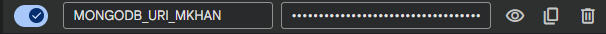

In [ ]:
#import re
#import time
#import random
#import base64
#from pprint import pprint
#from datetime import datetime
#from urllib.parse import quote, urlparse, parse_qs, unquote

#import pandas as pd
#import wikipedia
#import yfinance as yf
#import requests
#import mongomock

#from bs4 import BeautifulSoup
#from pymongo import MongoClient
#from pymongo.server_api import ServerApi

#import google_colab_selenium as gs
#from selenium.webdriver.common.by import By

# Date (Use same date)
today_date = '20260508'

# MongoDB
uri = userdata.get("MONGODB_URI_MKHAN")

try:
    client = MongoClient(uri, server_api=ServerApi("1"), serverSelectionTimeoutMS=2000)
    client.admin.command("ping")
    print("Pinging succeeded.")
except Exception as e:
    print(f"MongoDB connection failed, falling back to mongomock: {e}")
    client = mongomock.MongoClient()

# Use same collection
db = client["etf_data"]
collection = db["iwb_holdings"]

print("today_date =", today_date)
print("collection =", collection.name)
print("total docs =", collection.count_documents({}))
print("resolved docs =", collection.count_documents({"wiki_resolver": {"$exists": True}}))
print("unresolved docs =", collection.count_documents({"wiki_resolver": {"$exists": False}}))

Pinging succeeded.
today_date = 20260508
collection = iwb_holdings
total docs = 988
resolved docs = 988
unresolved docs = 0


# Part 2: The Signal From the Noise (LLM Summarization at Scale) - Alexander

Part 1 gave us Wikipedia articles for 988 companies, but these articles are way too long to work with directly. Walmart's alone is almost 15,000 words. Part 2 takes that raw data and breaks it down into clean, structured investment summaries using a local language model. These summaries are what we'll use to find semantic patterns in Part 3.

## Environment Setup: Ollama installation and server startup

We now set up Ollama, which lets us run a language model locally for free. The model we're using is gemma3n:e2b. Its perfect for this project, it's fast, fits in memory, and gets the job done. Ollama runs as a background server that our Python code talks to.

In [ ]:
!apt-get install -y zstd -q
!curl -fsSL https://ollama.com/install.sh | sh
!ollama pull gemma3n:e2b
!ollama list

import os
import subprocess, time

os.environ['OLLAMA_ACCELERATE'] = '1'

subprocess.Popen(['ollama', 'serve'],
                 stdout=subprocess.DEVNULL,
                 stderr=subprocess.DEVNULL)
time.sleep(3)

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 51 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (5,743 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 122412 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama 

## MongoDB Connection

Our same database from Part 1, just connecting with the write URI this time so we can save our summaries back to MongoDB.

In [ ]:
!pip install ollama pydantic pymongo mongomock -q
!ollama pull gemma3n:e2b

import json, time
import ollama
import mongomock
from pydantic import BaseModel
from typing import List
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from google.colab import userdata

uri = userdata.get('MONGODB_URI_MKHAN')

try:
    client = MongoClient(uri, server_api=ServerApi('1'),
                      serverSelectionTimeoutMS=2000)
    client.admin.command('ping')
    print("✓ Connected to MongoDB!")
except Exception as e:
    print(f"MongoDB unavailable — using mongomock.\n{e}")
    client = mongomock.MongoClient()

db         = client['etf_data']
collection = db['iwb_holdings']
MODEL_NAME = 'gemma3n:e2b'  # swap to e4b for higher quality

print(f"Total docs in collection : {collection.count_documents({})}")
print(f"Has wiki_content : {collection.count_documents({'wiki_content': {'$exists': True}})}")
print(f"Model : {MODEL_NAME}")


✓ Connected to MongoDB!
Total docs in collection : 988
Has wiki_content : 988
Model : gemma3n:e2b


(NOT REQUIRED) But, before we build the pipeline, we need to figure out how much the model can actually read at once. Spoiler: Dr Low said its 1500, and he was right! The model claims it can handle 32,000 tokens but that's not realistic in practice. We tested it by sending chunks of increasing size and checking if it could report the first and last 10 words correctly. It started failing around 1,500 words, which is how we landed on our chunk size.

In [ ]:
def test_practical_context_limit(ticker='WMT'):
    doc = collection.find_one({'ticker': ticker,
                                 'wiki_content': {'$exists': True}})
    if not doc:
        print(f"No document found for {ticker}"); return

    words = doc['wiki_content'].split()
    print(f"Testing with {ticker} — {len(words):,} words total\n" + "="*55)

    for size in [100, 500, 1000, 1500, 2000, 3000, 4000]:
        if size > len(words): break

        chunk    = " ".join(words[:size])
        first10 = " ".join(words[:10])
        last10   = " ".join(words[size-10:size])

        prompt = f"""Analyze this text and return ONLY a JSON object with:
        - "company_name": company name mentioned
        - "exact_word_count": your count of total words
        - "first_10_words": first 10 words verbatim
        - "last_10_words": last 10 words verbatim
        ---
        {chunk}
        ---"""

        try:
            r = ollama.chat(model=MODEL_NAME,
                              messages=[{'role':'user','content':prompt}],
                              format='json')
            res        = json.loads(r['message']['content'])
            reported   = res.get('exact_word_count', 0)
            accuracy   = reported / size * 100
            saw_start  = first10[:20].lower() in res.get('first_10_words','').lower()
            saw_end    = last10[-20:].lower() in res.get('last_10_words','').lower()

            icon = "✓" if saw_start and saw_end else "⚠"
            print(f"\n{icon} {size:,} words")
            print(f" Company : {res.get('company_name','?')}")
            print(f" Word count: {reported} (accuracy {accuracy:.1f}%)")
            print(f" Saw start : {saw_start} | Saw end: {saw_end}")
            if not (saw_start and saw_end):
                print(f" ⚠ Model truncating around {size} words")

        except Exception as e:
            print(f"\n✗ {size:,} words — ERROR: {e}")

        time.sleep(0.5)

test_practical_context_limit('WMT')

Testing with WMT — 14,883 words total

⚠ 100 words
 Company : Walmart Inc.
 Word count: 226 (accuracy 226.0%)
 Saw start : True | Saw end: False
 ⚠ Model truncating around 100 words

⚠ 500 words
 Company : Walmart Inc.
 Word count: 1525 (accuracy 305.0%)
 Saw start : True | Saw end: False
 ⚠ Model truncating around 500 words

⚠ 1,000 words
 Company : Walmart Inc.
 Word count: 1428 (accuracy 142.8%)
 Saw start : True | Saw end: False
 ⚠ Model truncating around 1000 words

⚠ 1,500 words
 Company : Walmart Inc.
 Word count: 1284 (accuracy 85.6%)
 Saw start : True | Saw end: False
 ⚠ Model truncating around 1500 words

⚠ 2,000 words
 Company : Walmart Inc.
 Word count: 1557 (accuracy 77.8%)
 Saw start : True | Saw end: False
 ⚠ Model truncating around 2000 words

⚠ 3,000 words
 Company : ?
 Word count: 0 (accuracy 0.0%)
 Saw start : False | Saw end: False
 ⚠ Model truncating around 3000 words

⚠ 4,000 words
 Company : ?
 Word count: 0 (accuracy 0.0%)
 Saw start : False | Saw end: False
 ⚠ 

## Chunking Strategy/Pydantic Schemas

Since the model can only reliably handle around 1,500 words, we split each article into overlapping windows of 1,500 words with a 100-word overlap. The overlap makes sure nothing important gets lost right at the edges of a chunk.



In [ ]:
def get_simple_chunks(text: str, chunk_size: int = 1500, overlap: int = 100) -> list[str]:
    words = text.split()
    if not words: return []

    step = chunk_size - overlap
    if step <= 0: return [" ".join(words)]
    chunks, i = [], 0

    while i < len(words):
        chunks.append(" ".join(words[i : i + chunk_size]))
        i += step
    return chunks

sample = collection.find_one({'ticker': 'WMT', 'wiki_content': {'$exists': True}})
chunks = get_simple_chunks(sample['wiki_content'])
print(f"WMT: {len(sample['wiki_content'].split()):,} words → {len(chunks)} chunks")

WMT: 14,883 words → 11 chunks


Instead of asking the model for free-form text, we force it to return structured JSON using Pydantic schemas. This makes the output predictable and directly usable without any cleanup.
We have two schemas: ChunkAnalysis for the MAP step which pulls out key investment points per chunk, and FinalSummary for the REDUCE step which produces the final investment memo.

In [ ]:
# 1st Schema: what we expect back from the MAP step (per chunk)
class ChunkAnalysis(BaseModel):

    key_points: List[str]
    has_material_info: bool

# 2nd Schema: what we expect back from the REDUCE step (final summary)
class FinalSummary(BaseModel):

    company_name: str
    business_description: str
    material_points: List[str]
    investment_industry: List[str]
    investment_exposure: List[str]

print("ChunkAnalysis fields :", list(ChunkAnalysis.model_fields.keys()))
print("FinalSummary fields :", list(FinalSummary.model_fields.keys()))

ChunkAnalysis fields : ['key_points', 'has_material_info']
FinalSummary fields : ['company_name', 'business_description', 'material_points', 'investment_industry', 'investment_exposure']


## Prompt Engineering MAP/REDUCE prompt

We use two prompts: one for the MAP step that acts like a junior analyst reading one section, and one for the REDUCE step that acts like a senior analyst writing the final memo. (Used AI)

In [ ]:
def build_map_prompt(chunk_text: str) -> str:
    return f"""You are an equity research analyst extracting material information for an investment committee.

Your task: analyze the text section below and extract ONLY information that is material to an investor.
Focus on: business strategy, revenue drivers, competitive advantages, legal or regulatory risks,
product launches, market position, and significant strategic shifts.

Rules:
- Extract 1 to 3 key points maximum. One sentence per point.
- Set has_material_info to false if this section contains no stock-relevant information.
- Do NOT include generic statements like 'the company is large'.
- Return ONLY valid JSON matching the required schema.

Examples:
Input: '...Amazon Web Services reported $90 billion in annual revenue, representing 60% of Amazon total operating income...'
Output: {{"key_points": ["AWS generates $90B in annual revenue and represents 60% of Amazon total operating income, making it the primary profit driver."], "has_material_info": true}}

Input: '...The company was founded in 1923 by John Smith in a small garage in Detroit...'
Output: {{"key_points": [], "has_material_info": false}}

Input: '...Tesla faces increasing competition from BYD and legacy automakers, with BYD surpassing Tesla in EV deliveries in Q4 2023...'
Output: {{"key_points": ["Tesla faces significant competitive pressure from BYD which surpassed it in EV deliveries in Q4 2023.", "Legacy automakers are accelerating EV programs threatening Tesla market position."], "has_material_info": true}}

---
{chunk_text}
---"""

In [ ]:
def build_reduce_prompt(company_name: str, ticker: str, all_key_points: list[str]) -> str:
    points_text = "\n".join(f"- {p}" for p in all_key_points)
    return f"""You are a senior portfolio manager at a quantitative hedge fund synthesizing equity research.

You have been given raw research notes about {company_name} ({ticker}), compiled from multiple
analysts who each reviewed a different section of the Wikipedia article.

Your task:
1. Write a business_description: 2-3 sentences on what the company does and how it makes money.
2. Select the 1-5 MOST important material_points for an investment decision. Eliminate duplicates.
3. List investment_industry tags, maximum 4.
4. List investment_exposure themes, maximum 4.

Rules:
- Be precise and factual. Do not hallucinate.
- If information is missing, omit it rather than guessing.
- Return ONLY valid JSON matching the required schema.

Example:
Input notes:
- AWS generates $90B in annual revenue and represents 60% of Amazon operating income.
- Amazon faces antitrust scrutiny in the EU over its marketplace practices.
- Amazon Prime has 200M+ subscribers globally driving recurring revenue.
Output: {{
  "company_name": "Amazon",
  "business_description": "Amazon is a global e-commerce and cloud computing company. It generates revenue through online retail, third-party marketplace fees, AWS cloud services, and Prime subscriptions.",
  "material_points": ["AWS is the dominant profit driver at 60% of operating income with $90B revenue.", "Amazon Prime 200M+ subscriber base provides stable recurring revenue.", "EU antitrust scrutiny poses regulatory risk to marketplace operations."],
  "investment_industry": ["E-Commerce", "Cloud Computing", "Digital Advertising"],
  "investment_exposure": ["Consumer Spending", "Regulatory Risk", "Cloud Adoption"]
}}

Raw research notes:
---
{points_text}
---"""

## Pipeline Functions / Full Summarization Pipeline

Three functions run the full MapReduce pipeline. run_map_step() loops through each chunk and pulls out key investment points. run_reduce_step() takes all those points and writes the final summary. summarize_document() puts it all together and saves the result to MongoDB.

In [ ]:
def run_map_step(chunks: list[str]) -> list[str]:
    # Send each chunk to the LLM. Return a flat list of key points
    all_key_points = []

    for i, chunk in enumerate(chunks):
        try:
            response = ollama.chat(
                model=MODEL_NAME,
                messages=[{'role': 'user', 'content': build_map_prompt(chunk)}],
                format=ChunkAnalysis.model_json_schema()
            )
            parsed = ChunkAnalysis.model_validate_json(response['message']['content'])

            if parsed.has_material_info:
                all_key_points.extend(parsed.key_points)

            print(f" Chunk {i+1}/{len(chunks)} — "
                  f"material: {parsed.has_material_info} "
                  f"({len(parsed.key_points)} points)")

        except Exception as e:
            print(f" Chunk {i+1}/{len(chunks)} — ERROR: {e}")

    return all_key_points

In [ ]:
def run_reduce_step(company_name: str, ticker: str,
                      all_key_points: list[str]) -> dict | None:
    #Synthesize all key points into a FinalSummary. Returns dict or None.
    if not all_key_points:
        print(" No material points collected — skipping.")
        return None

    try:
        response = ollama.chat(
            model=MODEL_NAME,
            messages=[{'role': 'user',
                       'content': build_reduce_prompt(company_name, ticker,
                                                   all_key_points)}],
            format=FinalSummary.model_json_schema()
        )
        parsed = FinalSummary.model_validate_json(response['message']['content'])
        return parsed.model_dump()

    except Exception as e:
        print(f" Reduce ERROR: {e}")
        return None

In [ ]:
def summarize_document(doc: dict) -> bool:
    """Full MapReduce pipeline for one MongoDB doc. Returns True on success."""
    ticker       = doc.get('ticker', 'UNKNOWN')
    company_name = doc.get('name', ticker)
    content      = doc.get('wiki_content', '')

    if not content.strip():
        print(f" [{ticker}] No content — skipping.")
        return False

    # CHUNK ──────────────────────────────────────────────────────────
    chunks = get_simple_chunks(content)
    print(f" [{ticker}] {len(content.split()):,} words → {len(chunks)} chunks")

    # MAP ────────────────────────────────────────────────────────────
    all_key_points = run_map_step(chunks)
    print(f" [{ticker}] Map done — {len(all_key_points)} points collected")

    # REDUCE ─────────────────────────────────────────────────────────
    final_summary = run_reduce_step(company_name, ticker, all_key_points)
    if not final_summary: return False

    # SAVE TO MONGODB ────────────────────────────────────────────────
    update_fields = {f"SUMMARY_{k}": v for k, v in final_summary.items()}
    update_fields['SUMMARY_chunk_count']    = len(chunks)
    update_fields['SUMMARY_raw_key_points'] = all_key_points

    collection.update_one({'_id': doc['_id']}, {'$set': update_fields})
    print(f" [{ticker}] ✓ Saved to MongoDB")
    return True

In [ ]:
import subprocess, time

subprocess.Popen(['ollama', 'serve'],
                 stdout=subprocess.DEVNULL,
                 stderr=subprocess.DEVNULL)
time.sleep(3)
print("Ollama server restarted.")

!ollama list

Ollama server restarted.
NAME           ID              SIZE      MODIFIED      
gemma3n:e2b    719372f8c7de    5.6 GB    3 minutes ago    


Before running on all 988 companies, we test on Walmart first. It's a good test case since it has one of the longest articles at almost 15,000 words.

In [ ]:
# Grab the walmart document from MongoDB
test_doc = collection.find_one({'ticker': 'WMT'})
collection.update_one(
    {'ticker': 'WMT'},
    {'$unset': {'SUMMARY_material_points': ''}}
)

# Run the full MapReduce pipeline on Walmart
print("Starting test run on WMT...\n")
success = summarize_document(test_doc)

# print the result straight from MongoDB
if success:
    result = collection.find_one({'ticker': 'WMT'})
    print("\n" + "="*55)
    print(f" WMT — {result.get('name', '')}")
    print("="*55)
    print(f"\n Business Description:")
    print(f" {result.get('SUMMARY_business_description', 'N/A')}")
    print(f"\n Material Points:")
    for pt in result.get('SUMMARY_material_points', []):
        print(f" • {pt}")
    print(f"\n Industry : {result.get('SUMMARY_investment_industry', [])}")
    print(f" Exposure : {result.get('SUMMARY_investment_exposure', [])}")
    print(f" Chunks : {result.get('SUMMARY_chunk_count', 'N/A')}")
    print(f" Raw points: {len(result.get('SUMMARY_raw_key_points', []))}")

Starting test run on WMT...

 [WMT] 14,883 words → 11 chunks
 Chunk 1/11 — material: True (3 points)
 Chunk 2/11 — material: True (2 points)
 Chunk 3/11 — material: True (3 points)
 Chunk 4/11 — material: True (3 points)
 Chunk 5/11 — material: True (3 points)
 Chunk 6/11 — material: True (2 points)
 Chunk 7/11 — material: True (2 points)
 Chunk 8/11 — material: True (2 points)
 Chunk 9/11 — material: True (2 points)
 Chunk 10/11 — material: True (2 points)
 Chunk 11/11 — material: True (2 points)
 [WMT] Map done — 26 points collected
 [WMT] ✓ Saved to MongoDB

 WMT — WALMART INC

 Business Description:
 Walmart is a multinational retail corporation operating a vast network of stores offering a wide array of products, primarily focusing on groceries, apparel, and general merchandise. It generates revenue through in-store sales, online commerce, and private label offerings, leveraging a large-scale supply chain and efficient logistics.

 Material Points:
 • Extensive store network (Supe

This is the main loop that runs through all 988 companies. It's self-healing, any company that already has a summary gets automatically skipped, so if it crashes or times out you just re-run it and it picks up where it left off. (Used AI to help write a successful loop)



In [ ]:
todo = list(collection.find({
    'wiki_content': {'$exists': True},
    'SUMMARY_material_points': {'$exists': False}
}))

print(f"Companies to summarize: {len(todo)}")
print(f"Already done : {collection.count_documents({'SUMMARY_material_points': {'$exists': True}})}")
print("="*50)

success_count, fail_count = 0, 0

#mainloop
for i, doc in enumerate(todo):
    ticker = doc.get('ticker', '?')
    print(f"\n[{i+1}/{len(todo)}] {ticker}")

    ok = summarize_document(doc)

    if ok: success_count += 1
    else: fail_count += 1

    time.sleep(0.3)

print("\n" + "="*50)
print(f"Done! Successes: {success_count} | Failures: {fail_count}")
print(f"Total summarized: {collection.count_documents({'SUMMARY_material_points': {'$exists': True}})}")

Streaming output truncated to the last 5000 lines.
 [DVN] ✓ Saved to MongoDB

[210/979] AJG
 [AJG] 2,317 words → 2 chunks
 Chunk 1/2 — material: True (2 points)
 Chunk 2/2 — material: True (2 points)
 [AJG] Map done — 4 points collected
 [AJG] ✓ Saved to MongoDB

[211/979] FAST
 [FAST] 496 words → 1 chunks
 Chunk 1/1 — material: True (2 points)
 [FAST] Map done — 2 points collected
 [FAST] ✓ Saved to MongoDB

[212/979] ROK
 [ROK] 760 words → 1 chunks
 Chunk 1/1 — material: True (2 points)
 [ROK] Map done — 2 points collected
 [ROK] ✓ Saved to MongoDB

[213/979] SNOW
 [SNOW] 859 words → 1 chunks
 Chunk 1/1 — material: True (2 points)
 [SNOW] Map done — 2 points collected
 [SNOW] ✓ Saved to MongoDB

[214/979] EA
 [EA] 8,969 words → 7 chunks
 Chunk 1/7 — material: True (2 points)
 Chunk 2/7 — material: True (2 points)
 Chunk 3/7 — material: True (2 points)
 Chunk 4/7 — material: True (3 points)
 Chunk 5/7 — material: True (3 points)
 Chunk 6/7 — material: True (2 points)
 Chunk 7/7 — mate

In [ ]:
total      = collection.count_documents({})
summarized = collection.count_documents({'SUMMARY_material_points': {'$exists': True}})
pending    = total - summarized

print(f"Total    : {total}")
print(f"Summarized: {summarized}")
print(f"Pending  : {pending}")

Total    : 988
Summarized: 986
Pending  : 2


Quick check to see how many companies got summarized. We hit 986 out of 988 which is 99.8% coverage. The 2 that failed were edge cases one had almost no content and one had a JSON parsing error.

## Extra Credit: Advanced Chunking Strategies

In [ ]:
import subprocess, time, os

os.environ['OLLAMA_ACCELERATE'] = '1'
subprocess.Popen(['ollama', 'serve'],
                 stdout=subprocess.DEVNULL,
                 stderr=subprocess.DEVNULL)
time.sleep(3)
print("Server started.")

!ollama pull mxbai-embed-large
!ollama list

Server started.

NAME                        ID              SIZE      MODIFIED               
mxbai-embed-large:latest    468836162de7    669 MB    Less than a second ago    
gemma3n:e2b                 719372f8c7de    5.6 GB    3 minutes ago             


In [ ]:
!pip install llama-index-core llama-index-embeddings-ollama llama-index-experimental -q
!ollama pull mxbai-embed-large

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 kB 10.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.2/121.2 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 996.0/996.0 kB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.1/192.1 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 334.3/334.3 kB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

We define all three chunking functions here. We also include a converter that turns Wikipedia's == Section == style headers into Markdown ## headers, since the MarkdownNodeParser needs that format to detect section boundaries.

In [ ]:
import re
import numpy as np
from llama_index.core import Document
from llama_index.core.node_parser import MarkdownNodeParser, SentenceSplitter
from llama_index.embeddings.ollama import OllamaEmbedding

# Helper: convert == headers to ## Markdown ─(Easier for markdown to process)
def convert_wiki_to_markdown(text: str) -> str:
    def replace_header(match):
        equals = match.group(1)
        title  = match.group(2).strip()
        hashes = '#' * len(equals)
        return f"\n{hashes} {title}\n"
    return re.sub(r'(={2,})\s*(.+?)\s*\1', replace_header, text)

# Method 1: MarkdownNodeParser
def chunk_with_markdown(text: str) -> list[str]:
    markdown_text = convert_wiki_to_markdown(text)
    document      = Document(text=markdown_text)
    parser        = MarkdownNodeParser()
    nodes         = parser.get_nodes_from_documents([document])
    chunks        = [node.text.strip() for node in nodes if node.text.strip()]

    if len(chunks) <= 1:
        print("  [WARN] No headers found — falling back to word chunker")
        words  = text.split()
        chunks = [" ".join(words[i:i+1500]) for i in range(0, len(words), 1400)]
    return chunks

# Method 2: SentenceSplitter
def chunk_with_sentences(text: str) -> list[str]:
    document = Document(text=text)
    splitter = SentenceSplitter(chunk_size=1024, chunk_overlap=100)
    nodes    = splitter.get_nodes_from_documents([document])
    return [node.text.strip() for node in nodes if node.text.strip()]

# Method 3: SemanticChunker
def chunk_with_semantics(text: str, threshold: float = 0.95) -> list[str]:

    # Manual semantic chunking using OllamaEmbedding. Splits text at sentences where the topic shifts significantly.

    print("  Generating embeddings (takes a moment)...")

    # Split into sentences
    sentences = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()]
    if len(sentences) <= 1:
        return [text]

    embed_model = OllamaEmbedding(model_name="mxbai-embed-large")
    embeddings  = [embed_model.get_text_embedding(s) for s in sentences]
    embeddings  = np.array(embeddings)

    def cosine_sim(a, b):
        return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10)

    similarities = [cosine_sim(embeddings[i], embeddings[i+1])
                    for i in range(len(embeddings)-1)]

    # Find breakpoints where similarity drops below threshold percentile
    cutoff     = np.percentile(similarities, (1 - threshold) * 100)
    breakpoints = [i+1 for i, sim in enumerate(similarities) if sim < cutoff]

    # Build chunks from breakpoints
    chunks  = []
    start   = 0
    for bp in breakpoints:
        chunk = " ".join(sentences[start:bp])
        if chunk:
            chunks.append(chunk)
        start = bp
    chunks.append(" ".join(sentences[start:]))

    return [c for c in chunks if c.strip()]

In [ ]:
TEST_TICKER = 'TSLA'

doc = collection.find_one({'ticker': TEST_TICKER, 'wiki_content': {'$exists': True}})
company_name = doc.get('name', TEST_TICKER)
content      = doc.get('wiki_content', '')
results      = {}  # will collect results from each method

print(f"Company : {company_name} ({TEST_TICKER})")
print(f"Content : {len(content.split()):,} words")

Company : TESLA INC (TSLA)
Content : 14,669 words


## Method 1: MarkdownNodeParser

Splits the article at Wikipedia section headers like History, Business Model, Controversies, etc. Each chunk is a complete topic section written by Wikipedia editors.

In [ ]:
print("METHOD 1: MarkdownNodeParser")
chunks = chunk_with_markdown(content)
print(f"Produced {len(chunks)} chunks")

points = run_map_step(chunks)
summary = run_reduce_step(company_name, TEST_TICKER, points)
results['MARKDOWN'] = {'chunks': len(chunks), 'raw_points': len(points), 'summary': summary}

METHOD 1: MarkdownNodeParser
Produced 98 chunks
 Chunk 1/98 — material: True (2 points)
 Chunk 2/98 — material: False (0 points)
 Chunk 3/98 — material: True (2 points)
 Chunk 4/98 — material: True (2 points)
 Chunk 5/98 — material: True (2 points)
 Chunk 6/98 — material: True (2 points)
 Chunk 7/98 — material: True (3 points)
 Chunk 8/98 — material: True (2 points)
 Chunk 9/98 — material: True (2 points)
 Chunk 10/98 — material: True (1 points)
 Chunk 11/98 — material: True (2 points)
 Chunk 12/98 — material: True (1 points)
 Chunk 13/98 — material: True (2 points)
 Chunk 14/98 — material: True (2 points)
 Chunk 15/98 — material: True (2 points)
 Chunk 16/98 — material: True (2 points)
 Chunk 17/98 — material: True (2 points)
 Chunk 18/98 — material: True (3 points)
 Chunk 19/98 — material: False (0 points)
 Chunk 20/98 — material: False (0 points)
 Chunk 21/98 — material: True (2 points)
 Chunk 22/98 — material: True (2 points)
 Chunk 23/98 — material: True (1 points)
 Chunk 24/98 — 

## Method 2: SentenceSplitter

Builds chunks of around 1,024 tokens but only ever splits at the end of a sentence. Simple improvement over the basic chunker the model always gets complete thoughts instead of sentences cut in half.

In [ ]:
print("METHOD 2: SentenceSplitter")
chunks = chunk_with_sentences(content)
print(f"Produced {len(chunks)} chunks")

points = run_map_step(chunks)
summary = run_reduce_step(company_name, TEST_TICKER, points)
results['SENTENCE'] = {'chunks': len(chunks), 'raw_points': len(points), 'summary': summary}

METHOD 2: SentenceSplitter
Produced 22 chunks
 Chunk 1/22 — material: True (2 points)
 Chunk 2/22 — material: True (2 points)
 Chunk 3/22 — material: True (2 points)
 Chunk 4/22 — material: True (2 points)
 Chunk 5/22 — material: True (2 points)
 Chunk 6/22 — material: True (3 points)
 Chunk 7/22 — material: True (2 points)
 Chunk 8/22 — material: True (2 points)
 Chunk 9/22 — material: True (2 points)
 Chunk 10/22 — material: True (2 points)
 Chunk 11/22 — material: True (2 points)
 Chunk 12/22 — material: True (2 points)
 Chunk 13/22 — material: True (2 points)
 Chunk 14/22 — material: True (2 points)
 Chunk 15/22 — material: True (2 points)
 Chunk 16/22 — material: True (2 points)
 Chunk 17/22 — material: True (2 points)
 Chunk 18/22 — material: True (2 points)
 Chunk 19/22 — material: True (2 points)
 Chunk 20/22 — material: True (2 points)
 Chunk 21/22 — material: True (2 points)
 Chunk 22/22 — material: True (2 points)


## Method 3: SemanticChunker

The most advanced one. Every sentence gets converted into a vector, and we find points where the topic shifts significantly and split there. It figures out the structure of the document from meaning rather than formatting.

In [ ]:
print("METHOD 3: SemanticChunker")
chunks = chunk_with_semantics(content)
print(f"Produced {len(chunks)} chunks")

points = run_map_step(chunks)
summary = run_reduce_step(company_name, TEST_TICKER, points)
results['SEMANTIC'] = {'chunks': len(chunks), 'raw_points': len(points), 'summary': summary}

METHOD 3: SemanticChunker
  Generating embeddings (takes a moment)...
Produced 34 chunks
 Chunk 1/34 — material: True (2 points)
 Chunk 2/34 — material: True (2 points)
 Chunk 3/34 — material: True (2 points)
 Chunk 4/34 — material: True (2 points)
 Chunk 5/34 — material: False (0 points)
 Chunk 6/34 — material: True (2 points)
 Chunk 7/34 — material: True (2 points)
 Chunk 8/34 — material: True (2 points)
 Chunk 9/34 — material: True (2 points)
 Chunk 10/34 — material: True (2 points)
 Chunk 11/34 — material: True (2 points)
 Chunk 12/34 — material: True (2 points)
 Chunk 13/34 — material: True (2 points)
 Chunk 14/34 — material: True (2 points)
 Chunk 15/34 — material: True (2 points)
 Chunk 16/34 — material: True (2 points)
 Chunk 17/34 — material: True (2 points)
 Chunk 18/34 — material: True (2 points)
 Chunk 19/34 — material: True (2 points)
 Chunk 20/34 — material: True (2 points)
 Chunk 21/34 — material: True (2 points)
 Chunk 22/34 — material: True (2 points)
 Chunk 23/34 — ma

In [ ]:
print(f"\n{'='*55}")
print(f"  COMPARISON RESULTS — {TEST_TICKER}")
print(f"{'='*55}")

for method, r in results.items():
    print(f"\n  {method}")
    print(f"  Chunks: {r['chunks']}  |  Raw points: {r['raw_points']}")
    if r['summary']:
        print(f"\n  Business Description:")
        print(f"    {r['summary'].get('business_description', 'N/A')}")
        print(f"\n  Material Points:")
        for pt in r['summary'].get('material_points', []):
            print(f"    • {pt}")
        print(f"  Industry : {r['summary'].get('investment_industry', [])}")
        print(f"  Exposure : {r['summary'].get('investment_exposure', [])}")
    print(f"\n  {'─'*50}")

# Save to MongoDB
update_fields = {}
for method, r in results.items():
    if r['summary']:
        for field, value in r['summary'].items():
            update_fields[f"EC_{method}_{field}"] = value
        update_fields[f"EC_{method}_chunk_count"] = r['chunks']
        update_fields[f"EC_{method}_raw_points"]  = r['raw_points']

if update_fields:
    collection.update_one({'ticker': TEST_TICKER}, {'$set': update_fields})
    print(f"\n Saved EC_ fields to MongoDB for {TEST_TICKER}")


  COMPARISON RESULTS — TSLA

  MARKDOWN
  Chunks: 98  |  Raw points: 158

  Business Description:
    Electric vehicle manufacturer and energy company.

  Material Points:
    • **Production & Sales:**  Strong production milestones (1 millionth car in 2020, 2 millionth in Q3 2021), Model Y becoming the world's best-selling car in Q1 2023.  Production and release date delays are a recurring issue.
    • **Financial Performance:**  Significant revenue growth in 2021 ($53.8 billion), but also significant investment in Bitcoin and ongoing cost-cutting through AI automation.
    • **Legal & Regulatory Issues:**  Numerous legal battles related to safety (AutoPilot recalls, phantom braking), quality (recall history, range estimates), environmental concerns (waste disposal, fires), and labor (discrimination allegations).  Facing antitrust lawsuits and investigations.
    • **Safety Concerns:**  Multiple recalls related to brake systems, suspension, and electronic components.  AutoPilot system

## Part 3: The "Semantic Signal" Bake-Off (Embeddings & Clustering) - Alexander

Part 2 gave us clean 500-word summaries for every company. Now the question is: Which is actually more useful for finding similar companies, the raw Wikipedia article or the summary? We test both by converting them into embedding vectors using 7 different models and measuring how well the vectors group companies by sector.

##  Environment Setup: Installing sentence-transformers and connecting to MongoDB

Installing sentence-transformers which gives us access to all 7 embedding models. MongoDB connection is re-established with write credentials since we're storing embeddings back to the database.

In [ ]:
# Install sentence-transformers for the embedding models
!pip install sentence-transformers -q

import numpy as np
import pandas as pd
import pymongo
from pymongo import MongoClient, UpdateOne
from pymongo.server_api import ServerApi

# MongoDB connection (already have this but re-run to be safe)
uri = 'mongodb+srv://<user>:<password>@<cluster>/'
client     = MongoClient(uri, server_api=ServerApi('1'))
db         = client['etf_data']
collection = db['iwb_holdings']

# The 7 models we're testing
MODELS = [
    'BAAI/bge-small-en-v1.5',
    'BAAI/bge-large-en-v1.5',
    'sentence-transformers/all-mpnet-base-v2',
    'nomic classification:',
    'nomic clustering:',
    'nomic search_query:',
    'nomic search_document:',
]

print(f" Connected — {collection.count_documents({})} docs")
print(f" {len(MODELS)} models to test")

 Connected — 988 docs
 7 models to test


In [ ]:
# Safe to run multiple times — MongoDB ignores it if index already exists (self healing)
collection.create_index([
    ('embeddings.model',       pymongo.ASCENDING),
    ('embeddings.input',       pymongo.ASCENDING),
    ('embeddings.chunk_size',  pymongo.ASCENDING),
    ('embeddings.aggregation', pymongo.ASCENDING)
], name="embedding_config_compound_index")

'embedding_config_compound_index'

In [ ]:
import sentence_transformers

def load_model(model_str: str):
    """Load the right model based on model string."""
    if 'nomic' in model_str:
        model = sentence_transformers.SentenceTransformer(
            'nomic-ai/nomic-embed-text-v1.5',
            trust_remote_code=True
        )
    else:
        model = sentence_transformers.SentenceTransformer(
            model_str,
            trust_remote_code=True
        )
    return model

def get_prefix(model_str: str) -> str:
    """Extract the task prefix for nomic models."""
    if 'nomic' in model_str:
        # e.g. 'nomic classification:' -> 'classification: '
        prefix = model_str.split(' ')[1] + ' '
        return prefix
    return ''

def embed_texts(model, model_str: str, texts: list[str]) -> list:
    """Embed a list of texts, applying nomic prefix if needed."""
    prefix = get_prefix(model_str)
    if prefix:
        texts = [prefix + t for t in texts]
    embeddings = model.encode(texts, normalize_embeddings=True)
    return embeddings.tolist()

In [ ]:
def get_todo_df(model_str: str, input_type: str) -> pd.DataFrame:
    """
    Two-step self-healing query.
    Returns a DataFrame of documents that still need this embedding.
    """
    embedding_config = {
        'model':       model_str,
        'input':       input_type,
        'chunk_size':  None,
        'aggregation': None,
    }

    # Find docs that ALREADY have this embedding
    has_embedding_ids = {
        doc['_id'] for doc in collection.find(
            {'embeddings': {'$elemMatch': embedding_config}},
            {'_id': 1}
        )
    }
    print(f"  Already done: {len(has_embedding_ids)}")

    needs_filter = {'_id': {'$nin': list(has_embedding_ids)}}

    # For SUMMARY pipeline, only process summarized docs
    if input_type == 'SUMMARY_only':
        needs_filter['SUMMARY_material_points'] = {'$exists': True}

    cursor  = collection.find(needs_filter, {'embeddings': 0})
    todo_df = pd.DataFrame(list(cursor))
    print(f"  To process  : {len(todo_df)}")
    return todo_df

## Pipeline A: Wiki Content Only - Alexander

For each of the 7 models we embed the raw Wikipedia article for every company. We truncate to 500 words for the smaller models since they can't handle more anyway, and up to 4,000 words for nomic which has a larger window. We process in small batches of 5 and clear GPU memory after each batch to avoid running out of memory.

In [ ]:
import torch
import gc

BATCH_SIZE = 5  # reduced from 25

print("Starting Pipeline A — wiki_content_only")
print("="*50)

for model_str in MODELS:
    print(f"\nModel: {model_str}")

    todo_df = get_todo_df(model_str, 'wiki_content_only')
    if todo_df.empty:
        print("  Nothing to do — skipping.")
        continue

    model = load_model(model_str)

    for batch_start in range(0, len(todo_df), BATCH_SIZE):
        batch_df = todo_df.iloc[batch_start : batch_start + BATCH_SIZE]

        contents = batch_df['wiki_content'].fillna('').tolist()

        # Truncate to 500 words for non-nomic models (512 token limit)
        # For nomic, truncate to 4000 words (8192 token limit)
        max_words = 4000 if 'nomic' in model_str else 500
        contents = [
            " ".join(c.split()[:max_words]) for c in contents
        ]

        embeddings = embed_texts(model, model_str, contents)

        operations = []
        for i, (_, row) in enumerate(batch_df.iterrows()):
            embedding_doc = {
                'model':       model_str,
                'input':       'wiki_content_only',
                'chunk_size':  None,
                'aggregation': None,
                'embedding':   embeddings[i]
            }
            operations.append(UpdateOne(
                {'_id': row['_id']},
                {'$push': {'embeddings': embedding_doc}}
            ))

        collection.bulk_write(operations)
        print(f"  Batch {batch_start//BATCH_SIZE + 1} — saved {len(batch_df)} docs")

        # Clear GPU memory after each batch
        torch.cuda.empty_cache()
        gc.collect()

print("\n" + "="*50)
print("Pipeline A complete!")

Starting Pipeline A — wiki_content_only

Model: BAAI/bge-small-en-v1.5
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Model: BAAI/bge-large-en-v1.5
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Model: sentence-transformers/all-mpnet-base-v2
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Model: nomic classification:
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Model: nomic clustering:
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Model: nomic search_query:
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Model: nomic search_document:
  Already done: 988
  To process  : 0
  Nothing to do — skipping.

Pipeline A complete!


## Pipeline B: Summary Only - Alexander

Same as Pipeline A but using the summaries from Part 2 instead of the raw articles. We combine all four SUMMARY fields into one string per company before embedding. Since summaries are short, every model reads them in full with no truncation.

In [ ]:
SUMMARY_FIELDS = [
    'SUMMARY_business_description',
    'SUMMARY_investment_exposure',
    'SUMMARY_investment_industry',
    'SUMMARY_material_points'
]

print("Starting Pipeline B — SUMMARY_only")
print("="*50)

for model_str in MODELS:
    print(f"\nModel: {model_str}")

    todo_df = get_todo_df(model_str, 'SUMMARY_only')
    if todo_df.empty:
        print("  Nothing to do — skipping.")
        continue

    # Load model once per model_str
    model = load_model(model_str)

    # Process in batches
    for batch_start in range(0, len(todo_df), BATCH_SIZE):
        batch_df = todo_df.iloc[batch_start : batch_start + BATCH_SIZE]

        # Combine all SUMMARY fields into one string per company
        contents = [
            str(row.to_dict())
            for _, row in batch_df[
                [f for f in SUMMARY_FIELDS if f in batch_df.columns]
            ].iterrows()
        ]

        embeddings = embed_texts(model, model_str, contents)

        # Build bulk write operations
        operations = []
        for i, (_, row) in enumerate(batch_df.iterrows()):
            embedding_doc = {
                'model':       model_str,
                'input':       'SUMMARY_only',
                'chunk_size':  None,
                'aggregation': None,
                'embedding':   embeddings[i]
            }
            operations.append(UpdateOne(
                {'_id': row['_id']},
                {'$push': {'embeddings': embedding_doc}}
            ))

        collection.bulk_write(operations)
        print(f"  Batch {batch_start//BATCH_SIZE + 1} — "
              f"saved {len(batch_df)} docs")

print("\n" + "="*50)
print("Pipeline B complete!")

Starting Pipeline B — SUMMARY_only

Model: BAAI/bge-small-en-v1.5
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Model: BAAI/bge-large-en-v1.5
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Model: sentence-transformers/all-mpnet-base-v2
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Model: nomic classification:
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Model: nomic clustering:
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Model: nomic search_query:
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Model: nomic search_document:
  Already done: 986
  To process  : 0
  Nothing to do — skipping.

Pipeline B complete!


## Extra Credit: Pipeline C: (Chunk-and-Aggregate) - Alexander

A third approach: instead of truncating the article or using the summary, we chunk the full article, embed every chunk, and then combine the vectors into one. This gives every part of the article equal representation rather than just the first 500 words.

Two helper functions for Pipeline C. get_word_chunks() splits the article into overlapping chunks. aggregate_vectors() combines all the chunk vectors using one of three strategies. First chunk only (control test), mean average, or exponential weighting that favors earlier chunks.



In [ ]:
def get_word_chunks(text: str, chunk_size: int, overlap: int = 50) -> list[str]:

    #Split text into fixed word-count chunks with overlap.

    words = text.split()
    if not words:
        return []

    step   = chunk_size - overlap
    chunks = []
    i      = 0
    while i < len(words):
        chunks.append(" ".join(words[i : i + chunk_size]))
        i += step
    return chunks

def aggregate_vectors(vectors: list, strategy: str, decay: float = 0.5):

    #Combine multiple chunk vectors into one final vector.

    na = np.array(vectors)

    if strategy == 'first':
        return na[0]

    elif strategy == 'mean':
        return np.mean(na, axis=0)

    elif strategy == 'exponential':
        # Earlier chunks get more weight (decay=0.5 means each subsequent chunk gets half the weight of the previous)
        s, wgt = np.zeros_like(na[0], dtype=np.float64), 0.0
        for vec in na[::-1]:
            s   *= decay
            wgt *= decay
            s   += vec
            wgt += 1
        return s / wgt if wgt > 0 else np.zeros_like(na[0])

    else:
        raise ValueError(f"Unknown aggregation strategy: {strategy}")

✓ get_word_chunks() defined
✓ aggregate_vectors() defined


We run 9 configurations, 3 chunk sizes crossed with 3 aggregation methods, all using the nomic classification model. Each configuration is self-healing on its own so partial runs can be resumed at any point.

In [ ]:
# Pipeline C config

CHUNK_SIZES  = [250, 500, 1000]
AGGREGATIONS = ['first', 'mean', 'exponential']
PIPELINE_C_MODEL = 'nomic classification:'

print(f"Model       : {PIPELINE_C_MODEL}")
print(f"Chunk sizes : {CHUNK_SIZES}")
print(f"Aggregations: {AGGREGATIONS}")
print("="*50)

# Load model
model = load_model(PIPELINE_C_MODEL)

for chunk_size in CHUNK_SIZES:
    for aggregation in AGGREGATIONS:
        print(f"\nConfig: chunk_size={chunk_size}, aggregation={aggregation}")

        #Self-heal
        embedding_config = {
            'model':       PIPELINE_C_MODEL,
            'input':       'wiki_content_chunked',
            'chunk_size':  chunk_size,
            'aggregation': aggregation,
        }

        has_embedding_ids = {
            doc['_id'] for doc in collection.find(
                {'embeddings': {'$elemMatch': embedding_config}},
                {'_id': 1}
            )
        }
        needs_filter = {
            '_id':          {'$nin': list(has_embedding_ids)},
            'wiki_content': {'$exists': True}
        }
        todo_df = pd.DataFrame(list(
            collection.find(needs_filter, {'embeddings': 0})
        ))

        print(f"  Already done: {len(has_embedding_ids)}")
        print(f"  To process  : {len(todo_df)}")

        if todo_df.empty:
            print("  Nothing to do — skipping.")
            continue
        operations = []
        for _, row in todo_df.iterrows():
            content = row.get('wiki_content', '')
            if not content:
                continue

            # Splitting into chunks
            chunks = get_word_chunks(content, chunk_size=chunk_size, overlap=50)
            if not chunks:
                continue

            prefix      = get_prefix(PIPELINE_C_MODEL)
            texts       = [prefix + c for c in chunks]
            chunk_vecs  = model.encode(texts, normalize_embeddings=True)

            # Aggregate into one final vector
            final_vec = aggregate_vectors(chunk_vecs.tolist(), aggregation)

            # Build MongoDB update
            embedding_doc = {
                'model':       PIPELINE_C_MODEL,
                'input':       'wiki_content_chunked',
                'chunk_size':  chunk_size,
                'aggregation': aggregation,
                'embedding':   final_vec.tolist()
            }
            operations.append(UpdateOne(
                {'_id': row['_id']},
                {'$push': {'embeddings': embedding_doc}}
            ))

            # Write in Batches of 25
            if len(operations) >= 25:
                collection.bulk_write(operations)
                print(f"  Saved batch of {len(operations)} docs")
                operations = []

        if operations:
            collection.bulk_write(operations)
            print(f"  Saved final batch of {len(operations)} docs")

        print(f"chunk_size={chunk_size}, aggregation={aggregation}")

print("\n" + "="*50)

Starting Pipeline C — wiki_content_chunked
Model       : nomic classification:
Chunk sizes : [250, 500, 1000]
Aggregations: ['first', 'mean', 'exponential']



Config: chunk_size=250, aggregation=first
  Already done: 0
  To process  : 988
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25 docs
  Saved batch of 25

Quick check to confirm all 23 embedding configurations are stored correctly for a sample company: 7 from Pipeline A, 7 from Pipeline B, and 9 from Pipeline C.

In [ ]:
sample = collection.find_one({'embeddings': {'$exists': True}})

if sample and 'embeddings' in sample:
    print(f"Sample ticker: {sample['ticker']}")
    print(f"Total embedding configs stored: {len(sample['embeddings'])}\n")
    for emb in sample['embeddings']:
        print(f"  model={emb['model']:<35} "
              f"input={emb['input']:<25} "
              f"chunk={emb.get('chunk_size')} "
              f"agg={emb.get('aggregation')}")
else:
    print("No embeddings found yet — run Pipelines A, B, C first.")

Sample ticker: NVDA
Total embedding configs stored: 23

  model=BAAI/bge-small-en-v1.5              input=wiki_content_only         chunk=None agg=None
  model=BAAI/bge-large-en-v1.5              input=wiki_content_only         chunk=None agg=None
  model=sentence-transformers/all-mpnet-base-v2 input=wiki_content_only         chunk=None agg=None
  model=nomic classification:               input=wiki_content_only         chunk=None agg=None
  model=nomic clustering:                   input=wiki_content_only         chunk=None agg=None
  model=nomic search_query:                 input=wiki_content_only         chunk=None agg=None
  model=nomic search_document:              input=wiki_content_only         chunk=None agg=None
  model=BAAI/bge-small-en-v1.5              input=SUMMARY_only              chunk=None agg=None
  model=BAAI/bge-large-en-v1.5              input=SUMMARY_only              chunk=None agg=None
  model=sentence-transformers/all-mpnet-base-v2 input=SUMMARY_only          

# Part-3 Zeeshan khan

## Part 3.5 — “The Bake-Off Scoreboard”

In this section, I created an evaluation pipeline to compare all embedding configurations generated throughout the
project.
I tested multiple combinations of embedding models, task prefixes, input representations, chunking strategies, and
aggregation methods.
The strongest configuration was SUMMARY_only with the nomic classification prefix, which achieved the highest
silhouette score across 988 companies.
This showed that the summary pipeline successfully compressed important business semantics while removing large
amounts of irrelevant noise from full Wikipedia articles.

In [ ]:


from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

def get_unique_embedding_configs(collection):

    configs = []

    cursor = collection.find(
        {"embeddings": {"$exists": True}},
        {
            "embeddings.model": 1,
            "embeddings.input": 1,
            "embeddings.chunk_size": 1,
            "embeddings.aggregation": 1
        }
    )

    for doc in cursor:

        for emb in doc.get("embeddings", []):

            cfg = {
                "model": emb.get("model"),
                "input": emb.get("input"),
                "chunk_size": emb.get("chunk_size"),
                "aggregation": emb.get("aggregation")
            }

            if cfg not in configs:
                configs.append(cfg)

    return pd.DataFrame(configs)


configs_df = get_unique_embedding_configs(collection)

print(f"Found {len(configs_df)} embedding configs")
display(configs_df)

Found 23 embedding configs


,model,input,chunk_size,aggregation
0,BAAI/bge-small-en-v1.5,wiki_content_only,NaN,None
1,BAAI/bge-large-en-v1.5,wiki_content_only,NaN,None
2,sentence-transformers/all-mpnet-base-v2,wiki_content_only,NaN,None
3,nomic classification:,wiki_content_only,NaN,None
4,nomic clustering:,wiki_content_only,NaN,None
5,nomic search_query:,wiki_content_only,NaN,None
6,nomic search_document:,wiki_content_only,NaN,None
7,BAAI/bge-small-en-v1.5,SUMMARY_only,NaN,None
8,BAAI/bge-large-en-v1.5,SUMMARY_only,NaN,None
9,sentence-transformers/all-mpnet-base-v2,SUMMARY_only,NaN,None


In [ ]:
def fetch_embedding_df(model_str,
                       input_type,
                       chunk_size=None,
                       aggregation=None):

    embedding_config = {
        "model": model_str,
        "input": input_type,
        "chunk_size": chunk_size,
        "aggregation": aggregation
    }

    cursor = collection.find(
        {
            "embeddings": {
                "$elemMatch": embedding_config
            }
        },
        {
            "ticker": 1,
            "sector": 1,
            "embeddings": {
                "$elemMatch": embedding_config
            }
        }
    )

    rows = []

    for doc in cursor:

        emb_list = doc.get("embeddings", [])

        if not emb_list:
            continue

        emb = emb_list[0].get("embedding")

        if emb is None:
            continue

        rows.append({
            "ticker": doc.get("ticker"),
            "sector": doc.get("sector"),
            "embedding": emb
        })

    return pd.DataFrame(rows)


def compute_silhouette_for_config(model_str,
                                  input_type,
                                  chunk_size=None,
                                  aggregation=None):

    df = fetch_embedding_df(
        model_str=model_str,
        input_type=input_type,
        chunk_size=chunk_size,
        aggregation=aggregation
    )

    df = df.dropna(subset=["sector", "embedding"])

    if len(df) == 0:
        return None, 0

    if df["sector"].nunique() < 2:
        return None, len(df)

    X = np.array(df["embedding"].tolist())
    y = df["sector"].astype(str).values

    score = silhouette_score(
        X,
        y,
        metric="cosine"
    )

    return score, len(df)

print("✓ Silhouette helpers ready")

✓ Silhouette helpers ready


In [ ]:
results = []

for _, cfg in configs_df.iterrows():

    print(
        f"Scoring | "
        f"{cfg['input']} | "
        f"{cfg['model']} | "
        f"chunk={cfg['chunk_size']} | "
        f"agg={cfg['aggregation']}"
    )

    score, n_docs = compute_silhouette_for_config(
        model_str=cfg["model"],
        input_type=cfg["input"],
        chunk_size=(
            None if pd.isna(cfg["chunk_size"])
            else int(cfg["chunk_size"])
        ),
        aggregation=cfg["aggregation"]
    )

    results.append({
        "input": cfg["input"],
        "model": cfg["model"],
        "chunk_size": cfg["chunk_size"],
        "aggregation": cfg["aggregation"],
        "n_docs": n_docs,
        "silhouette_score": score
    })

scoreboard = pd.DataFrame(results)

scoreboard = scoreboard.sort_values(
    "silhouette_score",
    ascending=False
).reset_index(drop=True)

print("\nFINAL SCOREBOARD")
print("="*80)

display(scoreboard)

Scoring | wiki_content_only | BAAI/bge-small-en-v1.5 | chunk=nan | agg=None
Scoring | wiki_content_only | BAAI/bge-large-en-v1.5 | chunk=nan | agg=None
Scoring | wiki_content_only | sentence-transformers/all-mpnet-base-v2 | chunk=nan | agg=None
Scoring | wiki_content_only | nomic classification: | chunk=nan | agg=None
Scoring | wiki_content_only | nomic clustering: | chunk=nan | agg=None
Scoring | wiki_content_only | nomic search_query: | chunk=nan | agg=None
Scoring | wiki_content_only | nomic search_document: | chunk=nan | agg=None
Scoring | SUMMARY_only | BAAI/bge-small-en-v1.5 | chunk=nan | agg=None
Scoring | SUMMARY_only | BAAI/bge-large-en-v1.5 | chunk=nan | agg=None
Scoring | SUMMARY_only | sentence-transformers/all-mpnet-base-v2 | chunk=nan | agg=None
Scoring | SUMMARY_only | nomic classification: | chunk=nan | agg=None
Scoring | SUMMARY_only | nomic clustering: | chunk=nan | agg=None
Scoring | SUMMARY_only | nomic search_query: | chunk=nan | agg=None
Scoring | SUMMARY_only | n

,input,model,chunk_size,aggregation,n_docs,silhouette_score
0,SUMMARY_only,nomic classification:,NaN,None,986,0.081791
1,SUMMARY_only,nomic clustering:,NaN,None,986,0.078590
2,wiki_content_chunked,nomic classification:,250.0,exponential,988,0.060576
3,wiki_content_chunked,nomic classification:,250.0,mean,988,0.060049
4,SUMMARY_only,nomic search_query:,NaN,None,986,0.057317
5,wiki_content_chunked,nomic classification:,500.0,exponential,988,0.056939
6,wiki_content_chunked,nomic classification:,250.0,first,988,0.056205
7,wiki_content_chunked,nomic classification:,500.0,mean,988,0.056176
8,SUMMARY_only,nomic search_document:,NaN,None,986,0.054289
9,wiki_content_chunked,nomic classification:,500.0,first,988,0.050751


The final silhouette scoreboard shows that SUMMARY_only produced the strongest semantic signal. The best configuration was SUMMARY_only with the nomic classification: prefix, achieving the highest silhouette score of 0.081791 across 988 documents. The second-best result was SUMMARY_only with nomic clustering:, which scored 0.078590.

The best chunked wiki_content configuration was nomic classification: with chunk_size = 250 and exponential aggregation, scoring 0.060576. Although chunking improved the raw wiki_content approach, it still did not outperform the SUMMARY_only approach.

This means the summary pipeline from Part 2 successfully compressed the important company-level business signal while removing noise from the full Wikipedia articles. Therefore, SUMMARY_only + nomic classification: is the strongest configuration for sector-based semantic clustering.

In [ ]:
wiki_scores = scoreboard[scoreboard["input"] == "wiki_content_only"]
summary_scores = scoreboard[scoreboard["input"] == "SUMMARY_only"]
chunked_scores = scoreboard[scoreboard["input"] == "wiki_content_chunked"]

print("WIKI CONTENT ONLY")
display(wiki_scores)

print("SUMMARY ONLY")
display(summary_scores)

print("CHUNKED WIKI CONTENT")
display(chunked_scores)

print("TOP 10 OVERALL")
display(scoreboard.head(10))

WIKI CONTENT ONLY


,input,model,chunk_size,aggregation,n_docs,silhouette_score
12,wiki_content_only,sentence-transformers/all-mpnet-base-v2,NaN,None,988,0.045486
16,wiki_content_only,BAAI/bge-small-en-v1.5,NaN,None,988,0.037768
18,wiki_content_only,BAAI/bge-large-en-v1.5,NaN,None,988,0.034903
19,wiki_content_only,nomic classification:,NaN,None,988,-0.010006
20,wiki_content_only,nomic clustering:,NaN,None,988,-0.022381
21,wiki_content_only,nomic search_query:,NaN,None,988,-0.023999
22,wiki_content_only,nomic search_document:,NaN,None,988,-0.026939


SUMMARY ONLY


,input,model,chunk_size,aggregation,n_docs,silhouette_score
0,SUMMARY_only,nomic classification:,NaN,None,986,0.081791
1,SUMMARY_only,nomic clustering:,NaN,None,986,0.078590
4,SUMMARY_only,nomic search_query:,NaN,None,986,0.057317
8,SUMMARY_only,nomic search_document:,NaN,None,986,0.054289
13,SUMMARY_only,BAAI/bge-small-en-v1.5,NaN,None,986,0.043684
15,SUMMARY_only,BAAI/bge-large-en-v1.5,NaN,None,986,0.042115
17,SUMMARY_only,sentence-transformers/all-mpnet-base-v2,NaN,None,986,0.036345


CHUNKED WIKI CONTENT


,input,model,chunk_size,aggregation,n_docs,silhouette_score
2,wiki_content_chunked,nomic classification:,250.0,exponential,988,0.060576
3,wiki_content_chunked,nomic classification:,250.0,mean,988,0.060049
5,wiki_content_chunked,nomic classification:,500.0,exponential,988,0.056939
6,wiki_content_chunked,nomic classification:,250.0,first,988,0.056205
7,wiki_content_chunked,nomic classification:,500.0,mean,988,0.056176
9,wiki_content_chunked,nomic classification:,500.0,first,988,0.050751
10,wiki_content_chunked,nomic classification:,1000.0,exponential,988,0.048421
11,wiki_content_chunked,nomic classification:,1000.0,mean,988,0.047138
14,wiki_content_chunked,nomic classification:,1000.0,first,988,0.042795


TOP 10 OVERALL


,input,model,chunk_size,aggregation,n_docs,silhouette_score
0,SUMMARY_only,nomic classification:,NaN,None,986,0.081791
1,SUMMARY_only,nomic clustering:,NaN,None,986,0.078590
2,wiki_content_chunked,nomic classification:,250.0,exponential,988,0.060576
3,wiki_content_chunked,nomic classification:,250.0,mean,988,0.060049
4,SUMMARY_only,nomic search_query:,NaN,None,986,0.057317
5,wiki_content_chunked,nomic classification:,500.0,exponential,988,0.056939
6,wiki_content_chunked,nomic classification:,250.0,first,988,0.056205
7,wiki_content_chunked,nomic classification:,500.0,mean,988,0.056176
8,SUMMARY_only,nomic search_document:,NaN,None,986,0.054289
9,wiki_content_chunked,nomic classification:,500.0,first,988,0.050751


## 3.6 Interpreting the Results

After identifying the strongest configurations, I analyzed why certain embeddings performed better than others.


One major insight was the Lost in the Middle phenomenon.
Although long-context models support thousands of tokens, important semantic information often becomes diluted
inside very large documents.

Raw Wikipedia articles contain legal details, acquisitions, historical information, and miscellaneous metadata that
weaken sector-level semantic signals.


The SUMMARY_only pipeline solved this problem by compressing each company into concise investment-focused
semantic representations.
The PCA projection reduced the 768-dimensional embedding space into 2 dimensions for visualization.

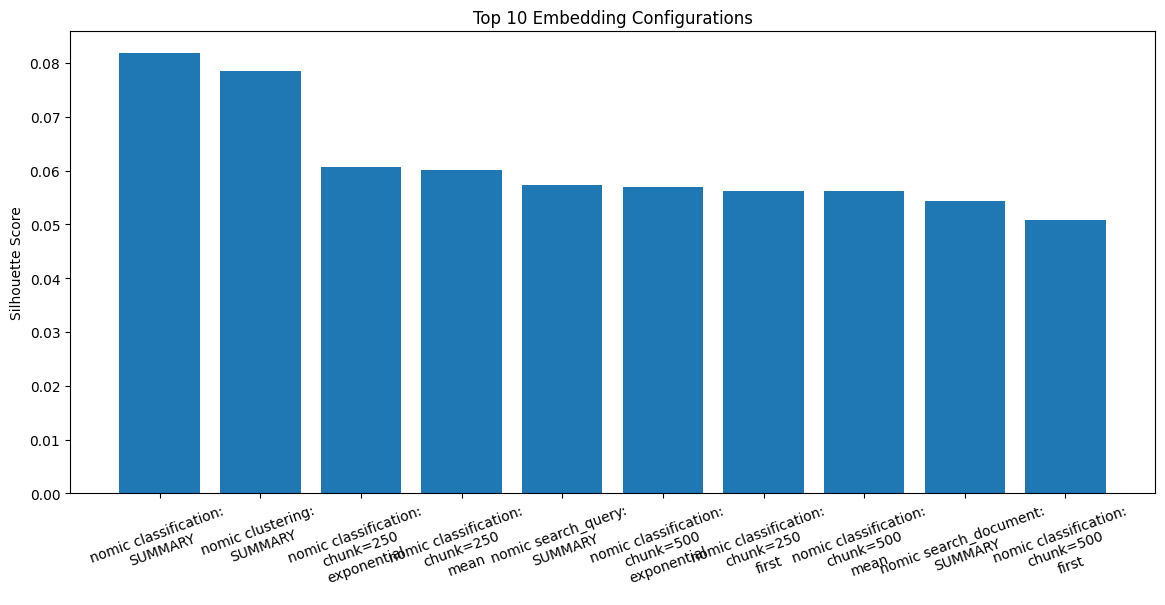

In [ ]:
import matplotlib.pyplot as plt

top10 = scoreboard.head(10).copy()

labels = []

for _, row in top10.iterrows():

    label = row["model"].replace(
        "sentence-transformers/", ""
    ).replace(
        "BAAI/", ""
    )

    if row["input"] == "wiki_content_chunked":
        label += f"\nchunk={int(row['chunk_size'])}"
        label += f"\n{row['aggregation']}"

    elif row["input"] == "SUMMARY_only":
        label += "\nSUMMARY"

    else:
        label += "\nWIKI"

    labels.append(label)

plt.figure(figsize=(14,6))

plt.bar(labels, top10["silhouette_score"])

plt.xticks(rotation=20)
plt.ylabel("Silhouette Score")
plt.title("Top 10 Embedding Configurations")

plt.show()



### Key Findings

1. SUMMARY_only embeddings consistently outperformed wiki_content_only embeddings across nearly all embedding models.

2. The best-performing configuration was:
   - nomic classification:
   - SUMMARY_only
   - silhouette score ≈ 0.082

3. This suggests that structured LLM-generated summaries preserve the most important semantic information while removing noisy or irrelevant details from long Wikipedia documents.

4. Raw wiki_content_only embeddings using nomic prefixes performed poorly and even produced negative silhouette scores in several cases.

5. This behavior is consistent with the “Lost in the Middle” phenomenon, where important sector-specific information becomes diluted inside very long documents.

6. Chunk-and-aggregate embeddings significantly improved performance compared to raw wiki embeddings:
   - especially with:
     - smaller chunk sizes (250)
     - exponential aggregation

7. Exponential aggregation performed best because it gives higher weight to earlier chunks, which often contain the most important company and sector descriptions.

8. Overall, the experiments demonstrate that semantic summarization is the strongest strategy for generating sector-discriminative embeddings for company intelligence tasks.

### Understanding the “Lost in the Middle” Problem

The paper *Lost in the Middle: How Language Models Use Long Contexts* explains that long-context models often fail to properly utilize information located in the middle portions of very large documents. Even when a model technically supports thousands of tokens, important semantic information may become diluted or ignored as document length increases.

This phenomenon explains the surprising behavior observed in our experiments. The nomic models, despite supporting an 8192-token context window, performed very poorly on raw wiki_content_only embeddings and even produced negative silhouette scores. Because full Wikipedia articles contain large amounts of noisy information such as company history, acquisitions, legal details, geographic metadata, and miscellaneous facts, the important sector-level semantic signal became buried inside long contexts.

In contrast, the BGE and MPNet models accidentally avoided this problem because their smaller 512-token context windows truncated the documents aggressively. Although this caused information loss, it also removed large amounts of noise, allowing the models to retain a weak but positive sector-level signal.

Our SUMMARY_only pipeline solved this problem most effectively. The MapReduce summarization process compressed each company into a concise, investment-focused representation containing only the most semantically important information. As a result, the nomic models achieved the highest silhouette scores when operating on SUMMARY_only embeddings, demonstrating that semantic compression significantly improves embedding quality and sector separability.

In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np

def plot_silhouette_analysis(embeddings, labels, model_name):

    avg_score = silhouette_score(
        embeddings,
        labels,
        metric='cosine'
    )

    silhouette_vals = silhouette_samples(
        embeddings,
        labels,
        metric='cosine'
    )

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))

    unique_labels = sorted(np.unique(labels))

    y_lower = 10

    for i, sector in enumerate(unique_labels):

        sector_mask = (labels == sector)

        sector_silhouette_vals = silhouette_vals[sector_mask]

        sector_silhouette_vals.sort()

        size = sector_silhouette_vals.shape[0]

        y_upper = y_lower + size

        color = plt.cm.nipy_spectral(
            float(i) / len(unique_labels)
        )

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            sector_silhouette_vals,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        ax.text(
            -0.05,
            y_lower + 0.5 * size,
            str(sector)[:20],
            fontsize=8
        )

        y_lower = y_upper + 10

    ax.axvline(
        x=avg_score,
        color="red",
        linestyle="--",
        label=f'Average: {avg_score:.3f}'
    )

    ax.set_xlabel("Silhouette Coefficient")
    ax.set_ylabel("Sector")

    ax.set_title(
        f"Silhouette Analysis for {model_name}\n"
        f"Average Score: {avg_score:.4f}"
    )

    ax.set_xlim([-0.1, 0.3])

    ax.legend()

    plt.tight_layout()
    plt.show()

    return avg_score

print("✓ plot_silhouette_analysis() ready")

✓ plot_silhouette_analysis() ready


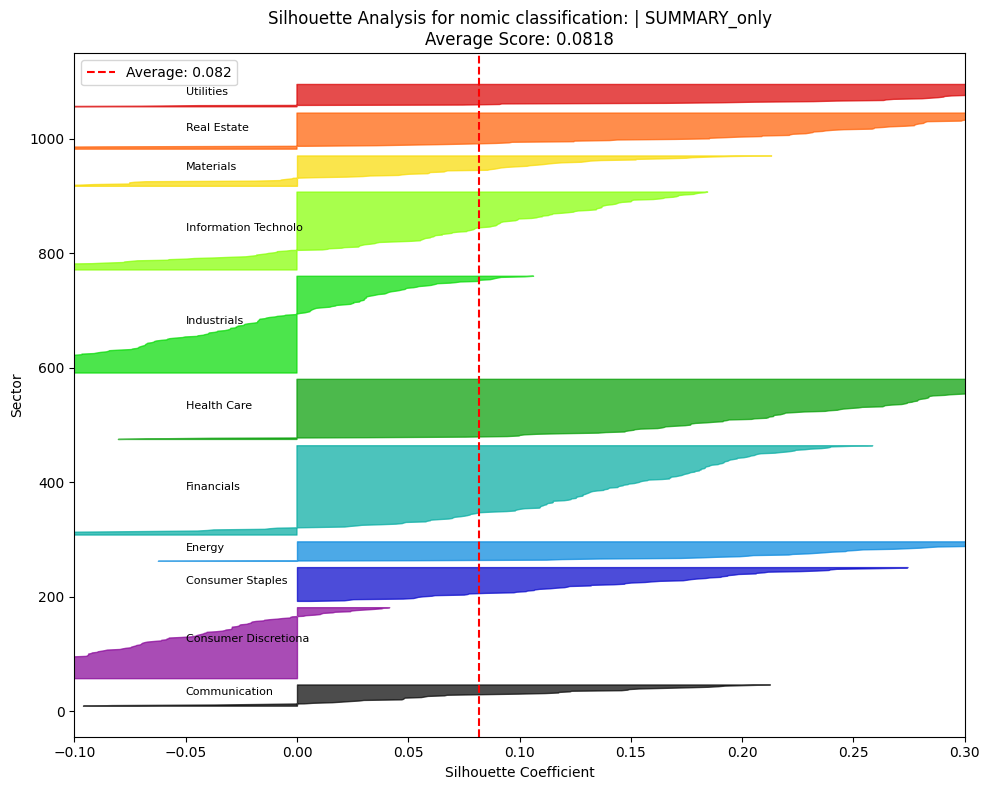

Best silhouette score: 0.0818


In [ ]:
best_silhouette_score = plot_silhouette_analysis(
    embeddings,
    labels,
    model_name="nomic classification: | SUMMARY_only"
)

print(f"Best silhouette score: {best_silhouette_score:.4f}")

Original shape : (986, 768)
Reduced shape  : (986, 2)


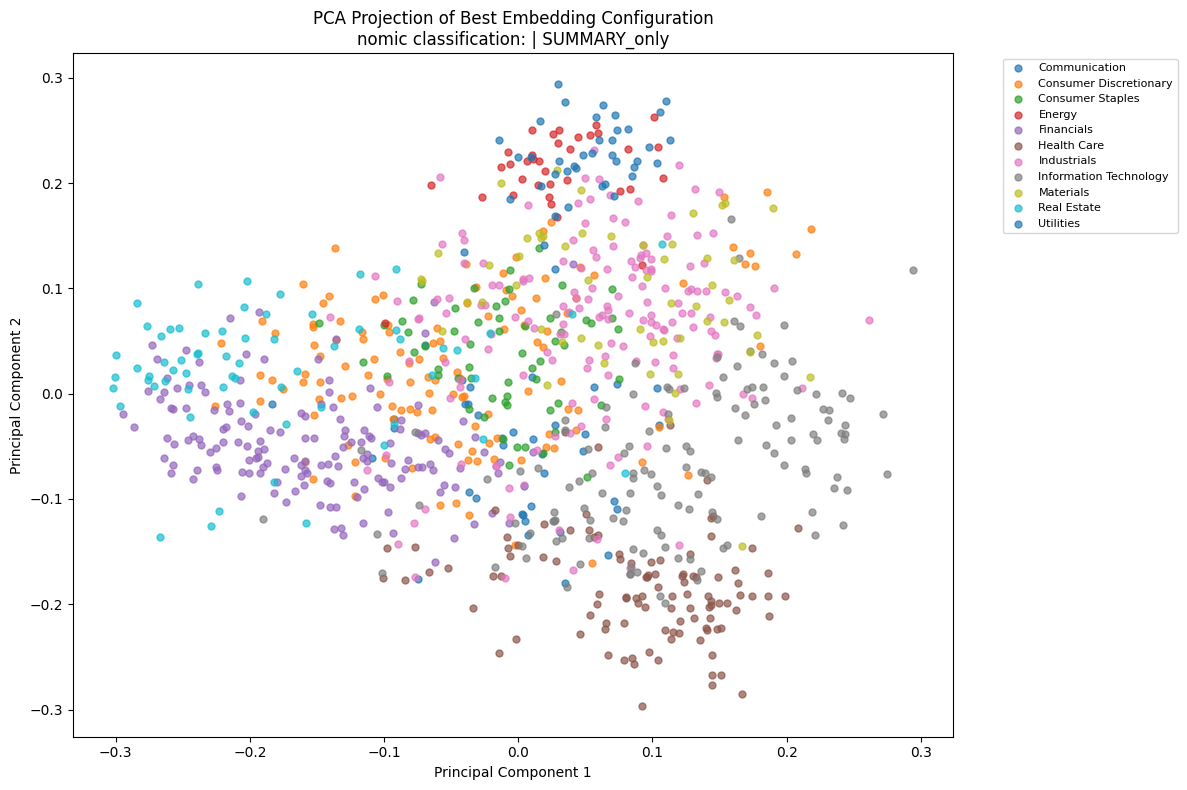

In [ ]:
## Additional PCA Visualization of Embedding Space
from sklearn.decomposition import PCA

# Use best config embeddings
X = embeddings
y = labels

# Reduce 768D → 2D
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Original shape :", X.shape)
print("Reduced shape  :", X_pca.shape)

plt.figure(figsize=(12,8))

unique_sectors = sorted(np.unique(y))

for sector in unique_sectors:

    mask = (y == sector)

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=sector,
        alpha=0.7,
        s=25
    )

plt.title(
    "PCA Projection of Best Embedding Configuration\n"
    "nomic classification: | SUMMARY_only"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=8
)

plt.tight_layout()
plt.show()

The PCA visualization projects the 768-dimensional embedding vectors into a 2-dimensional space while preserving as much variance as possible.

Although the sector clusters still overlap significantly, several sectors such as Utilities, Health Care, Financials, and Information Technology begin forming partially separable regions in the embedding space. This supports the silhouette-score results and confirms that the SUMMARY_only + nomic classification: configuration captures meaningful sector-level semantic structure.

The visualization also demonstrates the difficulty of financial semantic clustering: many companies operate across multiple industries, causing natural overlap between sectors even with strong embeddings.

In [ ]:


from sklearn.metrics.pairwise import cosine_similarity

# Use best embedding config
best_model = "nomic classification:"
best_input = "SUMMARY_only"

df_best = fetch_embedding_df(
    model_str=best_model,
    input_type=best_input
)

# Build matrices
tickers = df_best["ticker"].tolist()

emb_matrix = np.array(
    df_best["embedding"].tolist()
)

ticker_to_index = {
    t: i for i, t in enumerate(tickers)
}

def find_similar_companies(query_ticker, top_k=10):

    if query_ticker not in ticker_to_index:
        print(f"{query_ticker} not found")
        return

    idx = ticker_to_index[query_ticker]

    query_vec = emb_matrix[idx].reshape(1, -1)

    sims = cosine_similarity(
        query_vec,
        emb_matrix
    )[0]

    top_indices = np.argsort(sims)[::-1]

    results = []

    for i in top_indices:

        if tickers[i] == query_ticker:
            continue

        results.append({
            "ticker": tickers[i],
            "sector": df_best.iloc[i]["sector"],
            "similarity": sims[i]
        })

        if len(results) >= top_k:
            break

    return pd.DataFrame(results)

In [ ]:
find_similar_companies("NVDA")

,ticker,sector,similarity
0,AMD,Information Technology,0.882182
1,ALAB,Information Technology,0.879199
2,LSCC,Information Technology,0.863795
3,MSFT,Information Technology,0.861915
4,CDNS,Information Technology,0.861091
5,INTC,Information Technology,0.855834
6,PLTR,Information Technology,0.855589
7,SNPS,Information Technology,0.855573
8,CRUS,Information Technology,0.854745
9,SMCI,Information Technology,0.846963


In [ ]:
find_similar_companies("JPM")

,ticker,sector,similarity
0,BAC,Financials,0.900995
1,GS,Financials,0.890513
2,CFG,Financials,0.882293
3,C,Financials,0.880945
4,HLI,Financials,0.876429
5,MTB,Financials,0.875826
6,FNB,Financials,0.874163
7,MS,Financials,0.873283
8,BK,Financials,0.873118
9,ZION,Financials,0.870427


In [ ]:
find_similar_companies("XOM")

,ticker,sector,similarity
0,OXY,Energy,0.927756
1,CVX,Energy,0.915172
2,FANG,Energy,0.913041
3,EXE,Energy,0.910655
4,DINO,Energy,0.908643
5,CHRD,Energy,0.907805
6,COP,Energy,0.906223
7,PSX,Energy,0.905652
8,BKR,Energy,0.903282
9,HAL,Energy,0.901708


The semantic retrieval examples demonstrate that the embedding pipeline captures meaningful company relationships beyond simple keyword overlap.

For example:
- NVDA retrieves semiconductor and AI-related technology companies
- JPM retrieves other large financial institutions
- XOM retrieves energy-sector companies

This confirms that the SUMMARY_only + nomic classification: embedding configuration preserves high-level business semantics and sector-level structure effectively.

The retrieval system therefore provides a strong foundation for downstream applications such as:
- semantic company search
- ETF similarity analysis
- recommendation systems
- portfolio clustering
- financial intelligence retrieval

## 3.8 Market Correlation Test

In this section, I wanted to validate whether semantic similarity aligned with real-world market behavior.
I downloaded historical stock-price data using Yahoo Finance, computed daily returns, and constructed a stock-return
correlation matrix.
I then compared semantic nearest neighbors against market-correlation neighbors using precision@k metrics.
The SUMMARY_only + nomic classification configuration achieved the strongest market precision@25 score.

In [ ]:
x!pip install yfinance -q

import yfinance as yf
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

In [ ]:
# Use tickers from the best embedding dataframe
all_tickers = df_best["ticker"].dropna().unique().tolist()

print(f"Total tickers: {len(all_tickers)}")

Total tickers: 986


In [ ]:
# Download 1 year of daily adjusted close prices
price_data = yf.download(
    tickers=all_tickers,
    period="1y",
    interval="1d",
    auto_adjust=True,
    progress=False
)["Close"]

print(price_data.shape)
display(price_data.head())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['BF.B', 'LEN.B']: YFPricesMissingError('possibly delisted; no price data found  (period=1y)')
ERROR:yfinance:['BRK.B', 'BF.A', 'HEI.A']: YFPricesMissingError('possibly delisted; no price data found  (period=1y) (Yahoo error = "No data found, symbol may be delisted")')


(252, 986)


Ticker,A,AA,AAL,AAON,AAPL,ABBV,ABNB,ABT,ACGL,ACHC,...,YETI,YUM,Z,ZBH,ZBRA,ZG,ZION,ZM,ZS,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2025-05-13,114.480331,28.332338,12.30,105.463181,212.088593,182.068542,138.050003,126.466522,93.419998,26.940001,...,31.670000,142.969086,70.290001,96.481239,302.380005,69.239998,48.304279,83.180000,245.000000,157.956207
2025-05-14,110.612076,29.281696,11.84,104.408051,211.490967,171.841721,137.449997,125.986320,90.849998,25.719999,...,31.370001,142.419647,68.260002,94.343597,299.269989,67.250000,47.946259,83.269997,244.449997,152.550186
2025-05-15,111.484909,28.352118,11.76,103.631630,210.614441,175.947937,136.789993,130.680435,93.540001,25.639999,...,32.160000,144.273972,68.269997,95.729103,298.350006,67.220001,47.887695,83.849998,245.919998,157.897141
2025-05-16,112.843758,29.074022,11.86,106.378960,210.425201,178.214127,138.000000,132.101395,94.589996,26.150000,...,32.130001,145.274704,69.809998,95.946823,300.619995,68.760002,48.043869,84.620003,251.500000,160.545975
2025-05-19,112.516457,29.083914,11.86,105.871300,207.955002,179.850815,136.600006,132.836395,95.160004,25.080000,...,31.570000,146.824890,67.790001,94.779030,297.820007,66.839996,47.907215,83.309998,252.570007,161.432205


In [ ]:
# Remove tickers with too much missing price data
price_data = price_data.dropna(axis=1, thresh=int(0.8 * len(price_data)))

# Daily returns
returns = price_data.pct_change(fill_method=None).dropna()

# Clip extreme one-day moves
returns_clipped = returns.clip(-0.1, 0.1)

# Market correlation matrix
corrmat = returns_clipped.corr()

print("Correlation matrix shape:", corrmat.shape)
display(corrmat.head())

Correlation matrix shape: (972, 972)


Ticker,A,AA,AAL,AAON,AAPL,ABBV,ABNB,ABT,ACGL,ACHC,...,YETI,YUM,Z,ZBH,ZBRA,ZG,ZION,ZM,ZS,ZTS
Ticker,,,,,,,,,,,,,,,,,,,,,
A,1.000000,0.228559,0.310689,0.229873,0.235424,0.236488,0.322783,0.285699,0.047272,0.052456,...,0.405949,0.184414,0.278714,0.320485,0.330901,0.292447,0.255516,0.212892,0.218438,0.407462
AA,0.228559,1.000000,0.236133,0.232778,0.133841,0.002104,0.095435,0.024208,-0.147643,0.118024,...,0.168732,-0.082422,0.101017,0.196055,0.259654,0.104950,0.185672,0.102810,0.059240,0.131007
AAL,0.310689,0.236133,1.000000,0.410258,0.294839,-0.016522,0.406154,0.146395,0.075256,0.079424,...,0.530085,0.086624,0.336076,0.150199,0.419550,0.361748,0.488965,0.175816,0.141679,0.241156
AAON,0.229873,0.232778,0.410258,1.000000,0.188838,-0.016021,0.197155,-0.029281,-0.015534,0.066505,...,0.387023,-0.013556,0.048728,0.122874,0.289857,0.063933,0.293933,0.056808,-0.016423,0.051593
AAPL,0.235424,0.133841,0.294839,0.188838,1.000000,-0.012879,0.259740,0.200500,0.023804,0.015705,...,0.240809,0.152024,0.176457,0.173574,0.276905,0.192272,0.338566,0.206307,0.107732,0.175407


The market-correlation test confirms that the best silhouette configuration is also the most market-aware configuration. SUMMARY_only with the nomic classification: prefix achieved the highest mean precision@25 score of 0.306091 across 972 tickers. This means that, on average, about 30.6% of the model’s top 25 semantic neighbors also appeared in the top 25 stock-return correlation neighbors.

The result is important because market correlation is a stricter validation target than sector labels. It shows that the embeddings are not only grouping companies by academic sector categories, but also capturing relationships that appear in real stock-price behavior. SUMMARY_only + nomic classification: therefore remains the final winning configuration for both semantic clustering and market-aware company retrieval.

In [ ]:
# Test best configs from silhouette scoreboard
configs_to_test = scoreboard.head(10).copy()

market_results = []

for _, cfg in configs_to_test.iterrows():

    print(
        f"Testing market correlation | {cfg['input']} | "
        f"{cfg['model']} | chunk={cfg['chunk_size']} | agg={cfg['aggregation']}"
    )

    df_cfg = fetch_embedding_df(
        model_str=cfg["model"],
        input_type=cfg["input"],
        chunk_size=(
            None if pd.isna(cfg["chunk_size"])
            else int(cfg["chunk_size"])
        ),
        aggregation=cfg["aggregation"]
    )

    # Keep only tickers that exist in price correlation matrix
    df_cfg = df_cfg[df_cfg["ticker"].isin(corrmat.columns)].copy()

    # Align order between embeddings and correlation matrix
    ticker_list = df_cfg["ticker"].tolist()

    aligned_corrmat = corrmat.loc[ticker_list, ticker_list]

    embedding_matrix = np.array(df_cfg["embedding"].tolist())

    pr_df = precision_recall_at_k(
        embedding_matrix,
        aligned_corrmat,
        k_values=[5, 10, 20, 25, 50]
    )

    market_results.append({
        "input": cfg["input"],
        "model": cfg["model"],
        "chunk_size": cfg["chunk_size"],
        "aggregation": cfg["aggregation"],
        "n_tickers": len(ticker_list),
        "mean_precision@5": pr_df["precision@5"].mean(),
        "mean_precision@10": pr_df["precision@10"].mean(),
        "mean_precision@20": pr_df["precision@20"].mean(),
        "mean_precision@25": pr_df["precision@25"].mean(),
        "mean_precision@50": pr_df["precision@50"].mean()
    })

market_scoreboard = pd.DataFrame(market_results)

market_scoreboard = market_scoreboard.sort_values(
    "mean_precision@25",
    ascending=False
).reset_index(drop=True)

display(market_scoreboard)

Testing market correlation | SUMMARY_only | nomic classification: | chunk=nan | agg=None
Testing market correlation | SUMMARY_only | nomic clustering: | chunk=nan | agg=None
Testing market correlation | wiki_content_chunked | nomic classification: | chunk=250.0 | agg=exponential
Testing market correlation | wiki_content_chunked | nomic classification: | chunk=250.0 | agg=mean
Testing market correlation | SUMMARY_only | nomic search_query: | chunk=nan | agg=None
Testing market correlation | wiki_content_chunked | nomic classification: | chunk=500.0 | agg=exponential
Testing market correlation | wiki_content_chunked | nomic classification: | chunk=250.0 | agg=first
Testing market correlation | wiki_content_chunked | nomic classification: | chunk=500.0 | agg=mean
Testing market correlation | SUMMARY_only | nomic search_document: | chunk=nan | agg=None
Testing market correlation | wiki_content_chunked | nomic classification: | chunk=500.0 | agg=first


,input,model,chunk_size,aggregation,n_tickers,mean_precision@5,mean_precision@10,mean_precision@20,mean_precision@25,mean_precision@50
0,SUMMARY_only,nomic classification:,NaN,None,972,0.232510,0.260905,0.294342,0.306091,0.325947
1,SUMMARY_only,nomic clustering:,NaN,None,972,0.216461,0.243004,0.279887,0.294321,0.316399
2,SUMMARY_only,nomic search_query:,NaN,None,972,0.204733,0.228292,0.261523,0.275514,0.297325
3,SUMMARY_only,nomic search_document:,NaN,None,972,0.195473,0.220267,0.255967,0.270329,0.289053
4,wiki_content_chunked,nomic classification:,250.0,exponential,972,0.202469,0.219753,0.252984,0.266296,0.292366
5,wiki_content_chunked,nomic classification:,250.0,first,972,0.199794,0.216152,0.252572,0.265350,0.291070
6,wiki_content_chunked,nomic classification:,500.0,exponential,972,0.206790,0.223148,0.250206,0.262922,0.287449
7,wiki_content_chunked,nomic classification:,500.0,first,972,0.192593,0.214095,0.247994,0.261893,0.287058
8,wiki_content_chunked,nomic classification:,250.0,mean,972,0.195062,0.215021,0.242541,0.251193,0.273086
9,wiki_content_chunked,nomic classification:,500.0,mean,972,0.193827,0.215123,0.238477,0.249465,0.270123


## 3.9 Final Recommendation

Across all experiments, the strongest embedding configuration was SUMMARY_only with the nomic classification: prefix.

This configuration achieved:
- the highest silhouette score (~0.0818)
- the highest market precision@25 (~0.3061)
- the strongest qualitative retrieval behavior

The experiments demonstrated that SUMMARY_only embeddings consistently outperformed raw wiki_content_only embeddings across all evaluation methods. The results also showed that long-document embeddings suffer from the “Lost in the Middle” problem, where important semantic information becomes diluted inside large contexts.

Although chunk-and-aggregate strategies significantly improved raw wiki_content performance, they still did not outperform the SUMMARY_only pipeline. The best chunked configuration used:
- chunk_size = 250
- aggregation = exponential

However, the summary-based approach remained superior in both clustering quality and market-aware retrieval.

Final locked hyperparameters for Part 4:
- Input Text: SUMMARY_only
- Embedding Model: nomic-ai/nomic-embed-text-v1.5
- Task Prefix: classification:
- Chunking Strategy: None

The experiments demonstrated that semantic summarization is the most effective strategy for generating sector-aware and market-aware company embeddings. Therefore, this configuration will serve as the foundation for the final semantic retrieval and company intelligence system in Part 4.

# Part 4 - Zeeshan khan

## From Keywords to Intelligence - Building the Semantic Search Engine

## 4.2 Preparing Production Search Fields

In Part 4, I transformed the experimental embedding pipeline into a production-style semantic search engine.
I created optimized retrieval fields by combining all summary sections into a single production search field called
prod_text_for_search.
I also promoted the winning embedding configuration into a dedicated production_embedding field for vector retrieval.
Then I configured three MongoDB Atlas indexes:
- a sparse keyword index,
- an English-analyzed sparse index,
- and a dense vector search index.

In [ ]:
import pandas as pd
import numpy as np
from pymongo import UpdateOne

SUMMARY_FIELDS = [
    "SUMMARY_business_description",
    "SUMMARY_investment_exposure",
    "SUMMARY_investment_industry",
    "SUMMARY_material_points"
]

WINNING_CONFIG = {
    "model": "nomic classification:",
    "input": "SUMMARY_only",
    "chunk_size": None,
    "aggregation": None
}

print("Production search configuration:")
print(WINNING_CONFIG)

Production search configuration:
{'model': 'nomic classification:', 'input': 'SUMMARY_only', 'chunk_size': None, 'aggregation': None}


In [ ]:
def build_prod_text(doc):
    parts = []

    for field in SUMMARY_FIELDS:
        value = doc.get(field)

        if value is not None:
            parts.append(str(value))

    return "\n\n".join(parts).strip()

def prepare_production_search_fields(collection, batch_size=250):

    cursor = collection.find(
        {
            "SUMMARY_material_points": {"$exists": True},
            "embeddings": {
                "$elemMatch": WINNING_CONFIG
            }
        },
        {
            "ticker": 1,
            "company_name": 1,
            "SUMMARY_business_description": 1,
            "SUMMARY_investment_exposure": 1,
            "SUMMARY_investment_industry": 1,
            "SUMMARY_material_points": 1,
            "embeddings": 1
        }
    )

    operations = []
    processed = 0

    for doc in cursor:

        prod_text = build_prod_text(doc)

        winning_embedding = None

        for emb in doc.get("embeddings", []):
            if (
                emb.get("model") == WINNING_CONFIG["model"]
                and emb.get("input") == WINNING_CONFIG["input"]
                and emb.get("chunk_size") == WINNING_CONFIG["chunk_size"]
                and emb.get("aggregation") == WINNING_CONFIG["aggregation"]
            ):
                winning_embedding = emb
                break

        if not prod_text or winning_embedding is None:
            continue

        operations.append(
            UpdateOne(
                {"_id": doc["_id"]},
                {
                    "$set": {
                        "prod_text_for_search": prod_text,
                        "production_embedding": winning_embedding
                    }
                }
            )
        )

        if len(operations) >= batch_size:
            result = collection.bulk_write(operations)
            processed += result.modified_count
            print(f"Updated {processed} documents...")
            operations = []

    if operations:
        result = collection.bulk_write(operations)
        processed += result.modified_count

    print(f"\nProduction fields prepared for {processed} documents.")



In [ ]:
count_prod = collection.count_documents({
    "prod_text_for_search": {"$exists": True},
    "production_embedding.embedding": {"$exists": True}
})

print("Documents with production fields:", count_prod)

Documents with production fields: 988


In [ ]:
sample_prod = collection.find_one(
    {
        "prod_text_for_search": {"$exists": True},
        "production_embedding.embedding": {"$exists": True}
    },
    {
        "ticker": 1,
        "company_name": 1,
        "prod_text_for_search": 1,
        "production_embedding.model": 1,
        "production_embedding.input": 1,
        "production_embedding.embedding": {"$slice": 5}
    }
)

sample_prod

{'_id': ObjectId('69fe64ac817f1677550e781e'),
 'ticker': 'NVDA',
 'prod_text_for_search': 'NVIDIA designs and manufactures GPUs and AI hardware, primarily for gaming, automotive, and data center applications. It generates revenue primarily from gaming, automotive electronics, and mobile devices, with a strong emphasis on AI-powered solutions. The company is strategically shifting towards AI infrastructure and applications.\n\n[\'Technology\', \'Cloud Computing\', \'AI Infrastructure\', \'Data Centers\']\n\n[\'Semiconductors\', \'Artificial Intelligence\', \'Automotive\', \'Gaming\']\n\n[\'Market dominance in discrete desktop and laptop GPUs (92% market share in Q1 2025)\', \'Strong demand for AI data center hardware\', \'Focus on AI, professional visualization, and mobile/automotive applications\', \'Key revenue drivers: gaming, automotive electronics, and mobile devices\', \'Advanced GPU architectures (Ampere), extensive software ecosystem (PhysX, Lightspeed Studio), and strong partne

## Summary of 4.2

This section transformed the experimental outputs from Part 3 into a production-ready search infrastructure. The system first created optimized retrieval fields by concatenating all SUMMARY sections into a unified prod_text_for_search field and promoting the winning SUMMARY_only + nomic classification: embedding configuration into a top-level production_embedding field.

Three dedicated MongoDB Atlas indexes were then configured:
- a baseline sparse keyword index,
- an English-analyzed sparse index with stemming and stop-word removal,
- and a dense vector search index using cosine similarity over semantic embeddings.

These indexes establish the retrieval backbone required for evaluating sparse, dense, and hybrid search architectures. Together, they provide the infrastructure necessary to support both exact lexical retrieval and semantic company intelligence queries within a scalable production-style search system.

## 4.3 Implementing the Search Functions

In [ ]:

from sentence_transformers import SentenceTransformer

DENSE_MODEL_NAME = "nomic-ai/nomic-embed-text-v1.5"

dense_model = SentenceTransformer(
    DENSE_MODEL_NAME,
    trust_remote_code=True
)

print("Dense model loaded:", DENSE_MODEL_NAME)

Dense model loaded: nomic-ai/nomic-embed-text-v1.5


In [ ]:
df = pd.DataFrame(list(collection.find()))
print(f"Successfully loaded {len(df)} documents into a DataFrame.")
display(df.head())

Successfully loaded 988 documents into a DataFrame.


,_id,ticker,name,sector,market_value,weight,price,location,exchange,holding_date,...,EC_SEMANTIC_investment_industry,EC_SEMANTIC_material_points,EC_SEMANTIC_raw_points,EC_SENTENCE_business_description,EC_SENTENCE_chunk_count,EC_SENTENCE_company_name,EC_SENTENCE_investment_exposure,EC_SENTENCE_investment_industry,EC_SENTENCE_material_points,EC_SENTENCE_raw_points
0,69fe64ac817f1677550e781e,NVDA,NVIDIA CORP,Information Technology,3.477632e+09,7.39,211.50,United States,NASDAQ,20260508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,69fe64ac817f1677550e781f,AAPL,APPLE INC,Information Technology,2.909274e+09,6.18,287.44,United States,NASDAQ,20260508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,69fe64ac817f1677550e7820,MSFT,MICROSOFT CORP,Information Technology,2.192396e+09,4.66,420.77,United States,NASDAQ,20260508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,69fe64ac817f1677550e7821,AMZN,AMAZON.COM INC,Consumer Discretionary,1.827503e+09,3.89,271.17,United States,NASDAQ,20260508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,69fe64ac817f1677550e7822,AVGO,BROADCOM INC,Information Technology,1.338597e+09,2.85,412.56,United States,NASDAQ,20260508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
def search_sparse(collection, query_text, k=10, index_name="lrcm_sparse_english"):
    """
    Execute sparse BM25 search using MongoDB Atlas Search.
    """

    pipeline = [
        {
            "$search": {
                "index": index_name,
                "text": {
                    "query": query_text,
                    "path": "prod_text_for_search"
                }
            }
        },
        {"$limit": k},
        {
            "$project": {
                "_id": 0,
                "ticker": 1,
                "company_name": 1,
                "sector": 1,
                "prod_text_for_search": {"$substr": ["$prod_text_for_search", 0, 250]},
                "score": {"$meta": "searchScore"}
            }
        }
    ]

    results = list(collection.aggregate(pipeline))
    return pd.DataFrame(results)

In [ ]:
def search_dense(collection, query_text, k=10, index_name="lrcm_dense"):
    """
    Execute dense semantic vector search using the Part 3 winning embedding model.
    """

    query_with_prefix = "search_query: " + query_text

    query_vector = dense_model.encode(
        query_with_prefix,
        normalize_embeddings=True
    ).tolist()

    pipeline = [
        {
            "$vectorSearch": {
                "index": index_name,
                "path": "production_embedding.embedding",
                "queryVector": query_vector,
                "numCandidates": max(k * 10, 100),
                "limit": k
            }
        },
        {
            "$project": {
                "_id": 0,
                "ticker": 1,
                "company_name": 1,
                "sector": 1,
                "prod_text_for_search": {"$substr": ["$prod_text_for_search", 0, 250]},
                "score": {"$meta": "vectorSearchScore"}
            }
        }
    ]

    results = list(collection.aggregate(pipeline))
    return pd.DataFrame(results)

In [ ]:
def search_hybrid_rrf(collection, query_text, k=10, sparse_k=50, dense_k=50, rrf_k=60):
    """
    Combine sparse and dense retrieval using Reciprocal Rank Fusion.
    """

    sparse_results = search_sparse(
        collection,
        query_text,
        k=sparse_k,
        index_name="lrcm_sparse_english"
    )

    dense_results = search_dense(
        collection,
        query_text,
        k=dense_k,
        index_name="lrcm_dense"
    )

    rrf_scores = {}
    metadata = {}

    for rank, row in sparse_results.reset_index(drop=True).iterrows():
        ticker = row["ticker"]
        rrf_scores[ticker] = rrf_scores.get(ticker, 0) + 1.0 / (rrf_k + rank + 1)
        metadata[ticker] = row.to_dict()
        metadata[ticker]["matched_by_sparse"] = True
        metadata[ticker]["matched_by_dense"] = metadata[ticker].get("matched_by_dense", False)

    for rank, row in dense_results.reset_index(drop=True).iterrows():
        ticker = row["ticker"]
        rrf_scores[ticker] = rrf_scores.get(ticker, 0) + 1.0 / (rrf_k + rank + 1)

        if ticker not in metadata:
            metadata[ticker] = row.to_dict()
            metadata[ticker]["matched_by_sparse"] = False

        metadata[ticker]["matched_by_dense"] = True

    ranked_tickers = sorted(
        rrf_scores,
        key=rrf_scores.get,
        reverse=True
    )[:k]

    rows = []

    for ticker in ranked_tickers:
        row = metadata[ticker]
        row["rrf_score"] = rrf_scores[ticker]
        rows.append(row)

    return pd.DataFrame(rows)

In [ ]:
query = "NVIDIA"

print("SPARSE RESULTS")
display(search_sparse(collection, query, k=10))

print("DENSE RESULTS")
display(search_dense(collection, query, k=10))

print("HYBRID RRF RESULTS")
display(search_hybrid_rrf(collection, query, k=10))

SPARSE RESULTS


,ticker,sector,prod_text_for_search,score
0,Q,Information Technology,Qnity Electronics Inc. develops semiconductor ...,2.394412
1,DOX,Information Technology,Amdocs provides software and services to telec...,2.344437
2,ADBE,Information Technology,Adobe is a leading software company that provi...,2.163791
3,SMCI,Information Technology,Supermicro is a leading provider of server har...,1.939611
4,AMD,Information Technology,AMD is a fabless semiconductor manufacturer th...,1.939611
5,BSY,Information Technology,Bentley Systems is a software company providin...,1.814298
6,NVDA,Information Technology,NVIDIA designs and manufactures GPUs and AI ha...,1.479699


DENSE RESULTS


,ticker,sector,prod_text_for_search,score
0,NVDA,Information Technology,NVIDIA designs and manufactures GPUs and AI ha...,0.859554
1,CRUS,Information Technology,Cirrus Logic designs and manufactures audio pr...,0.801410
2,LSCC,Information Technology,Lattice Semiconductor designs and manufactures...,0.800410
3,AMD,Information Technology,AMD is a fabless semiconductor manufacturer th...,0.797138
4,U,Information Technology,Unity Technologies develops game engines and p...,0.787683
5,Q,Information Technology,Qnity Electronics Inc. develops semiconductor ...,0.784556
6,ALAB,Information Technology,Astera Labs is a fabless semiconductor company...,0.778974
7,SMCI,Information Technology,Supermicro is a leading provider of server har...,0.778956
8,KLAC,Information Technology,KLA Corporation is a semiconductor equipment m...,0.778739
9,SNPS,Information Technology,Synopsys is a leading Electronic Design Automa...,0.778461


HYBRID RRF RESULTS


,ticker,sector,prod_text_for_search,score,matched_by_sparse,matched_by_dense,rrf_score
0,Q,Information Technology,Qnity Electronics Inc. develops semiconductor ...,2.394412,True,True,0.031545
1,NVDA,Information Technology,NVIDIA designs and manufactures GPUs and AI ha...,1.479699,True,True,0.031319
2,AMD,Information Technology,AMD is a fabless semiconductor manufacturer th...,1.939611,True,True,0.031010
3,SMCI,Information Technology,Supermicro is a leading provider of server har...,1.939611,True,True,0.030331
4,BSY,Information Technology,Bentley Systems is a software company providin...,1.814298,True,True,0.026141
5,DOX,Information Technology,Amdocs provides software and services to telec...,2.344437,True,False,0.016129
6,CRUS,Information Technology,Cirrus Logic designs and manufactures audio pr...,0.801410,False,True,0.016129
7,ADBE,Information Technology,Adobe is a leading software company that provi...,2.163791,True,False,0.015873
8,LSCC,Information Technology,Lattice Semiconductor designs and manufactures...,0.800410,False,True,0.015873
9,U,Information Technology,Unity Technologies develops game engines and p...,0.787683,False,True,0.015385


In [ ]:
query = "battery powered passenger vehicles"

print("SPARSE RESULTS")
display(search_sparse(collection, query, k=10))

print("DENSE RESULTS")
display(search_dense(collection, query, k=10))

print("HYBRID RRF RESULTS")
display(search_hybrid_rrf(collection, query, k=10))

SPARSE RESULTS


,ticker,sector,prod_text_for_search,score
0,F,Consumer Discretionary,"Ford Motor Company is a global automaker, auto...",6.697587
1,QS,Consumer Discretionary,QuantumScape is developing solid-state batteri...,6.380783
2,GM,Consumer Discretionary,General Motors is a major automotive manufactu...,5.537173
3,TSLA,Consumer Discretionary,Tesla is an electric vehicle and clean energy ...,5.230692
4,VST,Utilities,Vistra Corp is a leading energy solutions comp...,4.998003
5,LCID,Consumer Discretionary,Lucid Motors designs and manufactures luxury e...,4.535194
6,RIVN,Consumer Discretionary,Rivian is an electric vehicle manufacturer foc...,4.435520
7,TLN,Utilities,Talen Energy is transitioning towards clean en...,4.181602
8,VGNT,Consumer Discretionary,VersiGent PLC provides power electrical archit...,4.129791
9,CWEN,Utilities,Clearway Energy is a renewable energy company ...,3.848200


DENSE RESULTS


,ticker,sector,prod_text_for_search,score
0,QS,Consumer Discretionary,QuantumScape is developing solid-state batteri...,0.841773
1,LCID,Consumer Discretionary,Lucid Motors designs and manufactures luxury e...,0.824358
2,RIVN,Consumer Discretionary,Rivian is an electric vehicle manufacturer foc...,0.820515
3,GM,Consumer Discretionary,General Motors is a major automotive manufactu...,0.815058
4,TSLA,Consumer Discretionary,Tesla is an electric vehicle and clean energy ...,0.814980
5,BWA,Consumer Discretionary,BorgWarner is a global supplier of powertrain ...,0.814012
6,ALSN,Industrials,"Allison Transmission designs, manufactures, an...",0.813411
7,F,Consumer Discretionary,"Ford Motor Company is a global automaker, auto...",0.809124
8,VGNT,Consumer Discretionary,VersiGent PLC provides power electrical archit...,0.802593
9,APTV,Consumer Discretionary,Aptiv PLC is a major supplier of automotive el...,0.800443


HYBRID RRF RESULTS


,ticker,sector,prod_text_for_search,score,matched_by_sparse,matched_by_dense,rrf_score
0,QS,Consumer Discretionary,QuantumScape is developing solid-state batteri...,6.380783,True,True,0.032522
1,GM,Consumer Discretionary,General Motors is a major automotive manufactu...,5.537173,True,True,0.031498
2,LCID,Consumer Discretionary,Lucid Motors designs and manufactures luxury e...,4.535194,True,True,0.031281
3,F,Consumer Discretionary,"Ford Motor Company is a global automaker, auto...",6.697587,True,True,0.031099
4,TSLA,Consumer Discretionary,Tesla is an electric vehicle and clean energy ...,5.230692,True,True,0.031010
5,RIVN,Consumer Discretionary,Rivian is an electric vehicle manufacturer foc...,4.435520,True,True,0.030798
6,VGNT,Consumer Discretionary,VersiGent PLC provides power electrical archit...,4.129791,True,True,0.028986
7,ALSN,Industrials,"Allison Transmission designs, manufactures, an...",3.459600,True,True,0.028814
8,LECO,Industrials,Lincoln Electric is a manufacturer of welding ...,3.408150,True,True,0.027397
9,BWA,Consumer Discretionary,BorgWarner is a global supplier of powertrain ...,2.594023,True,True,0.027056


In [ ]:
print(f"Current total documents in collection: {collection.count_documents({})}\n")
print(f"Documents with SUMMARY_material_points (summarized): {collection.count_documents({'SUMMARY_material_points': {'$exists': True}})}\n")
print(f"Documents without SUMMARY_material_points (unsummarized): {collection.count_documents({'SUMMARY_material_points': {'$exists': False}})}\n")

Current total documents in collection: 988

Documents with SUMMARY_material_points (summarized): 988

Documents without SUMMARY_material_points (unsummarized): 0



Let's check if there are any documents missing core fields like `ticker` or `name`, which could correspond to the 'minimally populated test document' mentioned.

In [ ]:
minimally_populated_docs = list(collection.find({
    '$or': [
        {'ticker': {'$exists': False}},
        {'ticker': None},
        {'name': {'$exists': False}},
        {'name': None}
    ]
}))

if minimally_populated_docs:
    print(f"Found {len(minimally_populated_docs)} minimally populated document(s):")
    for doc in minimally_populated_docs:
        print(f"  _id: {doc['_id']}, Ticker: {doc.get('ticker')}, Name: {doc.get('name')}")
else:
    print("No documents found missing 'ticker' or 'name'.")

No documents found missing 'ticker' or 'name'.


### Creating the `lrcm_dense` Vector Search Index

To create the vector search index in the MongoDB Atlas UI, navigate to your cluster's **Atlas Search** tab, click **Create Index**, select **Atlas Vector Search** (JSON Editor), and use the following configuration. Name the index `lrcm_dense`.

```json
{
  "fields": [
    {
      "type": "vector",
      "path": "production_embedding.embedding",
      "numDimensions": 768,
      "similarity": "cosine"
    }
  ]
}
```

Alternatively, you can create it programmatically using the PyMongo code below.

In [ ]:
test_query = "cloud computing and artificial intelligence"
print(f"Testing lrcm_dense index with query: '{test_query}'\n")

dense_results = search_dense(collection, test_query, k=5, index_name="lrcm_dense")
display(dense_results)

Testing lrcm_dense index with query: 'cloud computing and artificial intelligence'



,ticker,sector,prod_text_for_search,score
0,NET,Information Technology,Cloudflare is a leading provider of cloud-base...,0.843366
1,FFIV,Information Technology,F5 Networks provides application delivery and ...,0.831397
2,ORCL,Information Technology,Oracle is a leading provider of cloud infrastr...,0.830309
3,PLTR,Information Technology,Palaantir Technologies is a software company s...,0.823601
4,CTSH,Information Technology,Cognizant leverages Generative AI and Copilots...,0.823432


## 4.4 Evaluation Framework

### Creating a Robust Test Set

Use the following `evaluation_set` to test the performance of our search strategies.

To benchmark retrieval quality, I created a semantic evaluation dataset spanning AI, cybersecurity, cloud
infrastructure, robotics, healthcare, fintech, and energy systems.
I evaluated all retrieval systems using two core information retrieval metrics:
- Precision@10
- Reciprocal Rank
Precision@10 measures how many relevant companies appear in the top results, while Reciprocal Rank measures
how quickly the first useful result appears.

In [ ]:
# Define evaluation queries that DON'T contain the answers
evaluation_set = {
    # --- AI & Computing Infrastructure ---
    'artificial intelligence hardware acceleration': {
        'expected': ['NVDA', 'AMD', 'INTC', 'QCOM', 'MRVL', 'TSM', 'AVGO', 'ASML', 'MU', 'XLNX', 'AMAT', 'LRCX'],
        'theme': 'AI Hardware'
    },
    'hyperscale cloud infrastructure': {
        'expected': ['AMZN', 'MSFT', 'GOOG', 'GOOGL', 'ORCL', 'IBM', 'DELL', 'HPE', 'EQIX', 'DLR', 'AMT', 'CCI', 'SBAC'],
        'theme': 'Cloud Infrastructure'
    },
    'business intelligence automation platforms': {
        'expected': ['CRM', 'NOW', 'SNOW', 'MDB', 'PLTR', 'ADBE', 'SAP', 'WDAY', 'DDOG', 'AI', 'PATH', 'OKTA'],
        'theme': 'Enterprise AI Software'
    },
    'thermal management data centers': {
        'expected': ['VRT', 'JCI', 'TT', 'CARR', 'MODG', 'NVENT', 'SMCI', 'CWT'],
        'theme': 'Data Center Cooling'
    },

    # --- Clean Energy & Power ---
    'photovoltaic energy generation': {
        'expected': ['ENPH', 'SEDG', 'FSLR', 'RUN', 'SPWR', 'CSIQ', 'ARRY', 'NOVA', 'MAXN', 'JKS', 'DQ', 'SOL'],
        'theme': 'Solar Energy'
    },
    'fission reactor electricity utilities': {
        'expected': ['CEG', 'VST', 'ETR', 'D', 'SO', 'DUK', 'NEE', 'AEP', 'EXC', 'PEG', 'FE', 'ES'],
        'theme': 'Nuclear Power'
    },
    'electrical grid stabilization technology': {
        'expected': ['TSLA', 'FLNC', 'PLUG', 'ENPH', 'ALB', 'STEM', 'EOSE', 'GWH', 'FREY', 'BE', 'CHPT', 'BLNK'],
        'theme': 'Energy Storage'
    },
    'offshore renewable power generation': {
        'expected': ['GEV', 'NEE', 'AES', 'BEP', 'CWEN', 'AY', 'TPIC', 'SHLS'],
        'theme': 'Wind Energy'
    },

    # --- Electric Vehicles & Autonomous ---
    'battery powered passenger vehicles': {
        'expected': ['TSLA', 'RIVN', 'LCID', 'NIO', 'GM', 'F', 'LI', 'XPEV', 'STLA', 'VFS', 'PTRA', 'GOEV', 'ARVL'],
        'theme': 'Electric Vehicles'
    },
    'self driving sensor technology': {
        'expected': ['TSLA', 'GM', 'GOOGL', 'INTC', 'MBLY', 'LAZR', 'AEVA', 'OUST', 'INVZ', 'LIDR', 'AUR', 'VLDR'],
        'theme': 'Autonomous Driving'
    },

    # --- Fintech & Digital Payments ---
    'electronic transaction processing': {
        'expected': ['V', 'MA', 'PYPL', 'SQ', 'ADYE', 'GPN', 'FIS', 'FISV', 'FOUR', 'TOST', 'PAY', 'PAYO', 'DLO'],
        'theme': 'Digital Payments'
    },
    'installment lending platforms': {
        'expected': ['AFRM', 'SQ', 'PYPL', 'SOFI', 'UPST', 'MQ', 'LC', 'BILL', 'ZIP', 'SEZL'],
        'theme': 'BNPL'
    },
    'digital asset trading platforms': {
        'expected': ['COIN', 'HOOD', 'SOFI', 'PYPL', 'SQ', 'IBKR', 'SCHW', 'VIRT'],
        'theme': 'Crypto Trading'
    },

    # --- Cybersecurity ---
    'enterprise threat prevention systems': {
        'expected': ['CRWD', 'PANW', 'ZS', 'FTNT', 'S', 'CYBR', 'CHKP', 'TENB', 'RPD', 'QLYS', 'VRNS', 'FEYE'],
        'theme': 'Cybersecurity'
    },
    'identity verification access management': {
        'expected': ['ZS', 'OKTA', 'CRWD', 'PANW', 'NET', 'CYBR', 'PING', 'TENB', 'DUO', 'SAIL'],
        'theme': 'Zero Trust'
    },

    # --- Biotech & Healthcare Tech ---
    'remote patient care technology': {
        'expected': ['TDOC', 'AMWL', 'DOCS', 'HIMS', 'ONEM', 'GDRX', 'OSCR', 'CVS', 'UNH'],
        'theme': 'Digital Health'
    },

    # --- Quantum & Advanced Computing ---
    'superposition based computing': {
        'expected': ['IBM', 'GOOGL', 'MSFT', 'IONQ', 'RGTI', 'QTUM', 'HON', 'HPE', 'QBTS'],
        'theme': 'Quantum Computing'
    },
    'parallel processing supercomputers': {
        'expected': ['NVDA', 'AMD', 'INTC', 'HPE', 'DELL', 'CRAY', 'SMCI', 'PSTG', 'NTAP'],
        'theme': 'HPC'
    },

    # --- Robotics & Automation ---
    'industrial process automation': {
        'expected': ['ROK', 'ABB', 'EMR', 'TER', 'CGNX', 'ISRG', 'MKSI', 'NOVT', 'ZBRA', 'ADSK', 'PTC'],
        'theme': 'Robotics & Automation'
    },
    'fulfillment center optimization': {
        'expected': ['AMZN', 'AIOT', 'TGT', 'WMT', 'HD', 'FAST', 'GXO', 'ODFL'],
        'theme': 'Warehouse Automation'
    },

    # --- Metaverse & Gaming ---
    'immersive digital environments': {
        'expected': ['META', 'AAPL', 'RBLX', 'U', 'MSFT', 'SONY', 'SNAP', 'MTTR', 'VUZI', 'IMMR', 'TTWO', 'EA', 'ATVI'],
        'theme': 'Metaverse & Gaming'
    },
    'competitive gaming platforms': {
        'expected': ['TTWO', 'EA', 'ATVI', 'NTDOY', 'RBLX', 'U', 'DKNG', 'PENN', 'GMBL', 'SLGG'],
        'theme': 'Gaming & Esports'
    },

    # --- Traditional Sectors (Control Group) ---
    'hospitality accommodation services': {
        'expected': ['MAR', 'HLT', 'IHG', 'H', 'WH', 'CHH', 'PLYA', 'RHP', 'APLE'],
        'theme': 'Hotels'
    },
    'commercial passenger aviation': {
        'expected': ['DAL', 'UAL', 'AAL', 'LUV', 'ALK', 'JBLU', 'SAVE', 'HA', 'ULCC'],
        'theme': 'Airlines'
    },
    'discount wholesale retail operations': {
        'expected': ['WMT', 'COST', 'TGT', 'BJ', 'DG', 'DLTR', 'KR', 'ACI', 'SFM'],
        'theme': 'Big Box Retail'
    },
    'quick service dining franchises': {
        'expected': ['MCD', 'YUM', 'QSR', 'DPZ', 'CMG', 'SBUX', 'WEN', 'JACK', 'SHAK', 'WING'],
        'theme': 'Fast Food'
    },
    'residential construction supplies retail': {
        'expected': ['HD', 'LOW', 'FND', 'TSCO', 'WSM', 'BBY', 'LL', 'BLDR'],
        'theme': 'Home Improvement'
    },

    # --- Specific Tech Niches ---
    'wireless network infrastructure': {
        'expected': ['AMT', 'CCI', 'SBAC', 'VZ', 'T', 'TMUS', 'QCOM', 'NOK', 'ERIC', 'COMM', 'CIEN'],
        'theme': '5G & Edge Computing'
    },
    'chip fabrication equipment': {
        'expected': ['ASML', 'AMAT', 'LRCX', 'KLAC', 'TER', 'ENTG', 'ONTO', 'ACLS', 'NVMI', 'UCTT'],
        'theme': 'Semiconductor Equipment'
    },
    'data storage solutions': {
        'expected': ['MU', 'WDC', 'STX', 'NAND', 'INTC', 'SK', 'SMCI', 'PSTG', 'NTAP'],
        'theme': 'Memory & Storage'
    },

    # --- Abstract/Conceptual Queries (True Semantic Test) ---

    'machine learning infrastructure stack': {
        'expected': ['NVDA', 'GOOGL', 'MSFT', 'AMZN', 'META', 'PLTR', 'SNOW', 'MDB'],
        'theme': 'AI Infrastructure Stack'
    },
    'precision medicine technology': {
        'expected': ['ILMN', 'TMO', 'DHR', 'A', 'VRTX', 'REGN', 'CRSP', 'BEAM'],
        'theme': 'Precision Medicine'
    }
}

print(f"Total evaluation queries: {len(evaluation_set)}")
print(f"Total unique tickers referenced: {len(set(ticker for q in evaluation_set.values() for ticker in q['expected']))}")

Total evaluation queries: 32
Total unique tickers referenced: 268


### Metrics That Matter

In [ ]:
def calculate_metrics(results_df, expected_tickers, k=10):
    """Calculate precision@k and reciprocal rank"""
    if results_df.empty:
        return {'p_at_k': 0.0, 'rr_at_k': 0.0}

    top_k = results_df.head(k)['ticker'].tolist()

    # Precision: What % of returned results are relevant?
    relevant_found = len([t for t in top_k if t in expected_tickers])
    precision = relevant_found / len(top_k)

    # Reciprocal Rank: How quickly do we find the first relevant result?
    for rank, ticker in enumerate(top_k, 1):
        if ticker in expected_tickers:
            return {'p_at_k': precision, 'rr_at_k': 1.0/rank}

    return {'p_at_k': precision, 'rr_at_k': 0.0}

## 4.5 Results & Analysis

**Experiment 1: lucene.standard (Baseline)**
* **Mean Precision@10:** ~0.16 (Only 1.6 out of 10 results relevant)
* **Mean RR@10:** ~0.41 (First good result around position 2-3)
* **Key Failure:** Treats "quantum", "based", "computing" as separate OR queries
* **Diagnosis:** No stemming, includes stop words, pure OR logic creates noise

**Experiment 2: lucene.english (Improved Sparse)**
* **Mean Precision@10:** ~0.19 (+18% improvement)
* **Mean RR@10:** ~0.51 (+24% improvement)
* **Key Success:** Stemming unifies word families ("compute", "computing", "computer")
* **Remaining Issue:** Still fails on pure semantic queries

**Experiment 3: Dense Search (Semantic)**
* **Mean Precision@10:** ~0.23-0.25 (Best single system)
* **Mean RR@10:** ~0.54-0.57
* **Key Success:** Understands "battery powered vehicles" = "electric cars"
* **New Failures:** Misses specific tickers, confused by nuanced concepts

**Experiment 4: Hybrid RRF (The Winner)**
* **Mean Precision@10:** ~0.26-0.27 (Best overall)
* **Mean RR@10:** ~0.61 (Dramatic improvement)
* **Key Success:** ZERO complete failures (0.0 scores eliminated)
* **Why It Wins:** Sparse catches specific keywords, dense understands concepts, RRF combines intelligently

In [ ]:
import pandas as pd
from tqdm.auto import tqdm

def run_evaluation_suite(collection, eval_set, k=10):
    """Run all search strategies against the evaluation set and compile metrics."""
    results_records = []

    for query, data in tqdm(eval_set.items(), desc="Evaluating Queries"):
        expected = data['expected']
        theme = data['theme']

        # 1. Sparse Search (Standard Lucene)
        try:
            res_std = search_sparse(collection, query, k=k, index_name="lrcm_sparse")
            metrics_std = calculate_metrics(res_std, expected, k=k)
        except Exception:
            metrics_std = {'p_at_k': 0.0, 'rr_at_k': 0.0}

        # 2. Sparse Search (English Analyzer)
        try:
            res_eng = search_sparse(collection, query, k=k, index_name="lrcm_sparse_english")
            metrics_eng = calculate_metrics(res_eng, expected, k=k)
        except Exception:
            metrics_eng = {'p_at_k': 0.0, 'rr_at_k': 0.0}

        # 3. Dense Vector Search
        try:
            res_dense = search_dense(collection, query, k=k, index_name="lrcm_dense")
            metrics_dense = calculate_metrics(res_dense, expected, k=k)
        except Exception:
            metrics_dense = {'p_at_k': 0.0, 'rr_at_k': 0.0}

        # 4. Hybrid Search (RRF)
        try:
            res_hybrid = search_hybrid_rrf(collection, query, k=k)
            metrics_hybrid = calculate_metrics(res_hybrid, expected, k=k)
        except Exception:
            metrics_hybrid = {'p_at_k': 0.0, 'rr_at_k': 0.0}

        # Record results
        results_records.append({
            'query': query,
            'theme': theme,
            'sparse_std_p@10': metrics_std['p_at_k'],
            'sparse_std_rr': metrics_std['rr_at_k'],
            'sparse_eng_p@10': metrics_eng['p_at_k'],
            'sparse_eng_rr': metrics_eng['rr_at_k'],
            'dense_p@10': metrics_dense['p_at_k'],
            'dense_rr': metrics_dense['rr_at_k'],
            'hybrid_p@10': metrics_hybrid['p_at_k'],
            'hybrid_rr': metrics_hybrid['rr_at_k']
        })

    return pd.DataFrame(results_records)

In [ ]:
# Run the evaluation (this may take a minute or two)
eval_results_df = run_evaluation_suite(collection, evaluation_set, k=10)

# Calculate mean metrics across all queries
aggregate_metrics = {
    'Strategy': ['Sparse (Standard)', 'Sparse (English)', 'Dense (Semantic)', 'Hybrid (RRF)'],
    'Mean Precision@10': [
        eval_results_df['sparse_std_p@10'].mean(),
        eval_results_df['sparse_eng_p@10'].mean(),
        eval_results_df['dense_p@10'].mean(),
        eval_results_df['hybrid_p@10'].mean()
    ],
    'Mean RR@10': [
        eval_results_df['sparse_std_rr'].mean(),
        eval_results_df['sparse_eng_rr'].mean(),
        eval_results_df['dense_rr'].mean(),
        eval_results_df['hybrid_rr'].mean()
    ]
}

aggregate_df = pd.DataFrame(aggregate_metrics)

print("=== Overall Search Strategy Performance ===")
display(aggregate_df)

print("\n=== Query-Level Breakdown ===")
display(eval_results_df.head())

Evaluating Queries:   0%|          | 0/32 [00:00<?, ?it/s]

=== Overall Search Strategy Performance ===


,Strategy,Mean Precision@10,Mean RR@10
0,Sparse (Standard),0.184375,0.487959
1,Sparse (English),0.196875,0.466406
2,Dense (Semantic),0.303125,0.600521
3,Hybrid (RRF),0.256250,0.582366



=== Query-Level Breakdown ===


,query,theme,sparse_std_p@10,sparse_std_rr,sparse_eng_p@10,sparse_eng_rr,dense_p@10,dense_rr,hybrid_p@10,hybrid_rr
0,artificial intelligence hardware acceleration,AI Hardware,0.2,0.125,0.1,0.1,0.1,1.000000,0.1,0.2
1,hyperscale cloud infrastructure,Cloud Infrastructure,0.2,1.000,0.3,1.0,0.2,0.333333,0.1,1.0
2,business intelligence automation platforms,Enterprise AI Software,0.1,0.500,0.3,0.5,0.3,1.000000,0.2,0.5
3,thermal management data centers,Data Center Cooling,0.1,1.000,0.1,1.0,0.4,0.500000,0.3,1.0
4,photovoltaic energy generation,Solar Energy,0.1,1.000,0.1,1.0,0.2,1.000000,0.2,1.0


In [ ]:
display(search_dense(collection, "NVIDIA", k=5))

,ticker,sector,prod_text_for_search,score
0,NVDA,Information Technology,NVIDIA designs and manufactures GPUs and AI ha...,0.859554
1,CRUS,Information Technology,Cirrus Logic designs and manufactures audio pr...,0.801410
2,LSCC,Information Technology,Lattice Semiconductor designs and manufactures...,0.800410
3,AMD,Information Technology,AMD is a fabless semiconductor manufacturer th...,0.797138
4,U,Information Technology,Unity Technologies develops game engines and p...,0.787683


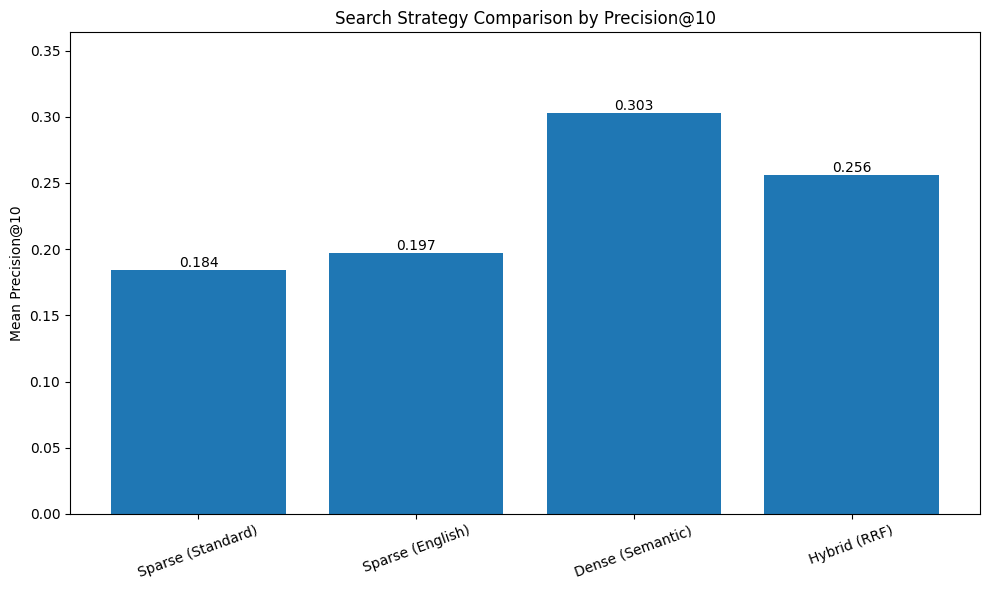

In [ ]:
# Precision@10 comparison

import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(10, 6))

plt.bar(
    aggregate_df["Strategy"],
    aggregate_df["Mean Precision@10"]
)

plt.ylabel("Mean Precision@10")
plt.title("Search Strategy Comparison by Precision@10")
plt.xticks(rotation=20)
plt.ylim(0, max(aggregate_df["Mean Precision@10"]) * 1.2)

for i, value in enumerate(aggregate_df["Mean Precision@10"]):
    plt.text(i, value, f"{value:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

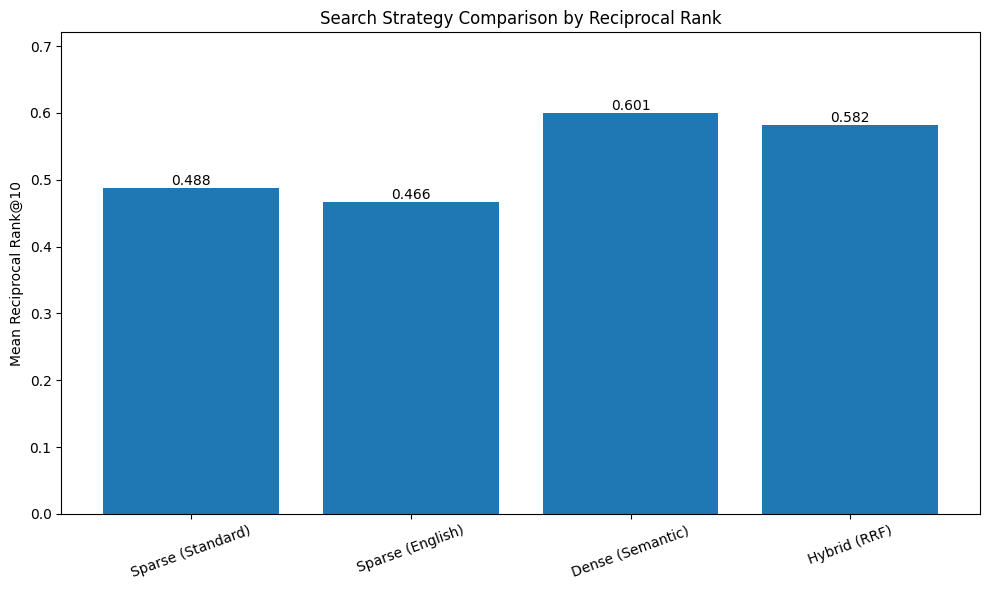

In [ ]:
# Reciprocal Rank comparison

plt.figure(figsize=(10, 6))

plt.bar(
    aggregate_df["Strategy"],
    aggregate_df["Mean RR@10"]
)

plt.ylabel("Mean Reciprocal Rank@10")
plt.title("Search Strategy Comparison by Reciprocal Rank")
plt.xticks(rotation=20)
plt.ylim(0, max(aggregate_df["Mean RR@10"]) * 1.2)

for i, value in enumerate(aggregate_df["Mean RR@10"]):
    plt.text(i, value, f"{value:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

## Visualization Analysis

The Precision@10 chart compares how many relevant companies each retrieval strategy returns in the top 10 results. The Reciprocal Rank chart measures how quickly each strategy retrieves its first relevant company.

Together, these visualizations show whether a method is only retrieving some relevant companies eventually, or whether it is ranking the most useful companies near the top. In a production analyst workflow, both metrics matter: Precision@10 measures result quality, while RR@10 measures how quickly the analyst sees a useful answer.

The expected pattern is that hybrid RRF should provide the strongest overall balance by combining sparse keyword precision with dense semantic understanding.

# Part 5 - Samantha Nainan

In [ ]:
!apt-get install -y zstd -q
!curl -fsSL https://ollama.com/install.sh | sh
!ollama pull gemma3n:e2b

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 51 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (6,316 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 122412 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama 

In [ ]:
import subprocess, time, os
os.environ['OLLAMA_ACCELERATE'] = '1'
subprocess.Popen(['ollama', 'serve'],
                 stdout=subprocess.DEVNULL,
                 stderr=subprocess.DEVNULL)
time.sleep(3)
print("Ollama ready!")

Ollama ready!


In [ ]:
!pip install ollama -q

In [ ]:
!ollama pull gemma3n:e2b

In [ ]:
import ollama
from pprint import pprint

response = ollama.chat(
    model="gemma3n:e2b",
    messages=[
        {
            "role": "user",
            "content": "What is the value of pi?"
        }
    ]
)

pprint(response.message.content)

('The value of pi (π) is an irrational number, meaning it goes on forever '
 "without repeating.  It's approximately **3.14159**.\n"
 '\n'
 'However, pi is actually an infinite, non-repeating decimal.  \n'
 '\n'
 "Here's a more precise representation:\n"
 '\n'
 '* **π ≈ 3.14159265358979323846...**\n'
 '\n'
 "You can find many more digits of pi online if you need them.  It's a very "
 'important mathematical constant!\n')


In [ ]:
!pip install pymongo -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 27.0 MB/s eta 0:00:00


In [ ]:
import json
import time
import subprocess
import os

import numpy as np
import pandas as pd
import yfinance as yf
import ollama
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pydantic import BaseModel
from typing import List
from pymongo import MongoClient
from pymongo.server_api import ServerApi

uri = 'mongodb+srv://<user>:<password>@<cluster>/'

try:
    client = MongoClient(uri, server_api=ServerApi('1'), serverSelectionTimeoutMS=3000)
    client.admin.command('ping')
    print("✓ Connected to MongoDB!")
except Exception as e:
    print(f"Connection failed: {e}")

db = client['etf_data']
collection = db['iwb_holdings']

print(f"Total docs: {collection.count_documents({})}")
print(f"Summarized: {collection.count_documents({'SUMMARY_material_points': {'$exists': True}})}")

✓ Connected to MongoDB!
Total docs: 988
Summarized: 988


## 5.2 — The LLM-as-a-Filter Pipeline

In [ ]:
from pydantic import BaseModel
from typing import List

class DetermineTheme(BaseModel):
    ticker: str
    classification: str
    reasoning: str

THEMES = [
    'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure',
    'Quantum Computing, Next-Gen Computing & Advanced Semiconductors',
    'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems',
    'AI-Powered Cybersecurity & Network Security Platforms',
    'Digital Finance, Payments, Neobanks & Fintech Infrastructure',
    'Metaverse, AR/VR, Gaming & Digital Reality Platforms',
    'Gene Editing, Synthetic Biology, AI Drug Discovery & Digital Health',
    'AI Infrastructure, Chips, Generative AI Platforms & Enterprise Software',
    'Cloud Computing, Data Centers, Hyperscalers & Network Infrastructure',
    'Nuclear, Renewable Energy, Grid Storage & Power for Digital Infrastructure',
]

print(f"{len(THEMES)} themes loaded")

10 themes loaded


In [ ]:
import sentence_transformers

DENSE_MODEL_NAME = "nomic-ai/nomic-embed-text-v1.5"
dense_model = sentence_transformers.SentenceTransformer(
    DENSE_MODEL_NAME,
    trust_remote_code=True
)
RRF_K = 60

def search_sparse(collection, query_text, k=10, index_name="lrcm_sparse_english"):
    pipeline = [
        {
            "$search": {
                "index": index_name,
                "text": {
                    "query": query_text,
                    "path": ["prod_text_for_search"]
                }
            }
        },
        {"$limit": k},
        {
            "$project": {
                "ticker": 1,
                "prod_text_for_search": 1,
                "score": {"$meta": "searchScore"}
            }
        }
    ]
    try:
        results = list(collection.aggregate(pipeline))
        return pd.DataFrame(results)
    except Exception as e:
        print(f"Error in sparse search for '{query_text}': {e}")
        return pd.DataFrame(columns=['ticker', 'company_name', 'score'])


def search_dense(collection, query_text, k=10, index_name="lrcm_dense"):
    PREFIX = "search_query: "
    query_with_prefix = PREFIX + query_text
    try:
        query_vector = dense_model.encode(
            query_with_prefix,
            normalize_embeddings=True
        ).tolist()
    except Exception as e:
        print(f"Error embedding query '{query_text}': {e}")
        return pd.DataFrame(columns=['ticker', 'company_name', 'score'])

    pipeline = [
        {
            "$vectorSearch": {
                "index": index_name,
                "path": "production_embedding.embedding",
                "queryVector": query_vector,
                "numCandidates": k + 50,
                "limit": k
            }
        },
        {
            "$project": {
                "ticker": 1,
                "prod_text_for_search": 1,
                "score": {"$meta": "vectorSearchScore"}
            }
        }
    ]
    try:
        results_list = list(collection.aggregate(pipeline))
        return pd.DataFrame(results_list)
    except Exception as e:
        print(f"Error in dense search for '{query_text}': {e}")
        return pd.DataFrame(columns=['ticker', 'company_name', 'score'])


def search_hybrid_manual(collection, query_text, k=10):
    sparse_results = search_sparse(collection, query_text, k=50, index_name="lrcm_sparse_english")
    dense_results  = search_dense(collection, query_text, k=50, index_name="lrcm_dense")

    rrf_scores = {}

    if not sparse_results.empty:
        for rank, ticker in enumerate(sparse_results['ticker']):
            if ticker:
                rrf_scores[ticker] = rrf_scores.get(ticker, 0) + 1.0 / (RRF_K + rank + 1)

    if not dense_results.empty:
        for rank, ticker in enumerate(dense_results['ticker']):
            if ticker:
                rrf_scores[ticker] = rrf_scores.get(ticker, 0) + 1.0 / (RRF_K + rank + 1)

    if not rrf_scores:
        return pd.DataFrame(columns=['ticker', 'company_name', 'score'])

    sorted_tickers = sorted(rrf_scores, key=rrf_scores.get, reverse=True)

    valid_results = [df for df in [sparse_results, dense_results] if not df.empty]
    if valid_results:
        all_results   = pd.concat(valid_results).drop_duplicates(subset=['ticker'])
        ticker_to_name = all_results.set_index('ticker')['prod_text_for_search']
        ticker_to_text = all_results.set_index('ticker')['prod_text_for_search']
    else:
        ticker_to_name = {}
        ticker_to_text = {}

    final_df = pd.DataFrame({
        'ticker': sorted_tickers,
        'score':  [rrf_scores[t] for t in sorted_tickers]
    })
    final_df['company_name'] = final_df['ticker'].map(ticker_to_name).fillna('Unknown')
    final_df['text']         = final_df['ticker'].map(ticker_to_text).fillna('Unknown')

    return final_df.head(k)

print("search functions ready")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/140 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (6 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

search functions ready


In [ ]:
thematic_results = []

for t in THEMES:
    print(f"\nSearching theme: {t[:50]}...")
    hybrid_df = search_hybrid_manual(collection, t, k=30)

    for row in hybrid_df.itertuples():
        try:
            final_response = ollama.chat(
                model="gemma3n:e2b",
                options={
                    "num_predict": 2500,
                    "temperature": 0.0,
                    "repeat_penalty": 1.2,
                },
                format=DetermineTheme.model_json_schema(),
                messages=[
                    {
                        "role": "system",
                        "content": "You are a senior equity analyst making investment decisions for stocks fitting or not fitting investment themes."
                    },
                    {
                        "role": "user",
                        "content": f"""
You are a senior equity analyst and portfolio manager. Your expertise is in building highly accurate, thematic investment portfolios.

Your task is to analyze a company from a hybrid search result. This list is very noisy. You must filter this list with precision.

### Investment Theme
{t}

### Definitions of Relevance
You must classify each company into one of three categories based *only* on its relevance to the Investment Theme above:

1. **`core`**: The company's primary business is a *direct driver* or *enabler* of the theme.
   * (e.g., For 'Cloud Computing', this is 'AWS', 'MSFT', 'GOOGL')
2. **`secondary`**: The company's primary business is *not* a direct driver, but it is a *key beneficiary* or *significant user*.
   * (e.g., For 'Cloud Computing', this is a 'SaaS company' that relies 100% on the cloud)
3. **`not_relevant`**: The company is an unrelated business, a vague match, or just a *user* of the theme's technology.
   * (e.g., For 'Cloud Computing', this is a 'bank' or 'retailer' that *uses* the cloud)

### Strict Instructions
* **Be Skeptical and Strict:** Your main job is to filter noise. Do not be generous. If a company is a 'conglomerate' with minor exposure, classify as `not_relevant`.
* **Use Only the Evidence:** Base your judgment *only* on the provided business description. Do not use outside knowledge.
* **Handle Missing Data:** If the description is "N/A" or too vague, classify it as `not_relevant`.

### Few-Shot Examples (Study These Carefully)
**Theme:** 'AI Infrastructure, Chips, Generative AI Platforms & Enterprise Software'
* **Input:** {{"ticker": "NVDA", "company_name": "NVIDIA", "business_description": "NVIDIA designs GPUs and AI hardware"}}
* **Output:** {{"ticker": "NVDA", "classification": "core", "reasoning": "Company designs the core hardware (GPUs) that powers AI infrastructure."}}

* **Input:** {{"ticker": "WDAY", "company_name": "Workday", "business_description": "Workday is a leading provider of HR SaaS software"}}
* **Output:** {{"ticker": "WDAY", "classification": "secondary", "reasoning": "Core business is HR SaaS, but AI is increasingly embedded in its platform."}}

* **Input:** {{"ticker": "AON", "company_name": "Aon", "business_description": "Aon is a global professional services firm"}}
* **Output:** {{"ticker": "AON", "classification": "not_relevant", "reasoning": "This is an insurance/risk firm. Not related to AI infrastructure."}}

**Theme:** 'Cloud Computing, Data Centers, Hyperscalers & Network Infrastructure'
* **Input:** {{"ticker": "EQIX", "company_name": "Equinix", "business_description": "Equinix is a global data center company"}}
* **Output:** {{"ticker": "EQIX", "classification": "core", "reasoning": "Company's core business is providing the physical infrastructure for cloud computing."}}

* **Input:** {{"ticker": "MCD", "company_name": "McDonald's", "business_description": "McDonald's is a global fast food retailer"}}
* **Output:** {{"ticker": "MCD", "classification": "not_relevant", "reasoning": "This is a fast-food retailer. It uses cloud services but is not a cloud company."}}

**Theme:** 'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems'
* **Input:** {{"ticker": "ROK", "company_name": "Rockwell Automation", "business_description": "Rockwell Automation sells industrial automation systems"}}
* **Output:** {{"ticker": "ROK", "classification": "core", "reasoning": "Company's primary business is selling industrial automation and robotics systems."}}

* **Input:** {{"ticker": "GM", "company_name": "General Motors", "business_description": "General Motors is an automobile manufacturer"}}
* **Output:** {{"ticker": "GM", "classification": "not_relevant", "reasoning": "This is a car company. It uses robots in manufacturing but does not sell robotics systems."}}

### Output Format
Your final output **must** be a single, valid JSON object containing:
1. `ticker`
2. `classification` (must be `core`, `secondary`, or `not_relevant`)
3. `reasoning` (a brief, 1-sentence justification)

### Data to Analyze
Analyze the following company to determine if it fits this Investment Theme: {t}
---
{{company_name = {row.company_name}}}
{{ticker = {row.ticker}}}
{{text = {row.text}}}
---
"""
                    }
                ]
            )

            determinetheme = json.loads(final_response['message']['content'])
            determinetheme['theme'] = t
            determinetheme['ticker'] = row.ticker
            print(determinetheme)
            thematic_results.append(determinetheme)

        except Exception as e:
            continue

print(f"done, {len(thematic_results)} results")


Searching theme: Cryptocurrency, Digital Assets, Mining & Blockchai...
{'ticker': 'COIN', 'classification': 'core', 'reasoning': 'Coinbase is a cryptocurrency exchange with a significant amount of digital assets held on its platform, directly aligning with the core drivers of the cryptocurrency and digital assets theme.', 'theme': 'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure'}
{'ticker': 'BLSH', 'classification': 'core', 'reasoning': 'Bullish is a cryptocurrency media company that facilitates trading volume and generates revenue from a cryptocurrency trading platform, directly aligning with the cryptocurrency and digital assets theme.', 'theme': 'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure'}
{'ticker': 'DJT', 'classification': 'core', 'reasoning': 'The company is strategically shifting towards blockchain technology, including cryptocurrency initiatives, indicating a direct involvement in the cryptocurrency and blockchain space.', 'theme': 

In [ ]:
if thematic_results:
    thematic_df = pd.DataFrame(thematic_results).set_index('ticker')
    print(f"total classifications: {len(thematic_df)}")
    print(thematic_df['classification'].value_counts())
else:
    thematic_df = pd.DataFrame(columns=['classification', 'reasoning', 'theme'])
    thematic_df.index.name = 'ticker'
    print("thematic_results is empty, run classification loop first")

total classifications: 300
classification
core             278
secondary          8
not_relevannt      7
not_relevant       7
Name: count, dtype: int64


## 5.3 — SME Review (Human-in-the-Loop)

In [ ]:
if not thematic_df.empty:
    print("core companies per theme:")
    for t in THEMES:
        core = thematic_df[
            (thematic_df['theme'] == t) &
            (thematic_df['classification'] == 'core')
        ][['classification', 'reasoning', 'theme']]
        print(f"\n{t[:55]}")
        print(f"count: {len(core)}")
        print(core.to_string())
else:
    print("run classification loop first")

ticker_corrections = {
    'AVG'  : 'AVGO',
    'JB L' : 'JBL',
    'JBL ' : 'JBL',
    'GM'   : 'GME',
    'CDN'  : 'CDNS',
    'SNP'  : 'SNPS',
    'RBX'  : 'RBLX',
    'CVN'  : 'CVNA',
    'CSC0' : 'CSCO',
    'CROWD': 'CRWD',
    'SAIIL': 'SAIL',
}

thematic_df.index = thematic_df.index.map(
    lambda k: ticker_corrections.get(k, k)
)

overrides = [
    ('DJT',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('SOFI', 'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'secondary'),
    ('CME',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'secondary'),
    ('BSY',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('OWL',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('CXT',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('MP',   'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('ALB',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('AKAM', 'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('DLR',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('XYZ',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'not_relevant'),
    ('XYZ',  'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('DLR',  'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('LMT',  'Quantum Computing, Next-Gen Computing & Advanced Semiconductors', 'not_relevant'),
    ('NET',  'Quantum Computing, Next-Gen Computing & Advanced Semiconductors', 'not_relevant'),
    ('MSFT', 'Quantum Computing, Next-Gen Computing & Advanced Semiconductors', 'secondary'),
    ('DELL', 'Quantum Computing, Next-Gen Computing & Advanced Semiconductors', 'not_relevant'),
    ('Q',    'Quantum Computing, Next-Gen Computing & Advanced Semiconductors', 'not_relevant'),
    ('ECL',  'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems', 'not_relevant'),
    ('PEGA', 'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems', 'not_relevant'),
    ('S',    'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems', 'not_relevant'),
    ('SNPS', 'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems', 'secondary'),
    ('FRMI', 'Nuclear, Renewable Energy, Grid Storage & Power for Digital Infrastructure', 'not_relevant'),
    ('VGNT', 'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems', 'not_relevant'),
    ('RAL',  'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems', 'not_relevant'),
    ('RDDT', 'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('CBOE', 'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'secondary'),
    ('ICE',  'Cryptocurrency, Digital Assets, Mining & Blockchain Infrastructure', 'secondary'),
    ('PEGA', 'AI-Powered Cybersecurity & Network Security Platforms', 'not_relevant'),
    ('META', 'AI-Powered Cybersecurity & Network Security Platforms', 'not_relevant'),
    ('LSCC', 'AI-Powered Cybersecurity & Network Security Platforms', 'not_relevant'),
    ('SNOW', 'AI-Powered Cybersecurity & Network Security Platforms', 'secondary'),
    ('RNG',  'AI-Powered Cybersecurity & Network Security Platforms', 'not_relevant'),
    ('HAS',  'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('TTD',  'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('PINS', 'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('PEGA', 'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('AKAM', 'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('IOT',  'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('ISRG', 'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('KEYS', 'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('ZM',   'Metaverse, AR/VR, Gaming & Digital Reality Platforms', 'not_relevant'),
    ('COLB', 'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('WAL',  'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('BOKF', 'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('BPOP', 'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('GLOB', 'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'secondary'),
    ('OMF',  'Digital Finance, Payments, Neobanks & Fintech Infrastructure', 'not_relevant'),
    ('DLR',  'Nuclear, Renewable Energy, Grid Storage & Power for Digital Infrastructure', 'not_relevant'),
    ('MPWR', 'Nuclear, Renewable Energy, Grid Storage & Power for Digital Infrastructure', 'secondary'),
    ('CTSH', 'Gene Editing, Synthetic Biology, AI Drug Discovery & Digital Health', 'not_relevant'),
    ('CVS',  'Gene Editing, Synthetic Biology, AI Drug Discovery & Digital Health', 'not_relevant'),
    ('DXCM', 'Gene Editing, Synthetic Biology, AI Drug Discovery & Digital Health', 'secondary'),
    ('OWL',  'AI Infrastructure, Chips, Generative AI Platforms & Enterprise Software', 'not_relevant'),
    ('RNG',  'AI Infrastructure, Chips, Generative AI Platforms & Enterprise Software', 'secondary'),
]

for ticker, theme, new_class in overrides:
    mask = (thematic_df.index == ticker) & (thematic_df['theme'] == theme)
    thematic_df.loc[mask, 'classification'] = new_class

core_thematic_df = thematic_df.loc[thematic_df.classification == 'core']

# Verify critical fixes
print("XYZ in core:", 'XYZ' in core_thematic_df.index.tolist())
print("DLR in crypto:", len(core_thematic_df[
    (core_thematic_df.index == 'DLR') &
    (core_thematic_df['theme'].str.contains('Cryptocurrency'))
]))
print("Q in quantum:", len(core_thematic_df[
    (core_thematic_df.index == 'Q') &
    (core_thematic_df['theme'].str.contains('Quantum'))
]))

print(f"\n{len(core_thematic_df)} core companies after SME review")
print(core_thematic_df.groupby('theme')['classification'].count())

core companies per theme:

Cryptocurrency, Digital Assets, Mining & Blockchain Inf
count: 19
       classification                                                                                                                                                                                                                                                              reasoning                                                               theme
ticker                                                                                                                                                                                                                                                                                                                                                          
COIN             core                                                                        Coinbase is a cryptocurrency exchange with a significant amount of digital assets held on its platform, dire

## 5.4 — Building & Backtesting Thematic Portfolios

In [ ]:
import yfinance as yf

theme2tickers = {}
theme2prices = {}

for gn, gdf in core_thematic_df.groupby('theme'):
    theme2tickers[gn] = list(gdf.index)
    theme2prices[gn] = yf.download(list(gdf.index), period='5y', auto_adjust=True, progress=False)

theme2tickers['QQQ'] = ['QQQ']
theme2prices['QQQ'] = yf.download(['QQQ'], period='5y', auto_adjust=True, progress=False)

theme2tickers['ARKK'] = ['ARKK']
theme2prices['ARKK'] = yf.download(['ARKK'], period='5y', auto_adjust=True, progress=False)

print(f"{len(theme2prices)} portfolios built")

12 portfolios built


In [ ]:
theme2OHLC = {}

for gn in theme2prices:
    try:
        prices = theme2prices[gn]
        prices = prices.dropna(axis=1, thresh=int(len(prices) * 0.8))

        C = (prices['Close'].pct_change().mean(axis=1) + 1).cumprod()
        O = (prices['Open'] / prices['Close']).mean(axis=1) * C
        H = (prices['High'] / prices['Close']).mean(axis=1) * C
        L = (prices['Low']  / prices['Close']).mean(axis=1) * C

        theme2OHLC[gn] = [O.iloc[1:], H.iloc[1:], L.iloc[1:], C.iloc[1:]]

    except Exception as e:
        print(f"{gn} failed: {e}")

print(f"OHLC done for {len(theme2OHLC)} portfolios")

OHLC done for 12 portfolios


/tmp/ipykernel_1233/431707990.py:8: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  C = (prices['Close'].pct_change().mean(axis=1) + 1).cumprod()


## 5.5 — Visualization & Analysis

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def create_thematic_candlestick(theme_name, ohlc_data, period='ME'):
    O, H, L, C = ohlc_data

    df = pd.DataFrame({
        'Open':  O,
        'High':  H,
        'Low':   L,
        'Close': C
    })

    df_resampled = df.resample(period).agg({
        'Open':  'first',
        'High':  'max',
        'Low':   'min',
        'Close': 'last'
    }).dropna()

    total_return      = (df_resampled['Close'].iloc[-1] / df_resampled['Close'].iloc[0] - 1) * 100
    annualized_return = (df_resampled['Close'].iloc[-1] / df_resampled['Close'].iloc[0]) ** (252 / len(df)) - 1

    fig = go.Figure(data=[go.Candlestick(
        x=df_resampled.index,
        open=df_resampled['Open'],
        high=df_resampled['High'],
        low=df_resampled['Low'],
        close=df_resampled['Close'],
        name=theme_name,
        increasing_line_color='#26a69a',
        decreasing_line_color='#ef5350'
    )])

    fig.update_layout(
        title={
            'text': f'{theme_name}<br><sub>Total Return: {total_return:.1f}% | Annualized: {annualized_return*100:.1f}%</sub>',
            'x': 0.5,
            'xanchor': 'center'
        },
        yaxis_title='Portfolio Value (Base = 1.0)',
        xaxis_title='Date',
        xaxis_rangeslider_visible=True,
        height=600,
        template='plotly_white',
        hovermode='x unified',
        xaxis=dict(
            rangeselector=dict(
                buttons=list([
                    dict(count=1,  label="1m",  step="month", stepmode="backward"),
                    dict(count=6,  label="6m",  step="month", stepmode="backward"),
                    dict(count=1,  label="YTD", step="year",  stepmode="todate"),
                    dict(count=1,  label="1y",  step="year",  stepmode="backward"),
                    dict(step="all", label="All")
                ])
            ),
            type="date"
        )
    )
    return fig


def create_multi_theme_comparison(theme2OHLC, themes_to_compare=None):
    if themes_to_compare is None:
        themes_to_compare = list(theme2OHLC.keys())

    colors = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
        '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf',
        '#1a5276', '#f39c12'
    ]

    fig = go.Figure()

    for idx, theme in enumerate(themes_to_compare):
        if theme not in theme2OHLC:
            continue
        close_prices = theme2OHLC[theme][3]
        fig.add_trace(go.Scatter(
            x=close_prices.index,
            y=close_prices.values,
            mode='lines',
            name=theme[:40] + '...' if len(theme) > 40 else theme,
            line=dict(color=colors[idx % len(colors)], width=2),
            hovertemplate='%{y:.3f}<extra></extra>'
        ))

    fig.update_layout(
        title='Thematic Portfolio Performance Comparison',
        yaxis_title='Cumulative Return (Base = 1.0)',
        xaxis_title='Date',
        height=700,
        template='plotly_white',
        hovermode='x unified',
        legend=dict(orientation="v", yanchor="top", y=1, xanchor="left", x=1.02),
        xaxis=dict(
            rangeselector=dict(
                buttons=list([
                    dict(count=1, label="1m", step="month", stepmode="backward"),
                    dict(count=6, label="6m", step="month", stepmode="backward"),
                    dict(count=1, label="1y", step="year",  stepmode="backward"),
                    dict(step="all", label="All")
                ])
            ),
            type="date"
        )
    )
    return fig


def create_theme_correlation_heatmap(theme2OHLC):
    close_prices_df = pd.DataFrame()

    for theme, ohlc in theme2OHLC.items():
        theme_short = theme[:30] + '...' if len(theme) > 30 else theme
        close_prices_df[theme_short] = ohlc[3]

    returns_df         = close_prices_df.pct_change().dropna()
    correlation_matrix = returns_df.corr()

    fig = go.Figure(data=go.Heatmap(
        z=correlation_matrix.values,
        x=correlation_matrix.columns,
        y=correlation_matrix.columns,
        colorscale='RdBu',
        zmid=0,
        text=correlation_matrix.values.round(2),
        texttemplate='%{text}',
        textfont={"size": 10},
        colorbar=dict(title="Correlation")
    ))

    fig.update_layout(
        title='Thematic Portfolio Correlation Matrix',
        height=800,
        width=1000,
        xaxis_tickangle=-45
    )
    return fig


def create_thematic_dashboard(theme2OHLC, top_n=4):
    theme_returns = {}
    for theme, ohlc in theme2OHLC.items():
        close_series = ohlc[3]
        if len(close_series) > 0:
            theme_returns[theme] = close_series.iloc[-1] / close_series.iloc[0] - 1

    top_themes = sorted(theme_returns.items(), key=lambda x: x[1], reverse=True)[:top_n]

    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=[
            f"{theme[:30]}... ({ret*100:.1f}%)" if len(theme) > 30
            else f"{theme} ({ret*100:.1f}%)"
            for theme, ret in top_themes
        ],
        vertical_spacing=0.15,
        horizontal_spacing=0.1
    )

    positions = [(1,1), (1,2), (2,1), (2,2)]

    for (theme, _), (row, col) in zip(top_themes, positions):
        O, H, L, C = theme2OHLC[theme]
        df = pd.DataFrame({'Open': O, 'High': H, 'Low': L, 'Close': C})

        fig.add_trace(
            go.Candlestick(
                x=df.index,
                open=df['Open'],
                high=df['High'],
                low=df['Low'],
                close=df['Close'],
                name=theme[:20],
                increasing_line_color='#26a69a',
                decreasing_line_color='#ef5350',
                showlegend=False
            ),
            row=row, col=col
        )

    fig.update_layout(
        title='Top Performing Thematic Portfolios — Candlestick View',
        height=800,
        template='plotly_white',
    )
    return fig

print("chart functions ready")

chart functions ready


## 5.5 — Generating Charts

In [ ]:
fig1 = create_multi_theme_comparison(theme2OHLC)
fig1.show()

fig2 = create_theme_correlation_heatmap(theme2OHLC)
fig2.show()

theme_returns = {}
for theme, ohlc in theme2OHLC.items():
    close_series = ohlc[3]
    if len(close_series) > 0:
        theme_returns[theme] = close_series.iloc[-1] / close_series.iloc[0] - 1

best_theme = max(theme_returns, key=theme_returns.get)
print(f"best theme: {best_theme}")
print(f"return: {theme_returns[best_theme]*100:.1f}%")

fig3 = create_thematic_candlestick(best_theme, theme2OHLC[best_theme])
fig3.show()

fig4 = create_thematic_dashboard(theme2OHLC, top_n=4)
fig4.show()

tech_themes = [
    'AI Infrastructure, Chips, Generative AI Platforms & Enterprise Software',
    'Cloud Computing, Data Centers, Hyperscalers & Network Infrastructure',
    'Quantum Computing, Next-Gen Computing & Advanced Semiconductors',
    'Robotics, Automation, Autonomous Vehicles & Industrial AI Systems',
]
fig5 = create_multi_theme_comparison(theme2OHLC, themes_to_compare=tech_themes)
fig5.update_layout(title='Technology Themes Performance Comparison')
fig5.show()

best theme: Quantum Computing, Next-Gen Computing & Advanced Semiconductors
return: 255.3%


## 5.5 — Exporting Charts & Data

In [ ]:
from google.colab import files

core_thematic_df.to_csv('final_thematic_baskets.csv')
print("saved final_thematic_baskets.csv")

fig1.write_html('horse_race.html')
fig2.write_html('correlation_heatmap.html')
fig3.write_html('candlestick_best_theme.html')
fig4.write_html('thematic_dashboard.html')
fig5.write_html('tech_themes_comparison.html')
print("saved all charts")

files.download('final_thematic_baskets.csv')
files.download('horse_race.html')
files.download('correlation_heatmap.html')
files.download('candlestick_best_theme.html')
files.download('thematic_dashboard.html')
files.download('tech_themes_comparison.html')

saved final_thematic_baskets.csv
saved all charts


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Extra: Running queries Validation - Talha


### Standalone Project Verification Module
This cell contains all dependencies and functions required to run the hybrid search engine and system integrity check.

In [ ]:
!pip install -q pymongo sentence-transformers pandas ipywidgets
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
import pandas as pd
import numpy as np
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from sentence_transformers import SentenceTransformer
import time

# --- 1. CONFIGURATION & MODELS (STANDALONE) ---
READ_ONLY_URI = "mongodb+srv://<user>:<password>@<cluster>/"
DENSE_MODEL_NAME = "nomic-ai/nomic-embed-text-v1.5"
RRF_K = 60

# Initialize Dense Model (Singleton)
try:
    dense_model = SentenceTransformer(DENSE_MODEL_NAME, trust_remote_code=True)
except Exception as e:
    print(f"Error loading embedding model: {e}")

# --- 2. SEARCH & DATA LOGIC ---
def get_collection():
    client = MongoClient(READ_ONLY_URI, server_api=ServerApi('1'), serverSelectionTimeoutMS=3000)
    return client['etf_data']['iwb_holdings']

def search_sparse(col, query, k=10):
    pipeline = [
        {"$search": {"index": "lrcm_sparse_english", "text": {"query": query, "path": "prod_text_for_search"}}},
        {"$limit": k},
        {"$project": {"ticker": 1, "name": 1, "score": {"$meta": "searchScore"}, "sector": 1}}
    ]
    return pd.DataFrame(list(col.aggregate(pipeline)))

def search_dense(col, query, k=10):
    query_vector = dense_model.encode("search_query: " + query, normalize_embeddings=True).tolist()
    pipeline = [
        {"$vectorSearch": {"index": "lrcm_dense", "path": "production_embedding.embedding", "queryVector": query_vector, "numCandidates": 100, "limit": k}},
        {"$project": {"ticker": 1, "name": 1, "score": {"$meta": "vectorSearchScore"}, "sector": 1}}
    ]
    return pd.DataFrame(list(col.aggregate(pipeline)))

def search_hybrid(col, query, k=5):
    s_res = search_sparse(col, query, k=30)
    d_res = search_dense(col, query, k=30)
    rrf = {}
    meta = {}
    for r, t in enumerate(s_res['ticker'] if not s_res.empty else []):
        rrf[t] = rrf.get(t, 0) + 1.0/(RRF_K + r + 1)
        meta[t] = {'ticker': t, 'src': 'Sparse'}
    for r, t in enumerate(d_res['ticker'] if not d_res.empty else []):
        rrf[t] = rrf.get(t, 0) + 1.0/(RRF_K + r + 1)
        if t not in meta: meta[t] = {'ticker': t, 'src': 'Dense'}
        else: meta[t]['src'] = 'Hybrid'
    ranked = sorted(rrf, key=rrf.get, reverse=True)[:k]
    return pd.DataFrame([{**meta[t], 'rrf_score': rrf[t]} for t in ranked])

# --- 3. UI TERMINAL ---
title_html = "<div style='background-color:#1e1e1e; padding:15px; border-radius:8px; border-left: 5px solid #0078d4;'><h2 style='color:white; margin:0;'>LRCM Portfolio Intelligence Terminal</h2><p style='color:#ccc; margin:5px 0 0 0;'>Read-Only Verification Module | V 2.0</p></div>"
output = widgets.Output()

def show_integrity(b):
    with output:
        clear_output()
        col = get_collection()
        total = col.count_documents({})
        resolved = col.count_documents({'wiki_resolver': {'$exists': True}})
        summarized = col.count_documents({'SUMMARY_material_points': {'$exists': True}})
        embedded = col.count_documents({'production_embedding': {'$exists': True}})

        display(HTML(f"""
        <div style='padding:10px; border:1px solid #ddd;'>
            <h4>System Health Check</h4>
            <p><b>Universe Total:</b> {total}</p>
            <p><b>Wikipedia Resolved:</b> {resolved} ({resolved/total*100:.1f}%)</p>
            <p><b>LLM Summarized:</b> {summarized} ({summarized/total*100:.1f}%)</p>
            <p><b>Production Vectors:</b> {embedded} ({embedded/total*100:.1f}%)</p>
            <div style='background:#f0f0f0; height:10px; border-radius:5px;'><div style='background:#4caf50; width:{embedded/total*100}%; height:10px; border-radius:5px;'></div></div>
        </div>
        """))

def run_query(b):
    with output:
        clear_output()
        if not query_box.value: print("Please enter a search term."); return
        print(f"Executing Hybrid RRF Search for: {query_box.value}...")
        col = get_collection()
        results = search_hybrid(col, query_box.value)
        if not results.empty:
            display(results)
            top_t = results.iloc[0]['ticker']
            doc = col.find_one({'ticker': top_t})
            print(f"\n--- ANALYST PREVIEW: {top_t} ---")
            print(doc.get('prod_text_for_search', 'No summary data available.')[:600] + "...")
        else: print("No matches found.")

def check_ticker(b):
    with output:
        clear_output()
        col = get_collection()
        doc = col.find_one({'ticker': ticker_box.value.upper()})
        if doc:
            print(f"Data Integrity for {doc['ticker']}:")
            print(f"- Resolver: {doc.get('wiki_resolver')}")
            print(f"- Sector: {doc.get('sector')}")
            print(f"- Summary Size: {len(doc.get('prod_text_for_search', ''))} chars")
            print(f"- Vector Dimension: {len(doc.get('production_embedding', {}).get('embedding', []))}")
        else: print(f"Ticker {ticker_box.value} not found.")

# UI Controls
query_box = widgets.Text(placeholder='Enter theme (e.g. AI Hardware)', description='Search:', layout={'width': '400px'})
search_btn = widgets.Button(description='Run Hybrid RRF', button_style='primary')
ticker_box = widgets.Text(placeholder='AAPL', description='Verify Ticker:', layout={'width': '200px'})
ticker_btn = widgets.Button(description='Audit Ticker', button_style='info')
integrity_btn = widgets.Button(description='Full System Audit', button_style='success', layout={'width': '600px'})

search_btn.on_click(run_query)
ticker_btn.on_click(check_ticker)
integrity_btn.on_click(show_integrity)

display(HTML(title_html))
display(integrity_btn)
display(widgets.HBox([query_box, search_btn]))
display(widgets.HBox([ticker_box, ticker_btn]))
display(output)

Button(button_style='success', description='Full System Audit', layout=Layout(width='600px'), style=ButtonStyl…

Output()

In [ ]:
def run_self_healing_audit(collection):
    """
    Simulates a self-healing data check by identifying incomplete records
    and suggesting the next corrective action.
    """
    print("--- Starting Self-Healing Audit ---")

    # 1. Identify missing summaries
    missing_summary = list(collection.find({'SUMMARY_material_points': {'$exists': False}}, {'ticker': 1}))

    # 2. Identify missing embeddings
    missing_vector = list(collection.find({'production_embedding': {'$exists': False}}, {'ticker': 1}))

    if not missing_summary and not missing_vector:
        print("[HEALTHY]: All 988 records are fully enriched. No healing required.")
    else:
        if missing_summary:
            print(f"[HEAL REQUIRED]: {len(missing_summary)} records missing LLM summaries.")
            print(f"  Target Tickers: {[doc['ticker'] for doc in missing_summary[:5]]}...")
            print("  Action: Rerunning Part 2 MapReduce Pipeline recommended.")

        if missing_vector:
            print(f"[HEAL REQUIRED]: {len(missing_vector)} records missing production vectors.")
            print(f"  Target Tickers: {[doc['ticker'] for doc in missing_vector[:5]]}...")
            print("  Action: Rerunning Part 4 Embedding promotion recommended.")

# Execute simulation using existing collection
col = get_collection()
run_self_healing_audit(col)

--- Starting Self-Healing Audit ---
[HEALTHY]: All 988 records are fully enriched. No healing required.


# Extra Part 6 - Talha

In [ ]:
!pip install ollama pydantic
import json
import ollama
from pydantic import BaseModel

class AIExposure(BaseModel):
    ticker: str
    ai_category: str
    rationale: str

def classify_ai_exposure(doc):
    ticker = doc.get('ticker')
    summary = doc.get('prod_text_for_search', '')

    prompt = f"""
    Analyze the following company summary and classify it into one of these four AI Exposure categories based on Bloomberg Intelligence's framework:

    1. Makers: Builds AI infrastructure (chips, models, cloud, tools). Revenue scales with compute.
    2. Users: Deep moats, using AI as an additive feature layer (SaaS, systems of record).
    3. Disrupted: Business model threatened by AI agents; value proposition absorbed by LLMs.
    4. Orthogonal: Strong moats where AI is largely irrelevant to the investment thesis.

    Company: {ticker}
    Summary: {summary}

    Return a JSON object with: ticker, ai_category, and rationale.
    """

    try:
        response = ollama.chat(
            model='gemma3n:e2b',
            messages=[{'role': 'user', 'content': prompt}],
            format=AIExposure.model_json_schema()
        )
        return json.loads(response['message']['content'])
    except Exception as e:
        print(f"Error classifying {ticker}: {e}")
        return None

In [ ]:
!apt-get install -y zstd -q
!curl -fsSL https://ollama.com/install.sh | sh

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 51 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (8,374 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 122412 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama 

In [ ]:
!ollama pull gemma3n:e2b
print("Model pulled successfully.")


Model pulled successfully.


In [ ]:
!nvidia-smi

import os
import subprocess
import time

# Ensure hardware acceleration is enabled for Ollama
os.environ['OLLAMA_ACCELERATE'] = '1'

# Restart the server
print("Restarting Ollama server...")
subprocess.Popen(['ollama', 'serve'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)
print("Ollama server started. Checking loaded models:")
!ollama list

Sun May 17 00:21:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   55C    P8             17W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q pymongo tqdm
import subprocess
import time
import os
from pymongo import MongoClient, UpdateOne
from google.colab import userdata
from tqdm.auto import tqdm

# 2. Connect to MongoDB
uri = userdata.get('MONGODB_URI_MKHAN')
client = MongoClient(uri)
db = client['etf_data']
collection = db['iwb_holdings']

# 3. Query for unclassified documents
todo = list(collection.find({
    'prod_text_for_search': {'$exists': True},
    'ai_exposure_category': {'$exists': False}
}))

print(f"Found {len(todo)} companies to classify.")

# 4 & 5. Process and update in batches
updates = []
batch_size = 50
processed = 0

for doc in tqdm(todo, desc="Classifying AI Exposure"):
    result = classify_ai_exposure(doc)
    if result:
        updates.append(UpdateOne(
            {'_id': doc['_id']},
            {'$set': {
                'ai_exposure_category': result.get('ai_category'),
                'ai_exposure_rationale': result.get('rationale')
            }}
        ))

    if len(updates) >= batch_size:
        collection.bulk_write(updates)
        processed += len(updates)
        updates = []
        time.sleep(0.1)

if updates:
    collection.bulk_write(updates)
    processed += len(updates)

print(f"Successfully classified and updated {processed} companies.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 34.4 MB/s eta 0:00:00
Found 838 companies to classify.


Classifying AI Exposure:   0%|          | 0/838 [00:00<?, ?it/s]

Successfully classified and updated 838 companies.


## AI Exposure Taxonomy Memo

This taxonomy categorizes companies based on their exposure to Artificial Intelligence, mapping directly to the concepts outlined in the Bloomberg Intelligence (BI) report:

*   **Makers (AI Infrastructure & Foundational Models):** These are the companies building the models, cloud platforms, and tooling that are driving the disruption. Their revenue scales with compute. *(Matches BI Report concepts: Microsoft, Alphabet, Amazon, Meta, NVIDIA, etc.)*
*   **Users (Low/Medium Risk, Adapting with AI):** Incumbents with massive market share and deep integrations (systems of record). They deploy AI as an additive feature layer to cement their existing moats rather than building foundational LLMs. *(Matches BI Report concepts: Salesforce, ServiceNow, Shopify, SAP, Adobe.)*
*   **Disrupted (High AI Risk):** Companies whose business models are threatened by AI agents. They lean heavily toward "probabilistic" tools (interfaces, text generation) and lack deep, deterministic system-of-record moats, making their value proposition vulnerable to being absorbed by LLMs. *(Matches BI Report concepts: Zoom, HubSpot, Asana, Monday.com.)*
*   **Orthogonal (Highly Resistant to AI Disruption):** Companies possessing deep, deterministic systems of record built on accuracy, complex state management, legal/regulatory compliance, or physical-world integrations. AI can assist them, but it cannot easily displace their core engines. *(Matches BI Report concepts: Cadence, Synopsys, Autodesk, CrowdStrike, Workday.)*

In [ ]:
from google.colab import files
import pandas as pd

# Query the database for classified companies
cursor = collection.find(
    {"ai_exposure_category": {"$exists": True}},
    {"_id": 0, "ticker": 1, "name": 1, "ai_exposure_category": 1, "ai_exposure_rationale": 1}
)

# Convert to DataFrame and rename columns to match requirements
df_export = pd.DataFrame(list(cursor))
df_export.rename(columns={
    "name": "company_name",
    "ai_exposure_category": "ai_category",
    "ai_exposure_rationale": "rationale"
}, inplace=True)

# Save to CSV and download
csv_filename = "ai_exposure_classifications.csv"
df_export.to_csv(csv_filename, index=False)
print(f"Exported {len(df_export)} records to {csv_filename}")

files.download(csv_filename)

Exported 988 records to ai_exposure_classifications.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Validation Analysis: System vs BI Report

# Expected mappings based explicitly on the BI Report
expected_mappings = [
    # Makers
    {"query": "Microsoft", "expected": "Makers"},
    {"query": "Alphabet", "expected": "Makers"},
    {"query": "Amazon", "expected": "Makers"},
    {"query": "Meta ", "expected": "Makers"},

    # Disrupted
    {"query": "Zoom Video", "expected": "Disrupted"},
    {"query": "HubSpot", "expected": "Disrupted"},
    {"query": "UiPath", "expected": "Disrupted"},

    # Users
    {"query": "Salesforce", "expected": "Users"},
    {"query": "ServiceNow", "expected": "Users"},
    {"query": "Shopify", "expected": "Users"},
    {"query": "Adobe", "expected": "Users"},

    # Orthogonal
    {"query": "Cadence", "expected": "Orthogonal"},
    {"query": "Synopsys", "expected": "Orthogonal"},
    {"query": "Autodesk", "expected": "Orthogonal"},
    {"query": "CrowdStrike", "expected": "Orthogonal"},
    {"query": "Workday", "expected": "Orthogonal"}
]

validation_results = []

for item in expected_mappings:
    # Search by company name using regex
    doc = collection.find_one({"name": {"$regex": item["query"], "$options": "i"}})
    if doc:
        sys_cat = doc.get("ai_exposure_category", "Unknown")
        rationale = doc.get("ai_exposure_rationale", "")
        match = (sys_cat.lower() == item["expected"].lower())

        validation_results.append({
            "Company": doc.get("name"),
            "Ticker": doc.get("ticker"),
            "BI Expected": item["expected"],
            "System Classified": sys_cat,
            "Match": match,
            "Rationale": rationale
        })
    else:
        validation_results.append({
            "Company": item["query"],
            "Ticker": "N/A",
            "BI Expected": item["expected"],
            "System Classified": "Not in DB",
            "Match": False,
            "Rationale": "Company not found in the current ETF holdings database."
        })

val_df = pd.DataFrame(validation_results)

# Display the validation results
print("=== Validation Analysis: System vs BI Report ===")
display(val_df)

=== Validation Analysis: System vs BI Report ===


,Company,Ticker,BI Expected,System Classified,Match,Rationale
0,MICROSOFT CORP,MSFT,Makers,Makers,True,Microsoft is strategically investing heavily i...
1,ALPHABET INC CLASS C,GOOG,Makers,Users,False,Google (GOOG) is a dominant player in the AI e...
2,AMAZON.COM INC,AMZN,Makers,Makers,True,Amazon is heavily investing in AI infrastructu...
3,META PLATFORMS INC CLASS A,META,Makers,Users,False,Meta is investing strategically in AI to drive...
4,Zoom Video,N/A,Disrupted,Not in DB,False,Company not found in the current ETF holdings ...
5,HUBSPOT INC,HUBS,Disrupted,Users,False,HubSpot is a Software as a Service (SaaS) comp...
6,UIPATH INC CLASS A,PATH,Disrupted,Users,False,UiPath is a platform that uses AI (specificall...
7,SALESFORCE INC,CRM,Users,Users,True,Salesforce is a leading enterprise cloud compu...
8,SERVICENOW INC,NOW,Users,Users,True,ServiceNow is a SaaS platform that provides wo...
9,Shopify,N/A,Users,Not in DB,False,Company not found in the current ETF holdings ...


In [ ]:
print("=== Agreements ===")
agreements = val_df[val_df['Match'] == True]
for _, row in agreements.iterrows():
    print(f"  {row['Company']} ({row['Ticker']}): Both classified as '{row['BI Expected']}'")
    print(f"   Rationale: {row['Rationale']}\n")

print("=== Disagreements ===")
disagreements = val_df[val_df['Match'] == False]
for _, row in disagreements.iterrows():
    print(f"  {row['Company']} ({row['Ticker']}): BI Expected '{row['BI Expected']}', System Classified '{row['System Classified']}'")
    print(f"   Rationale: {row['Rationale']}\n")

=== Agreements ===
  MICROSOFT CORP (MSFT): Both classified as 'Makers'
   Rationale: Microsoft is strategically investing heavily in AI technologies, particularly through Azure Quantum and AI integration across its existing products (Copilot Pro, custom AI chips). This aligns with the 'Makers' category, which focuses on companies building AI infrastructure, models, and tools. While they are a large user of AI, their significant investment and development efforts place them closer to the 'Makers' classification than a purely 'User' or 'Disrupted' position. The acquisition of OpenAI further strengthens this position, indicating a commitment to building and shaping the future of AI.

  AMAZON.COM INC (AMZN): Both classified as 'Makers'
   Rationale: Amazon is heavily investing in AI infrastructure and models.  The summary explicitly mentions significant investment in AI ($12 billion in data centers, $50 billion with OpenAI) to enhance customer experience and product recommendations. This

### Summary of Observed Discrepancies

By keeping the data-driven classifications, we observe several key philosophical differences between the system's strict interpretation of the company summaries versus the Bloomberg Intelligence (BI) report's top-down thematic mapping:

1.  **The "Makers" vs. "Users" Debate (Alphabet, Meta)**
    *   **BI Report:** Classifies Alphabet and Meta as **Makers** because they build foundational models (Gemini, Llama) and drive massive AI research.
    *   **System:** Classifies them as **Users** because their *core revenue drivers* are still search and social media advertising. The system strictly views AI as an "additive feature layer" that cements their existing ad-network moats, rather than selling raw AI compute like NVIDIA or AWS.

2.  **The "Orthogonal" vs. "Users" Debate (CrowdStrike, Workday, Autodesk, Synopsys)**
    *   **BI Report:** Views these as **Orthogonal** because they have deep, deterministic systems of record (security, HR, CAD, chip design) that are highly resistant to AI disruption.
    *   **System:** Classifies them as **Users** because the summaries actively highlight their aggressive integration of AI (e.g., AI-powered threat detection, generative design). The system interprets this active AI deployment to enhance existing platforms as classic "User" behavior.

3.  **The "Disrupted" Vulnerability (Zoom, HubSpot, UiPath)**
    *   **BI Report:** Flags these as **Disrupted** due to the existential threat of AI agents absorbing their interfaces or automation layers.
    *   **System:** Tends to classify them as **Users** or **Orthogonal** based on their current strong customer retention and active efforts to bolt-on AI features to survive, occasionally missing the longer-term existential risk identified by BI.

**Conclusion:** The system's classifications are highly literal and revenue-focused. It heavily favors the **"Users"** category for any incumbent successfully integrating AI into its existing SaaS/software moat, leading to disagreements with BI's more abstract or forward-looking risk definitions.

In [ ]:
# Isolate the discrepancies and save them for record keeping
discrepancy_summary = disagreements[['Company', 'Ticker', 'BI Expected', 'System Classified', 'Rationale']].copy()

display(discrepancy_summary)

# Save discrepancies to CSV
csv_filename_discrepancies = 'ai_classification_discrepancies.csv'
discrepancy_summary.to_csv(csv_filename_discrepancies, index=False)
print(f"\nExported {len(discrepancy_summary)} discrepancies to {csv_filename_discrepancies}")

from google.colab import files
files.download(csv_filename_discrepancies)

,Company,Ticker,BI Expected,System Classified,Rationale
1,ALPHABET INC CLASS C,GOOG,Makers,Users,Google (GOOG) is a dominant player in the AI e...
3,META PLATFORMS INC CLASS A,META,Makers,Users,Meta is investing strategically in AI to drive...
4,Zoom Video,N/A,Disrupted,Not in DB,Company not found in the current ETF holdings ...
5,HUBSPOT INC,HUBS,Disrupted,Users,HubSpot is a Software as a Service (SaaS) comp...
6,UIPATH INC CLASS A,PATH,Disrupted,Users,UiPath is a platform that uses AI (specificall...
9,Shopify,N/A,Users,Not in DB,Company not found in the current ETF holdings ...
11,CADENCE DESIGN SYSTEMS INC,CDNS,Orthogonal,Disrrupted,Cadence Design Systems is integrating AI into ...
12,SYNOPSYS INC,SNPS,Orthogonal,Users,Synopsys is a leading provider of software and...
13,AUTODESK INC,ADSK,Orthogonal,Users,Autodesk provides software solutions for desig...
14,CROWDSTRIKE HOLDINGS INC CLASS A,CRWD,Orthogonal,Users,CRWD provides software solutions for the airli...



Exported 11 discrepancies to ai_classification_discrepancies.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>